# Phân tích xu hướng công nghệ và mức lương lập trình viên
**Nguồn dữ liệu:** Stack Overflow Developer Survey 2025 (49.191 phản hồi, 172 cột).
**Môn học:** CSE702060 – Trực quan hóa dữ liệu, Nhóm 8.

**Đối tượng và mục tiêu:** sau khi xem sản phẩm, sinh viên và lập trình viên mới ở Việt Nam sẽ hiểu
công nghệ nào đang được dùng và ngưỡng mộ, mức lương phụ thuộc vào yếu tố nào, từ đó chọn công nghệ học và đặt kỳ vọng lương hợp lý.

**Cách chạy:** chọn *Run All*. Notebook tự tìm `data/results.csv`, nếu chưa có sẽ tự tải về từ GitHub của Stack Overflow.
Ảnh biểu đồ và bảng số được lưu vào thư mục `out/` để dùng lại cho slide và báo cáo.

**Cấu trúc:** (1) cấu hình và hàm dùng chung, (2) làm sạch dữ liệu, (3) hồ sơ người trả lời (Q1),
(4) xu hướng công nghệ (Q2–Q4), (5) lương (Q5–Q7), (6) so sánh vai trò (Q8), (7) hồi quy kiểm chứng thông điệp (Q6),
(8) AI và kỹ năng tương lai (Q9), (9) tóm tắt.

In [1]:
# Thư viện dùng chung
import json
import re
import textwrap
import warnings
import urllib.request
from dataclasses import asdict, dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")

In [2]:
@dataclass(frozen=True)
class Cfg:
    """Hằng số cấu hình dùng chung cho toàn notebook."""
    results_url: str = "https://github.com/StackExchange/Survey/raw/refs/heads/main/packages/archive/2025/results.csv"
    pro_branch: str = "I am a developer by profession"
    sal_min: int = 1_000
    sal_max: int = 500_000
    min_country_n: int = 30
    min_role_n: int = 200
    min_cell_n: int = 30
    exp_edges: tuple = (0, 2, 5, 10, 20, 200)
    exp_labels: tuple = ("0–2", "3–5", "6–10", "11–20", "21+")
    boot_n: int = 1000
    ci_level: float = 95.0
    seed: int = 42
    top_lang: int = 15
    fig_w: float = 8.0
    fig_h: float = 4.5
    dpi: int = 200
    px_w: int = 1600
    px_h: int = 900


@dataclass(frozen=True)
class Pal:
    """Bảng màu Okabe-Ito an toàn cho người mù màu."""
    accent: str = "#0072B2"
    accent2: str = "#D55E00"
    neutral: str = "#999999"
    light: str = "#D9D9D9"
    cat: tuple = ("#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#F0E442", "#000000")


class Col:
    """Tên cột dùng trong dữ liệu gốc và các cột dẫn xuất."""
    ID = "ResponseId"
    MAIN = "MainBranch"
    AGE = "Age"
    COUNTRY = "Country"
    DEVTYPE = "DevType"
    WORKEXP = "WorkExp"
    SAL_RAW = "ConvertedCompYearly"
    AI = "AISelect"
    REMOTE = "RemoteWork"
    JOBSAT = "JobSat"
    LANG_HAVE = "LanguageHaveWorkedWith"
    LANG_WANT = "LanguageWantToWorkWith"
    LANG_ADM = "LanguageAdmired"
    DB_HAVE = "DatabaseHaveWorkedWith"
    PLAT_HAVE = "PlatformHaveWorkedWith"
    WEB_HAVE = "WebframeHaveWorkedWith"
    AIOPEN = "AIOpen"
    SAL = "salary_usd"
    ISO3 = "iso3"
    EXPBIN = "exp_bin"
    ROLE = "role"
    VALUE = "value"
    RAW = (ID, MAIN, AGE, COUNTRY, DEVTYPE, WORKEXP, SAL_RAW, AI, REMOTE, JOBSAT, LANG_HAVE, LANG_WANT,
           LANG_ADM, DB_HAVE, PLAT_HAVE, WEB_HAVE, AIOPEN)


@dataclass(frozen=True)
class Label:
    """Cặp nhãn gốc và nhãn rút gọn dùng trên biểu đồ."""
    raw: str
    short: str


@dataclass
class Note:
    """Chú giải của một biểu đồ, dùng lại cho slide và báo cáo."""
    code: str
    title: str
    observation: str
    insight: str
    footer: str
    n: int


@dataclass(frozen=True)
class Paths:
    """Các thư mục dữ liệu và kết quả."""
    root: Path
    data: Path
    figs: Path
    tables: Path

    @staticmethod
    def discover() -> "Paths":
        here = Path.cwd().resolve()
        candidates = [here, here.parent, here.parent.parent]
        root = next((c for c in candidates if (c / "data" / "results.csv").exists()), here)
        paths = Paths(root, root / "data", root / "out" / "figs", root / "out" / "tables")
        for folder in (paths.data, paths.figs, paths.tables):
            folder.mkdir(parents=True, exist_ok=True)
        return paths


PATHS = Paths.discover()
TITLE_WRAP = 66
FOOT_WRAP = 150
TITLE_SIZE = 13
FOOT_SIZE = 6.5
THOUSAND_SEP = "."
HALF_EPS = 1e-9
MINUS_SIGN = "−"
DECIMAL_SEP = ","

In [3]:
def fmt_int(value) -> str:
    """Định dạng số nguyên kiểu Việt Nam (dấu chấm phân tách hàng nghìn)."""
    return f"{value + HALF_EPS:,.0f}".replace(",", THOUSAND_SEP)


def fmt_num(value, digits: int = 1) -> str:
    """Định dạng số thập phân kiểu Việt Nam."""
    text = f"{value:,.{digits}f}"
    return text.replace(",", "_").replace(".", DECIMAL_SEP).replace("_", THOUSAND_SEP).replace("-", MINUS_SIGN)


def fmt_pct(value, digits: int = 1) -> str:
    """Định dạng phần trăm kiểu Việt Nam."""
    return fmt_num(value, digits) + "%"


def label_map(labels) -> dict:
    """Chuyển danh sách Label thành từ điển tra cứu."""
    return {label.raw: label.short for label in labels}


def source_line(n: int, filters: str) -> str:
    """Dòng chú thích chân biểu đồ: nguồn, bộ lọc, cỡ mẫu."""
    return f"Nguồn: Stack Overflow Developer Survey 2025. {filters} n = {fmt_int(n)}."


def thousands_axis(ax, axis: str = "x") -> None:
    """Hiển thị số trên trục kiểu Việt Nam (dấu chấm hàng nghìn)."""
    formatter = FuncFormatter(lambda value, _: fmt_int(value))
    (ax.xaxis if axis == "x" else ax.yaxis).set_major_formatter(formatter)


def apply_style() -> None:
    """Thiết lập kiểu chung cho mọi biểu đồ matplotlib."""
    plt.rcParams.update({
        "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
        "grid.color": "#E5E5E5", "axes.axisbelow": True, "font.size": 9, "figure.facecolor": "white",
    })


apply_style()

In [4]:
TOP_MARGIN = 0.80
BOTTOM_MARGIN = 0.15
RIGHT_MARGIN = 0.97


def decorate_fig(fig, note: Note, left: float = 0.18) -> None:
    """Gắn tiêu đề nêu phát hiện, chú thích chân và lề cho một figure matplotlib."""
    fig.suptitle(textwrap.fill(note.title, TITLE_WRAP), x=0.01, ha="left", fontsize=TITLE_SIZE, fontweight="bold")
    fig.text(0.01, 0.012, textwrap.fill(note.footer, FOOT_WRAP), fontsize=FOOT_SIZE, color="#555555", va="bottom")
    fig.subplots_adjust(top=TOP_MARGIN, bottom=BOTTOM_MARGIN, left=left, right=RIGHT_MARGIN)


def new_fig(note: Note, nrows: int = 1, ncols: int = 1, left: float = 0.18, **kwargs):
    """Tạo khung biểu đồ 1600×900 px có tiêu đề nêu phát hiện và chú thích chân."""
    fig, axes = plt.subplots(nrows, ncols, figsize=(Cfg.fig_w, Cfg.fig_h), dpi=Cfg.dpi, **kwargs)
    decorate_fig(fig, note, left)
    return fig, axes


def style_plotly(fig: go.Figure, note: Note) -> go.Figure:
    """Gắn tiêu đề, chú thích chân và kích thước chuẩn cho biểu đồ plotly."""
    fig.update_layout(
        title={"text": "<b>" + textwrap.fill(note.title, TITLE_WRAP).replace("\n", "<br>") + "</b>",
               "x": 0.01, "xanchor": "left", "font": {"size": 22}},
        width=Cfg.px_w, height=Cfg.px_h, paper_bgcolor="white", plot_bgcolor="white",
        margin={"l": 40, "r": 40, "t": 130, "b": 90}, separators=",.",
    )
    fig.add_annotation(text=textwrap.fill(note.footer, FOOT_WRAP).replace("\n", "<br>"), x=0.0, y=-0.08,
                       xref="paper", yref="paper", showarrow=False, xanchor="left", align="left", font={"size": 12, "color": "#555555"})
    return fig


def export_table(table: pd.DataFrame, code: str) -> None:
    """Lưu bảng số của biểu đồ để báo cáo dùng lại."""
    table.to_csv(PATHS.tables / f"{code}.csv", index=False, encoding="utf-8-sig")


BAR_HEIGHT = 0.7
PCT_PAD = 0.4


def annotate_bars_h(ax, values, texts) -> None:
    """Ghi nhãn giá trị ở cuối mỗi cột ngang."""
    for idx, (val, text) in enumerate(zip(values, texts)):
        ax.text(val + PCT_PAD, idx, text, va="center", fontsize=8)


def finish(fig, note: Note) -> None:
    """Lưu ảnh PNG và chú giải JSON, rồi hiển thị biểu đồ kèm nhận xét."""
    path = PATHS.figs / f"{note.code}.png"
    if isinstance(fig, go.Figure):
        fig.write_image(path, width=Cfg.px_w, height=Cfg.px_h)
    else:
        fig.savefig(path, dpi=Cfg.dpi)
        plt.close(fig)
    (PATHS.tables / f"{note.code}_note.json").write_text(json.dumps(asdict(note), ensure_ascii=False, indent=1), encoding="utf-8")
    display(Image(filename=path, width=800))
    display(Markdown(f"**Nhận xét.** {note.observation}\n\n**Insight.** {note.insight}"))

## 1. Làm sạch dữ liệu
Quy tắc cố định để slide, báo cáo và notebook cùng số liệu:
1. Đọc CSV bằng `utf-8-sig` (file có BOM).
2. Bảng lương `df_sal`: giữ lương `ConvertedCompYearly` (USD) trong khoảng 1.000–500.000 USD và chỉ người "I am a developer by profession".
3. Cột chọn nhiều đáp án tách theo dấu `;`; tỷ lệ tính trên số người có trả lời cột đó.
4. Nước chỉ vào so sánh khi có đủ 30 dòng lương; vai trò (`DevType`) cần đủ 200 dòng lương, bỏ nhóm "Other".
5. Kinh nghiệm dùng cột `WorkExp`, chia 5 nhóm (0–2, 3–5, 6–10, 11–20, 21+ năm).

In [5]:
import pycountry

COUNTRY_ALIASES = (
    Label("Iran, Islamic Republic of...", "IRN"), Label("Turkey", "TUR"), Label("Hong Kong (S.A.R.)", "HKG"),
    Label("Republic of Korea", "KOR"), Label("Venezuela, Bolivarian Republic of...", "VEN"),
    Label("Kosovo", "XKX"), Label("Swaziland", "SWZ"), Label("Palestine", "PSE"),
    Label("Congo, Republic of the...", "COG"), Label("Democratic Republic of the Congo", "COD"),
    Label("Micronesia, Federated States of...", "FSM"), Label("Libyan Arab Jamahiriya", "LBY"),
    Label("Cape Verde", "CPV"),
)
COUNTRY_SHORT = (
    Label("United States of America", "United States"),
    Label("United Kingdom of Great Britain and Northern Ireland", "United Kingdom"),
    Label("Republic of Korea", "South Korea"), Label("Viet Nam", "Vietnam"),
    Label("Russian Federation", "Russia"), Label("Democratic Republic of the Congo", "DR Congo"),
    Label("Libyan Arab Jamahiriya", "Libya"), Label("Hong Kong (S.A.R.)", "Hong Kong"),
    Label("United Republic of Tanzania", "Tanzania"), Label("Syrian Arab Republic", "Syria"),
)
ROLE_SHORT = (
    Label("Developer, full-stack", "Full-stack"), Label("Developer, back-end", "Back-end"),
    Label("Architect, software or solutions", "Architect"),
    Label("Developer, desktop or enterprise applications", "Desktop/enterprise"),
    Label("Developer, front-end", "Front-end"), Label("Developer, mobile", "Mobile"),
    Label("Developer, embedded applications or devices", "Embedded"),
    Label("Engineering manager", "Engineering manager"), Label("DevOps engineer or professional", "DevOps"),
    Label("Data engineer", "Data engineer"), Label("AI/ML engineer", "AI/ML engineer"),
    Label("Data scientist", "Data scientist"),
)
VALUE_SHORT = (
    Label("Bash/Shell (all shells)", "Bash/Shell"), Label("Amazon Web Services (AWS)", "AWS"),
    Label("Visual Basic (.Net)", "VB.NET"), Label("Microsoft SQL Server", "SQL Server"),
)
VIETNAM = "Viet Nam"
OTHER_ROLE_PREFIX = "Other"
NO_ISO = "Nomadic"
AI_DAILY = "Yes, I use AI tools daily"
MULTI_SEP = ";"


def short_country(name: str) -> str:
    """Rút gọn tên nước để hiển thị trên biểu đồ."""
    mapped = label_map(COUNTRY_SHORT).get(name)
    return mapped if mapped else name.split(",")[0].replace("...", "").strip()


def short_role(name: str) -> str:
    """Rút gọn tên vai trò để hiển thị trên biểu đồ."""
    return label_map(ROLE_SHORT).get(name, name)


def country_to_iso3(name: str):
    """Đổi tên nước trong khảo sát sang mã ISO-3; trả về None nếu không phải nước."""
    alias = label_map(COUNTRY_ALIASES).get(name)
    if alias or name == NO_ISO:
        return alias
    try:
        return pycountry.countries.lookup(name).alpha_3
    except LookupError:
        return None

In [6]:
def fetch_results() -> Path:
    """Tìm file results.csv ở local, chưa có thì tải từ GitHub."""
    path = PATHS.data / "results.csv"
    if not path.exists():
        urllib.request.urlretrieve(Cfg.results_url, path)
    return path


def load_all() -> pd.DataFrame:
    """Đọc toàn bộ người trả lời, chỉ giữ các cột dùng trong phân tích."""
    return pd.read_csv(fetch_results(), encoding="utf-8-sig", usecols=list(Col.RAW), low_memory=False)


def build_sal(df_all: pd.DataFrame) -> pd.DataFrame:
    """Dựng bảng lương theo quy tắc lọc: lập trình viên chuyên nghiệp, lương hợp lệ."""
    keep = df_all[Col.SAL_RAW].between(Cfg.sal_min, Cfg.sal_max) & (df_all[Col.MAIN] == Cfg.pro_branch)
    sal = df_all.loc[keep].rename(columns={Col.SAL_RAW: Col.SAL}).copy()
    iso_by_name = {name: country_to_iso3(name) for name in sal[Col.COUNTRY].dropna().unique()}
    sal[Col.ISO3] = sal[Col.COUNTRY].map(iso_by_name)
    sal[Col.EXPBIN] = pd.cut(sal[Col.WORKEXP], bins=list(Cfg.exp_edges), labels=list(Cfg.exp_labels))
    sal[Col.ROLE] = sal[Col.DEVTYPE].map(short_role)
    return sal


def explode_multi(df: pd.DataFrame, col: str) -> pd.DataFrame:
    """Tách cột chọn nhiều đáp án thành bảng dạng dài (ResponseId, value)."""
    answered = df[[Col.ID, col]].dropna()
    longer = answered.assign(**{Col.VALUE: answered[col].str.split(MULTI_SEP)}).explode(Col.VALUE)
    longer[Col.VALUE] = longer[Col.VALUE].replace(label_map(VALUE_SHORT))
    return longer[[Col.ID, Col.VALUE]].reset_index(drop=True)


def share_answered(df: pd.DataFrame, col: str):
    """Trả về (tỷ lệ % theo từng đáp án, số người có trả lời) cho cột chọn nhiều đáp án."""
    answered = int(df[col].notna().sum())
    counts = explode_multi(df, col)[Col.VALUE].value_counts()
    return counts / answered * 100, answered


def bootstrap_median_ci(values: np.ndarray, seed: int = Cfg.seed):
    """Khoảng tin cậy bootstrap của median."""
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(values), size=(Cfg.boot_n, len(values)))
    medians = np.median(values[idx], axis=1)
    tail = (100 - Cfg.ci_level) / 2
    return np.percentile(medians, tail), np.percentile(medians, 100 - tail)


def median_table(df: pd.DataFrame, by: str, value: str = Col.SAL, with_ci: bool = True) -> pd.DataFrame:
    """Bảng n, median và khoảng tin cậy của một biến số theo nhóm."""
    rows = []
    for key, grp in df.groupby(by, observed=True):
        vals = grp[value].dropna().to_numpy()
        lo, hi = bootstrap_median_ci(vals) if with_ci and len(vals) > 1 else (np.nan, np.nan)
        rows.append({by: key, "n": len(vals), "median": float(np.median(vals)), "lo": lo, "hi": hi})
    return pd.DataFrame(rows)

In [7]:
df_all = load_all()
df_sal = build_sal(df_all)
roles = [r for r, k in df_sal[Col.ROLE].value_counts().items() if k >= Cfg.min_role_n and not r.startswith(OTHER_ROLE_PREFIX)]
country_n = df_sal[Col.COUNTRY].value_counts()
countries = country_n[country_n >= Cfg.min_country_n].index.tolist()
print(f"Tổng số người trả lời: {fmt_int(len(df_all))} | Bảng lương df_sal: {fmt_int(len(df_sal))} dòng")
print(f"Số nước đủ {Cfg.min_country_n} dòng lương: {len(countries)} | Số vai trò đủ {Cfg.min_role_n} dòng: {len(roles)}")
print(f"Việt Nam có {int(country_n.get(VIETNAM, 0))} dòng lương")
missing_iso = sorted(set(df_sal.loc[df_sal[Col.ISO3].isna(), Col.COUNTRY].dropna()))
print("Nước chưa có mã ISO-3 (bị loại khỏi bản đồ):", missing_iso)

Tổng số người trả lời: 49.191 | Bảng lương df_sal: 19.576 dòng
Số nước đủ 30 dòng lương: 62 | Số vai trò đủ 200 dòng: 12
Việt Nam có 31 dòng lương
Nước chưa có mã ISO-3 (bị loại khỏi bản đồ): ['Nomadic']


In [8]:
# Mức độ thiếu dữ liệu của các cột dùng trong phân tích
fill = (df_all.notna().mean() * 100).round(1).rename("Tỷ lệ có trả lời (%)").to_frame()
fill.index.name = "Cột"
export_table(fill.reset_index(), "t_fill")
display(fill)

,Tỷ lệ có trả lời (%)
Cột,
ResponseId,100.0
MainBranch,100.0
Age,100.0
WorkExp,87.2
DevType,88.8
RemoteWork,68.7
Country,72.0
LanguageHaveWorkedWith,64.4
LanguageWantToWorkWith,55.0


## 2. Q1 – Ai là người trả lời khảo sát?
Mẫu khảo sát tự nguyện nên có thể lệch. Ba biểu đồ dưới đây cho biết người trả lời là ai, bao nhiêu tuổi và sống ở đâu,
để đặt đúng giới hạn cho các kết luận phía sau. Với số lượng phản hồi, ta dùng biểu đồ cột (không dùng bản đồ vì đây là số tuyệt đối).

In [9]:
BRANCH_SHORT = (
    Label("I am a developer by profession", "Lập trình viên chuyên nghiệp"),
    Label("I am not primarily a developer, but I write code sometimes as part of my work/studies", "Viết code thỉnh thoảng"),
    Label("I am learning to code", "Đang học code"),
    Label("I code primarily as a hobby", "Code như sở thích"),
    Label("I used to be a developer by profession, but no longer am", "Từng là lập trình viên"),
    Label("I work with developers or my work supports developers but am not a developer by profession",
          "Làm việc cùng lập trình viên"),
)
AGE_ORDER = ("Under 18 years old", "18-24 years old", "25-34 years old", "35-44 years old", "45-54 years old",
             "55-64 years old", "65 years or older")
AGE_SHORT = (
    Label("Under 18 years old", "<18"), Label("18-24 years old", "18–24"), Label("25-34 years old", "25–34"),
    Label("35-44 years old", "35–44"), Label("45-54 years old", "45–54"), Label("55-64 years old", "55–64"),
    Label("65 years or older", "65+"),
)
TOP_COUNTRIES = 14


def fig_f1_1(df: pd.DataFrame):
    """f1_1: cơ cấu người trả lời theo mức độ gắn với nghề lập trình."""
    counts = df[Col.MAIN].value_counts()
    n = int(counts.sum())
    pct = (counts / n * 100).sort_values()
    names = [label_map(BRANCH_SHORT).get(k, k) for k in pct.index]
    top_name, top_pct = names[-1], pct.iloc[-1]
    note = Note(
        "f1_1", f"{fmt_pct(top_pct, 0)} người trả lời là lập trình viên chuyên nghiệp",
        f"Trong {fmt_int(n)} người trả lời, nhóm '{top_name}' có {fmt_int(counts.max())} người ({fmt_pct(top_pct)}). "
        f"Người đang học code chiếm {fmt_pct(pct[counts.index[counts.index.str.contains('learning')][0]])}.",
        "Phân tích lương chỉ dùng nhóm lập trình viên chuyên nghiệp, nên kết quả không đại diện cho sinh viên mới học.",
        source_line(n, "Toàn bộ người trả lời."), n)
    fig, ax = new_fig(note, left=0.30)
    colors = [Pal.accent if nm == top_name else Pal.neutral for nm in names]
    ax.barh(names, pct.to_numpy(), color=colors, height=BAR_HEIGHT)
    annotate_bars_h(ax, pct.to_numpy(), [fmt_pct(v) for v in pct])
    ax.set_xlabel("Tỷ lệ người trả lời (%)")
    ax.set_xlim(0, pct.max() * 1.15)
    export_table(pct.rename("pct").reset_index(), "f1_1")
    return fig, note


def fig_f1_2(df: pd.DataFrame):
    """f1_2: phân bố người trả lời theo nhóm tuổi."""
    counts = df[Col.AGE].value_counts()
    n = int(counts.sum())
    present = [a for a in AGE_ORDER if a in counts.index]
    pct = (counts[present] / n * 100)
    top_age = pct.idxmax()
    short = label_map(AGE_SHORT)
    note = Note(
        "f1_2", f"Nhóm tuổi {short[top_age]} chiếm {fmt_pct(pct.max(), 0)} người trả lời",
        f"Hai nhóm {short[pct.nlargest(2).index[0]]} và {short[pct.nlargest(2).index[1]]} cộng lại chiếm {fmt_pct(pct.nlargest(2).sum())}. "
        f"Người từ 55 tuổi trở lên chỉ chiếm {fmt_pct(pct[[a for a in present if a.startswith(('55', '65'))]].sum())}.",
        "Mẫu trẻ và đang làm việc, phù hợp với đối tượng sinh viên và lập trình viên mới, nhưng thiếu tiếng nói của người lớn tuổi.",
        source_line(n, "Toàn bộ người trả lời; nhóm 'Prefer not to say' không vẽ nhưng vẫn nằm trong mẫu số."), n)
    fig, ax = new_fig(note, left=0.09)
    colors = [Pal.accent if a == top_age else Pal.neutral for a in present]
    ax.bar([short[a] for a in present], pct.to_numpy(), color=colors)
    for idx, val in enumerate(pct):
        ax.text(idx, val + PCT_PAD, fmt_pct(val), ha="center", fontsize=8)
    ax.set_ylabel("Tỷ lệ người trả lời (%)")
    ax.set_xlabel("Nhóm tuổi")
    export_table(pct.rename("pct").reset_index(), "f1_2")
    return fig, note


def fig_f1_3(df: pd.DataFrame):
    """f1_3: số phản hồi theo nước, Việt Nam được tô màu nhấn phụ."""
    answered = df[Col.COUNTRY].dropna()
    counts = answered.value_counts()
    n = len(answered)
    top = counts.head(TOP_COUNTRIES)
    vn = int(counts.get(VIETNAM, 0))
    top3 = ", ".join(short_country(c) for c in counts.index[:3])
    share3 = counts.head(3).sum() / n * 100
    note = Note(
        "f1_3", f"Mẫu lệch về {top3}; Việt Nam chỉ có {fmt_int(vn)} phản hồi",
        f"Ba nước đầu ({top3}) chiếm {fmt_pct(share3)} trong {fmt_int(n)} người có khai báo nước. "
        f"Việt Nam có {fmt_int(vn)} phản hồi ({fmt_pct(vn / n * 100, 2)}), xếp thứ {int(counts.index.get_loc(VIETNAM)) + 1} trong {len(counts)} nước.",
        "Kết luận về lương và công nghệ chủ yếu phản ánh Mỹ và châu Âu; số liệu Việt Nam chỉ mang tính tham khảo vì mẫu nhỏ.",
        source_line(n, "Người có khai báo nước."), n)
    labels = [short_country(c) for c in top.index] + ["…", short_country(VIETNAM)]
    values = list(top.to_numpy()) + [0, vn]
    fig, ax = new_fig(note, left=0.20)
    colors = [Pal.accent] * len(top) + [Pal.light, Pal.accent2]
    ax.barh(labels[::-1], values[::-1], color=colors[::-1], height=BAR_HEIGHT)
    for idx, val in enumerate(values[::-1]):
        if val:
            ax.text(val + counts.max() * 0.01, idx, fmt_int(val), va="center", fontsize=8)
    ax.set_xlabel("Số phản hồi")
    thousands_axis(ax)
    export_table(counts.rename("count").reset_index(), "f1_3")
    return fig, note

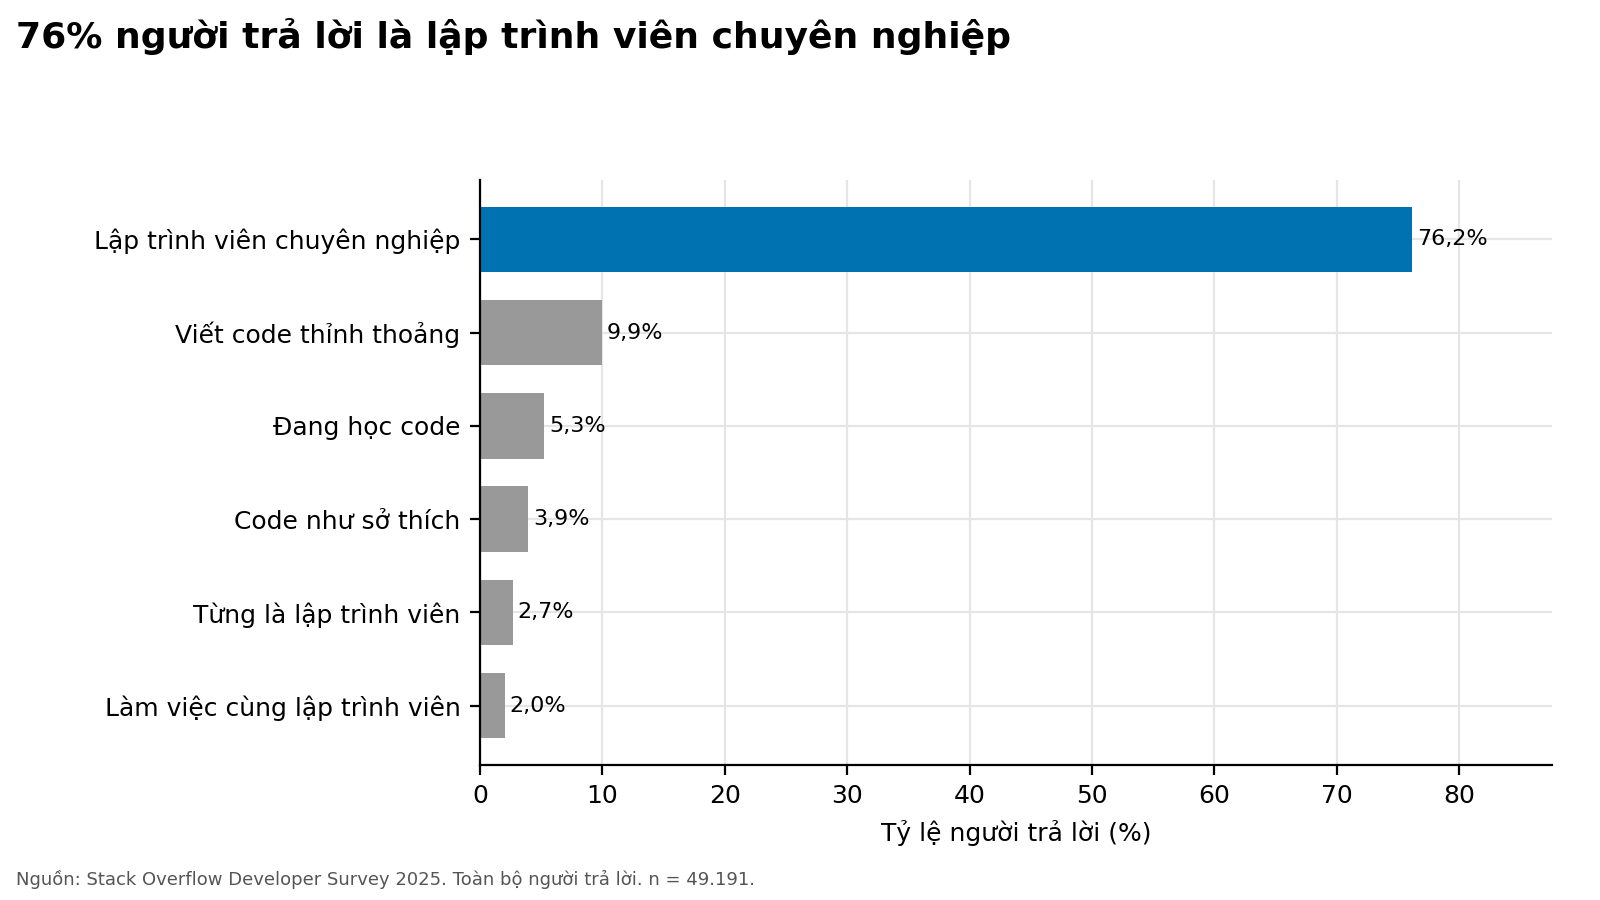

**Nhận xét.** Trong 49.191 người trả lời, nhóm 'Lập trình viên chuyên nghiệp' có 37.467 người (76,2%). Người đang học code chiếm 5,3%.

**Insight.** Phân tích lương chỉ dùng nhóm lập trình viên chuyên nghiệp, nên kết quả không đại diện cho sinh viên mới học.

In [10]:
finish(*fig_f1_1(df_all))

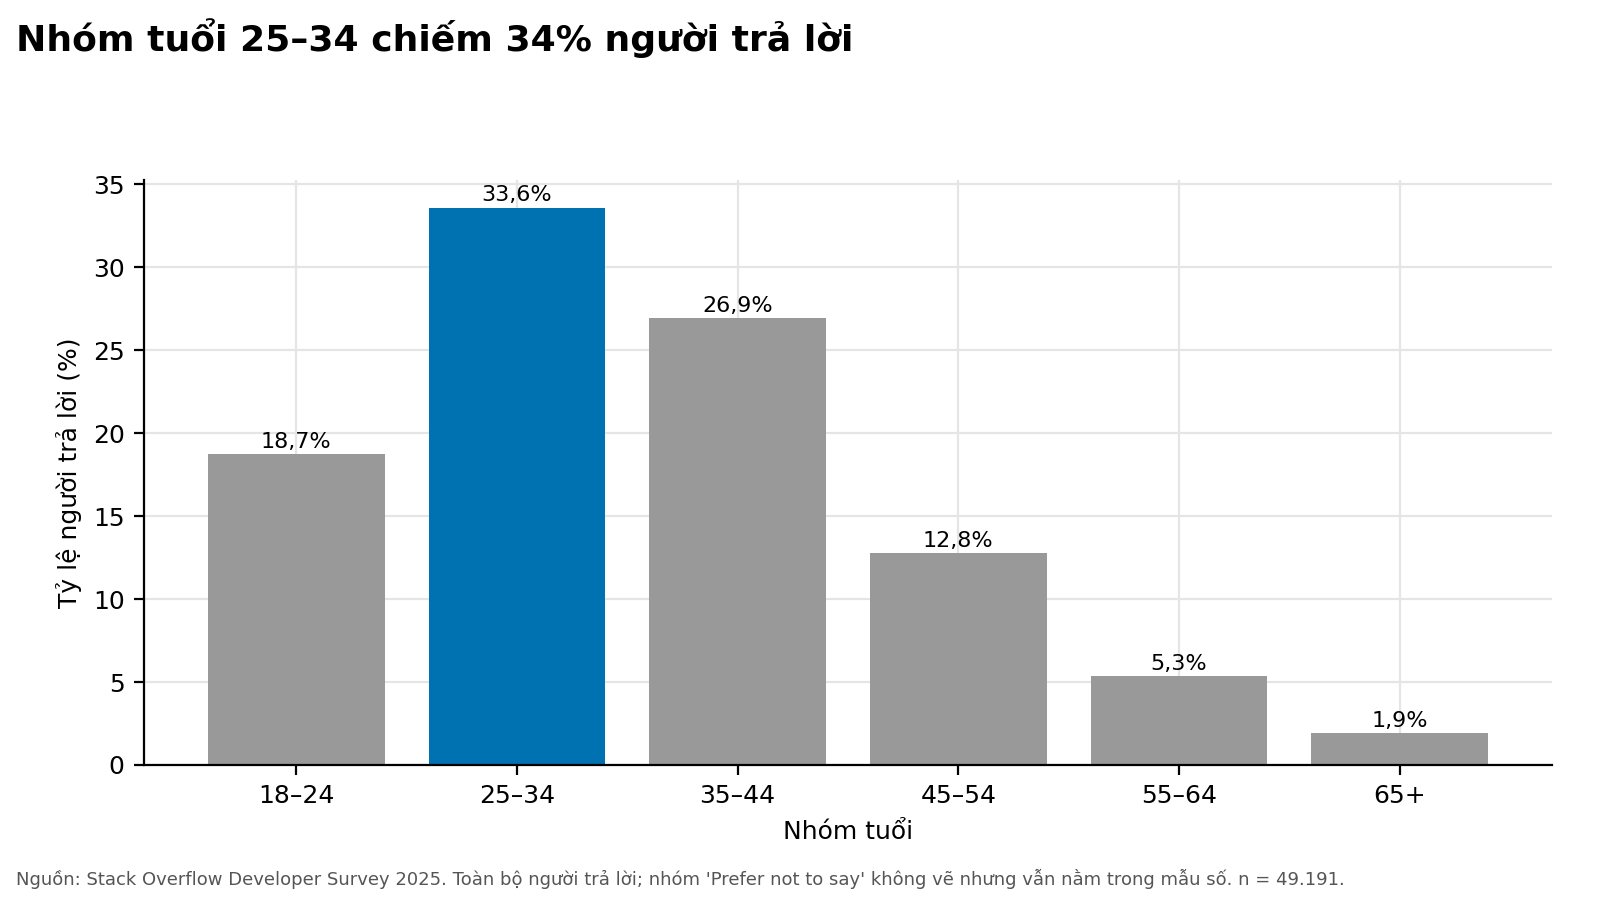

**Nhận xét.** Hai nhóm 25–34 và 35–44 cộng lại chiếm 60,5%. Người từ 55 tuổi trở lên chỉ chiếm 7,3%.

**Insight.** Mẫu trẻ và đang làm việc, phù hợp với đối tượng sinh viên và lập trình viên mới, nhưng thiếu tiếng nói của người lớn tuổi.

In [11]:
finish(*fig_f1_2(df_all))

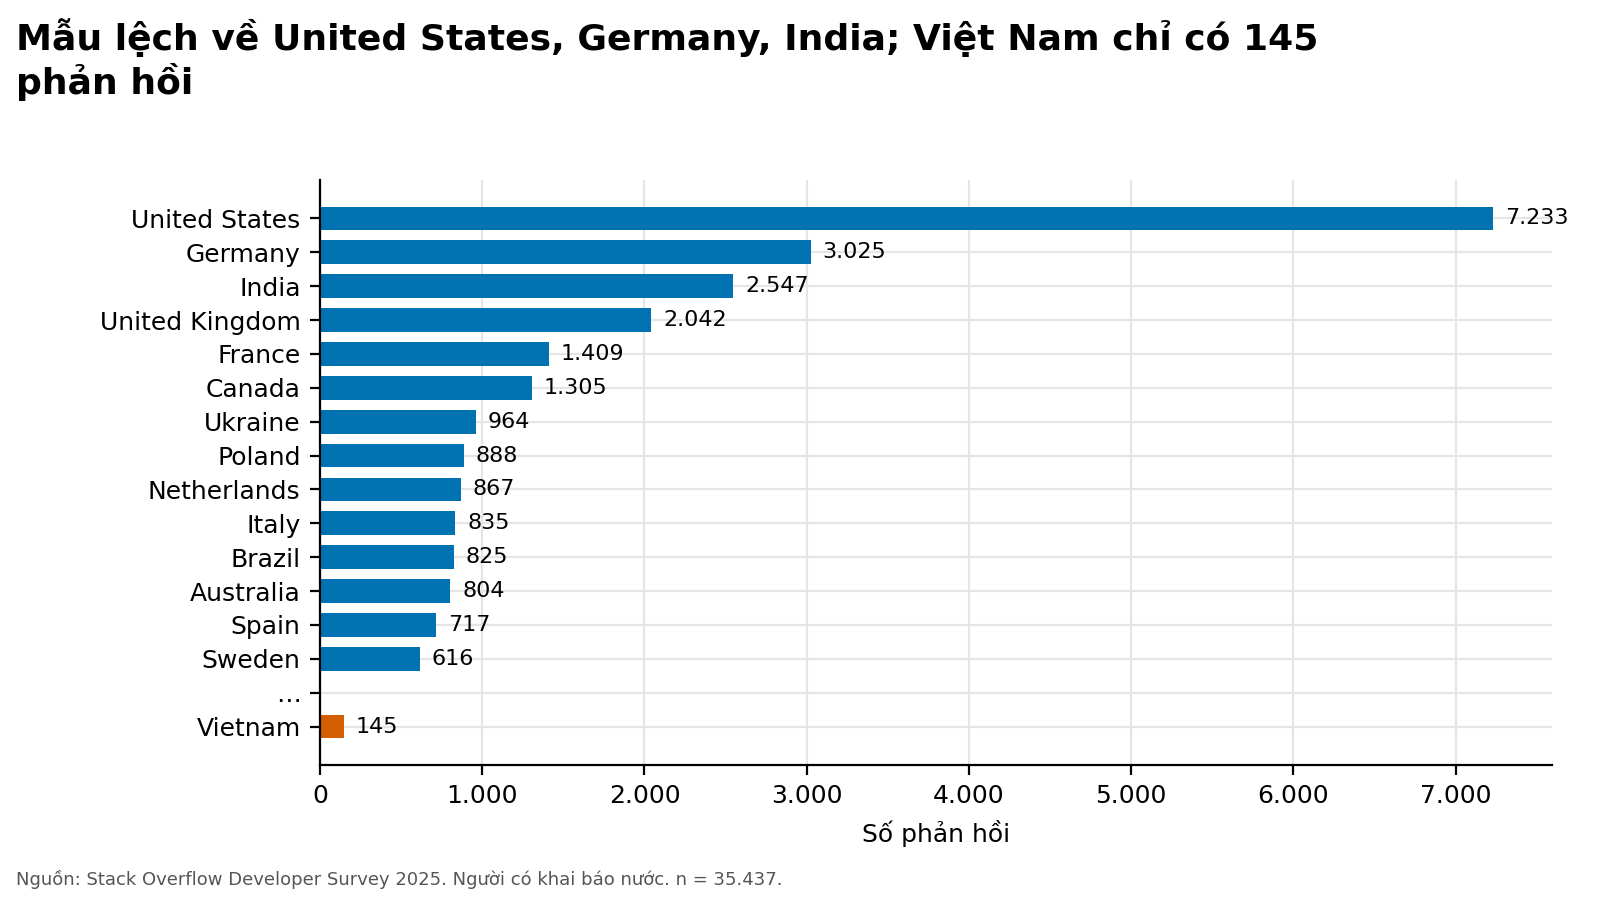

**Nhận xét.** Ba nước đầu (United States, Germany, India) chiếm 36,1% trong 35.437 người có khai báo nước. Việt Nam có 145 phản hồi (0,41%), xếp thứ 46 trong 177 nước.

**Insight.** Kết luận về lương và công nghệ chủ yếu phản ánh Mỹ và châu Âu; số liệu Việt Nam chỉ mang tính tham khảo vì mẫu nhỏ.

In [12]:
finish(*fig_f1_3(df_all))

## 3. Q2–Q4 – Xu hướng công nghệ
Dữ liệu chỉ có năm 2025 nên không đo được thay đổi theo thời gian. Ta dùng ba chỉ số thay thế cho "xu hướng":
**đang dùng** (`HaveWorkedWith`), **muốn dùng** (`WantToWorkWith`) và **được ngưỡng mộ** (`Admired`: trong những người đang dùng, tỷ lệ muốn tiếp tục dùng).
Mẫu số mỗi chỉ số là số người có trả lời cột tương ứng. Với `Admired`, mẫu số là người đang dùng công nghệ đó và có trả lời mục "ngưỡng mộ"
(khoảng 4.600 người đang dùng ngôn ngữ nhưng bỏ trống cả mục "muốn dùng", không đủ cơ sở để coi là "không ngưỡng mộ").

In [13]:
import itertools

import networkx as nx
import plotly.express as px
from networkx.algorithms import community


@dataclass(frozen=True)
class TechGroup:
    """Một nhóm công nghệ: tên hiển thị, cột dữ liệu và màu."""
    name: str
    col: str
    color: str


TECH_GROUPS = (
    TechGroup("Ngôn ngữ", Col.LANG_HAVE, Pal.cat[0]),
    TechGroup("CSDL", Col.DB_HAVE, Pal.cat[1]),
    TechGroup("Cloud và nền tảng", Col.PLAT_HAVE, Pal.cat[2]),
    TechGroup("Web framework", Col.WEB_HAVE, Pal.cat[3]),
)
TOP_BAR = 15
TOP_TREEMAP = 8
TOP_SANKEY = 7
TOP_DIVERGING = 8
EDGE_MIN_SHARE = 2.0
EDGE_MIN_LIFT = 1.5
SANKEY_MIN_SHARE = 45.0
NODE_SIZE_SCALE = 22.0
EDGE_WIDTH_SCALE = 1.2
SPRING_K = 2.0
SCATTER_LABELS = 14
LINK_ALPHA = 0.45
ROOT_KEY = "(?)"


def lang_table(df: pd.DataFrame) -> pd.DataFrame:
    """Bảng % đang dùng, % muốn dùng, % ngưỡng mộ cho từng ngôn ngữ."""
    have_pct, have_n = share_answered(df, Col.LANG_HAVE)
    want_pct, want_n = share_answered(df, Col.LANG_WANT)
    adm_rows = df[df[Col.LANG_ADM].notna()]
    users_adm = explode_multi(adm_rows, Col.LANG_HAVE)[Col.VALUE].value_counts()
    admired = explode_multi(adm_rows, Col.LANG_ADM)[Col.VALUE].value_counts()
    table = pd.DataFrame({"have_pct": have_pct, "want_pct": want_pct})
    table["admired_pct"] = admired / users_adm * 100
    table["users"] = (have_pct * have_n / 100).round().astype(int)
    table["want_gap"] = table.want_pct - table.have_pct
    result = table.dropna().sort_values("have_pct", ascending=False)
    result.attrs["n_have"] = have_n
    return result


lang = lang_table(df_all)

In [14]:
def fig_f2_1(df: pd.DataFrame):
    """f2_1: top ngôn ngữ đang được dùng nhiều nhất."""
    pct, n = share_answered(df, Col.LANG_HAVE)
    top = pct.head(TOP_BAR)[::-1]
    per_person = explode_multi(df, Col.LANG_HAVE).groupby(Col.ID).size().median()
    t3 = list(pct.index[:3])
    note = Note(
        "f2_1", f"{t3[0]}, {t3[1]} và {t3[2]} là ba ngôn ngữ được dùng nhiều nhất",
        f"{t3[0]} có {fmt_pct(pct.iloc[0])} người dùng, {t3[1]} {fmt_pct(pct.iloc[1])}, {t3[2]} {fmt_pct(pct.iloc[2])} (trên {fmt_int(n)} người có trả lời). "
        f"Một người dùng trung bình {fmt_num(per_person, 0)} ngôn ngữ, nên tổng tỷ lệ vượt 100%.",
        "Nhóm ngôn ngữ này có nhiều người dùng nhất trong mẫu, nên là điểm khởi đầu hợp lý cho người mới nếu muốn học cùng công cụ với số đông.",
        source_line(n, f"Người có trả lời mục ngôn ngữ đang dùng, {TOP_BAR} ngôn ngữ đầu."), n)
    fig, ax = new_fig(note, left=0.20)
    ax.barh(top.index, top.to_numpy(), color=[Pal.accent if i >= len(top) - 3 else Pal.neutral for i in range(len(top))], height=BAR_HEIGHT)
    annotate_bars_h(ax, top.to_numpy(), [fmt_pct(v) for v in top])
    ax.set_xlabel("Tỷ lệ người dùng (%)")
    ax.set_xlim(0, top.max() * 1.12)
    export_table(pct.rename("pct").reset_index(), "f2_1")
    return fig, note


def group_counts(df: pd.DataFrame, group: TechGroup) -> pd.DataFrame:
    """Số người dùng từng công nghệ của một nhóm."""
    counts = explode_multi(df, group.col)[Col.VALUE].value_counts().head(TOP_TREEMAP)
    return pd.DataFrame({"group": group.name, "tech": counts.index, "users": counts.to_numpy()})


def fig_f2_2(df: pd.DataFrame):
    """f2_2: treemap hệ sinh thái công nghệ theo nhóm."""
    table = pd.concat([group_counts(df, g) for g in TECH_GROUPS], ignore_index=True)
    leaders = table.groupby("group", sort=False).first()["tech"]
    n = int(df[[g.col for g in TECH_GROUPS]].notna().any(axis=1).sum())
    note = Note(
        "f2_2", f"{leaders.iloc[0]}, {leaders.iloc[1]}, {leaders.iloc[2]} và {leaders.iloc[3]} dẫn đầu từng nhóm công nghệ",
        f"Treemap gồm {len(table)} công nghệ (top {TOP_TREEMAP} mỗi nhóm); diện tích tỷ lệ với số người dùng. "
        f"Người dùng ngôn ngữ lớn nhất ({leaders.iloc[0]}) là {fmt_int(table.users.max())} người.",
        "Mỗi nhóm có một vài công nghệ đứng đầu về số người dùng; người mới có thể ưu tiên các công nghệ này vì có nhiều người dùng nhất trong mẫu.",
        source_line(n, f"Người có trả lời ít nhất một nhóm công nghệ; top {TOP_TREEMAP} mỗi nhóm; diện tích tính theo số người dùng, không so trực tiếp giữa các nhóm."), n)
    colors = {g.name: g.color for g in TECH_GROUPS} | {ROOT_KEY: "#FFFFFF"}
    fig = px.treemap(table, path=[px.Constant("Công nghệ"), "group", "tech"], values="users", color="group", color_discrete_map=colors)
    fig.update_traces(texttemplate="%{label}<br>%{value:,.0f}", textfont={"size": 20}, marker_line_width=2)
    export_table(table, "f2_2")
    return style_plotly(fig, note), note


def fig_f2_3(df: pd.DataFrame):
    """f2_3: top công nghệ trong CSDL, nền tảng và web framework (tỷ lệ %)."""
    groups = TECH_GROUPS[1:]
    results = [share_answered(df, g.col) for g in groups]
    leaders = [pct.index[0] for pct, _ in results]
    tops = [pct.iloc[0] for pct, _ in results]
    note = Note(
        "f2_3", f"{leaders[0]}, {leaders[1]} và {leaders[2]} dẫn đầu CSDL, cloud và web framework",
        "; ".join(f"{g.name}: {pct.index[0]} {fmt_pct(pct.iloc[0])} (n = {fmt_int(n)})" for g, (pct, n) in zip(groups, results)) + ".",
        f"Công nghệ đứng đầu mỗi nhóm có tỷ lệ dùng từ {fmt_pct(min(tops), 0)} đến {fmt_pct(max(tops), 0)}; vì người trả lời chọn nhiều đáp án, đây là tỷ lệ người dùng chứ không phải thị phần.",
        source_line(sum(n for _, n in results), f"Top {TOP_TREEMAP} mỗi nhóm; mẫu số là số người trả lời từng nhóm (n cộng của 3 nhóm)."),
        sum(n for _, n in results))
    fig, axes = new_fig(note, ncols=3, left=0.12, sharex=False)
    fig.subplots_adjust(wspace=0.95)
    for ax, group, (pct, _) in zip(axes, groups, results):
        top = pct.head(TOP_TREEMAP)[::-1]
        ax.barh(top.index, top.to_numpy(), color=group.color, height=BAR_HEIGHT)
        ax.set_title(group.name, fontsize=9, loc="left")
        ax.tick_params(axis="y", labelsize=7)
        annotate_bars_h(ax, top.to_numpy(), [fmt_pct(v, 0) for v in top])
        ax.set_xlim(0, top.max() * 1.25)
    export_table(pd.concat([pct.head(TOP_TREEMAP).rename("pct").reset_index().assign(group=g.name) for g, (pct, _) in zip(groups, results)]), "f2_3")
    return fig, note

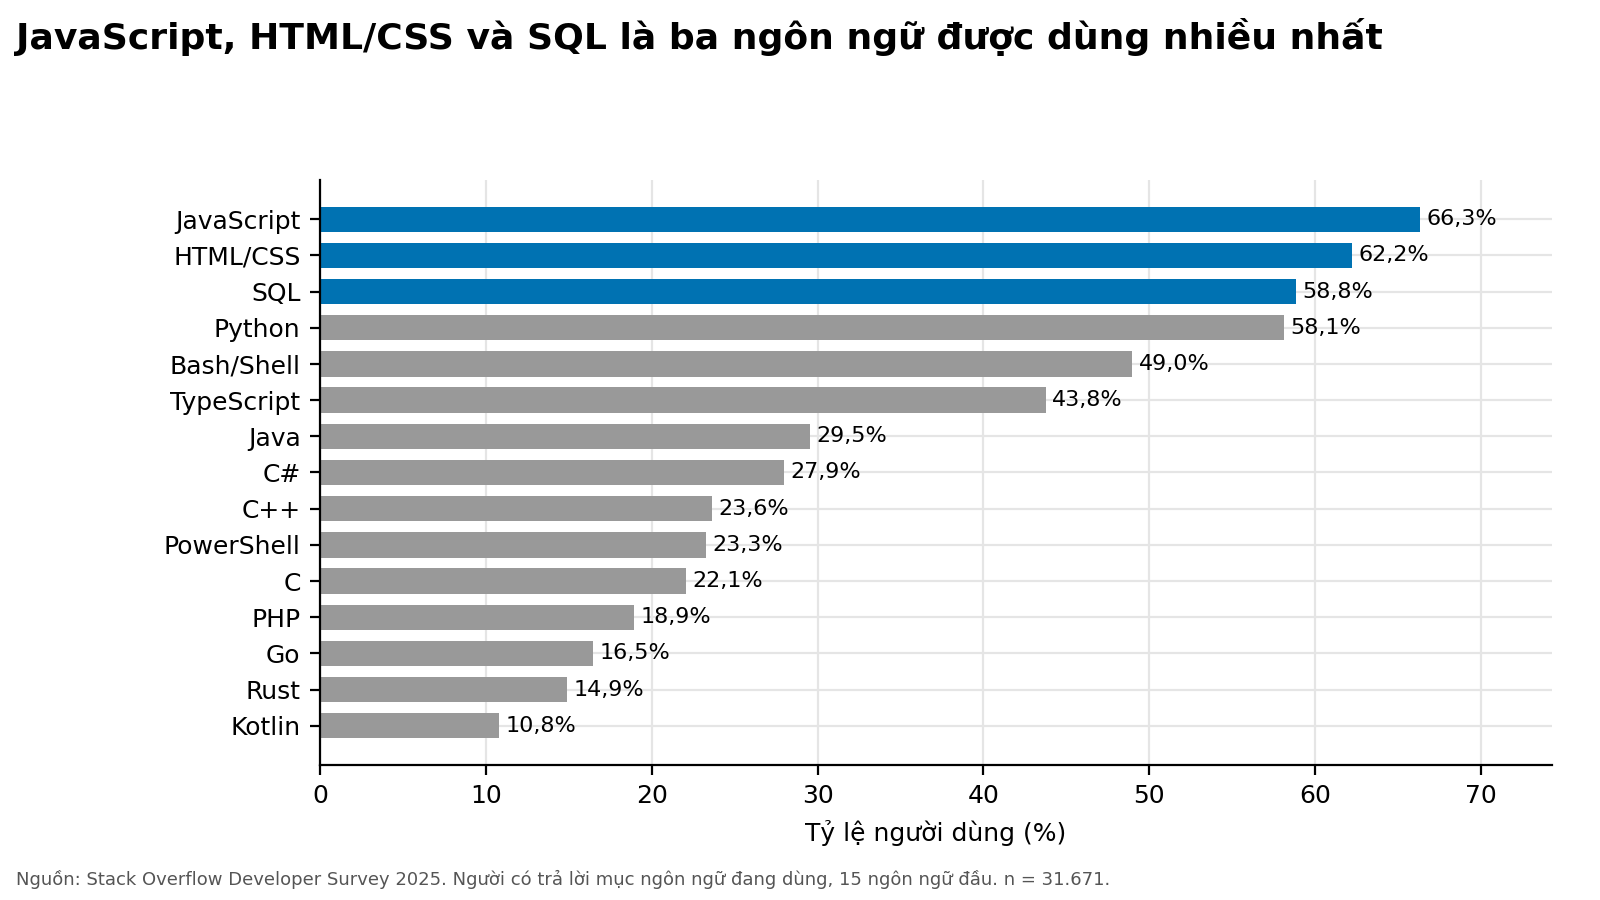

**Nhận xét.** JavaScript có 66,3% người dùng, HTML/CSS 62,2%, SQL 58,8% (trên 31.671 người có trả lời). Một người dùng trung bình 6 ngôn ngữ, nên tổng tỷ lệ vượt 100%.

**Insight.** Nhóm ngôn ngữ này có nhiều người dùng nhất trong mẫu, nên là điểm khởi đầu hợp lý cho người mới nếu muốn học cùng công cụ với số đông.

In [15]:
finish(*fig_f2_1(df_all))

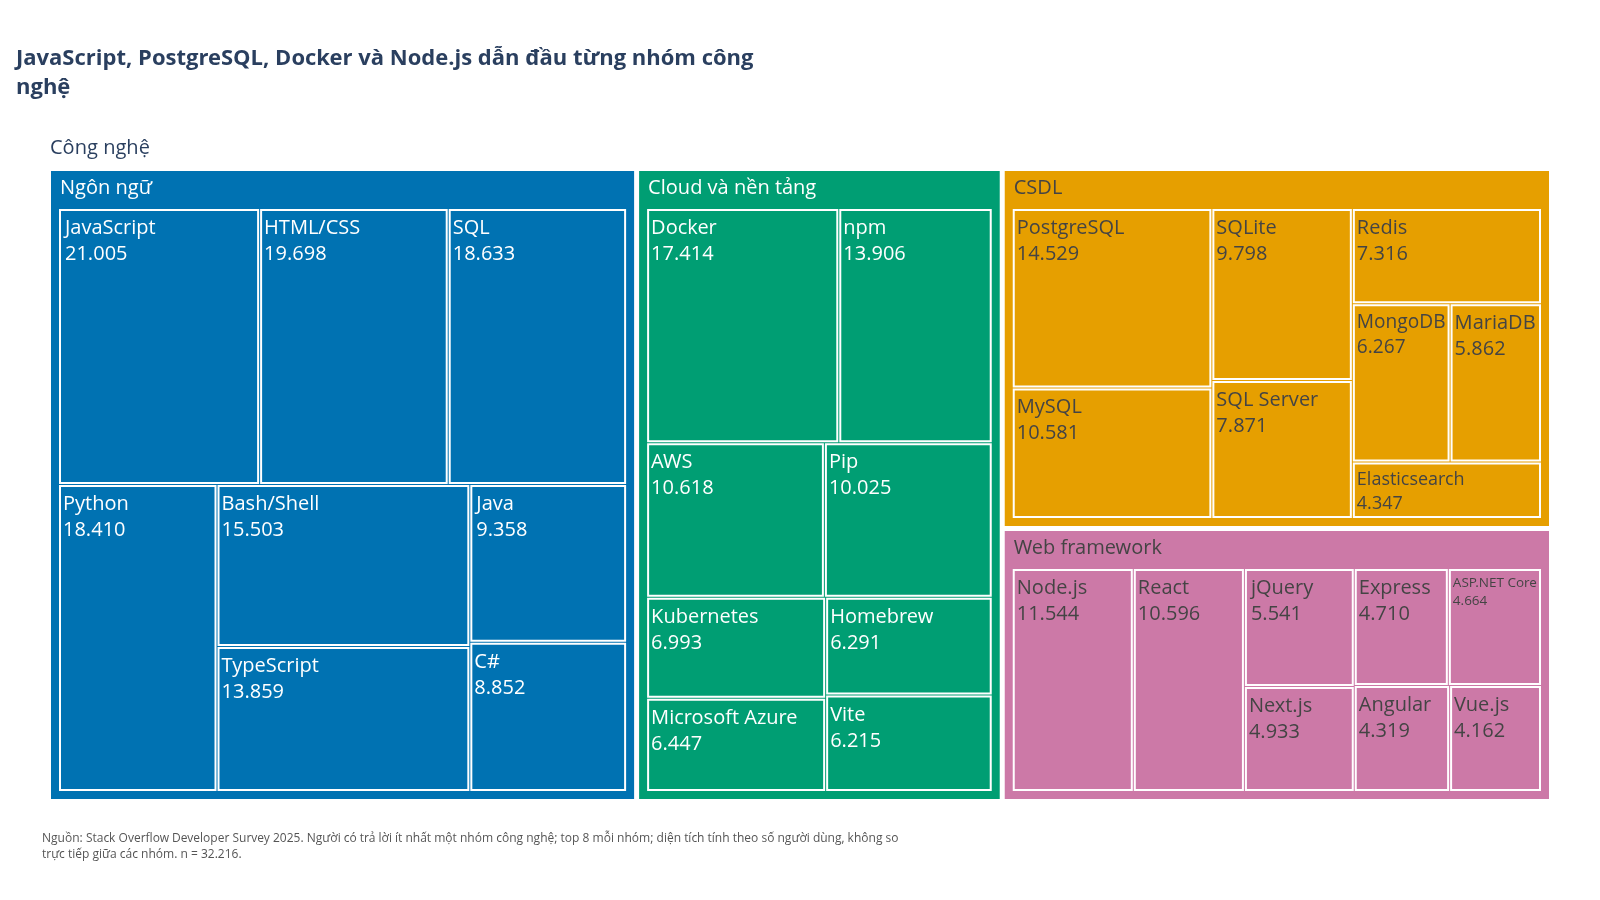

**Nhận xét.** Treemap gồm 32 công nghệ (top 8 mỗi nhóm); diện tích tỷ lệ với số người dùng. Người dùng ngôn ngữ lớn nhất (JavaScript) là 21.005 người.

**Insight.** Mỗi nhóm có một vài công nghệ đứng đầu về số người dùng; người mới có thể ưu tiên các công nghệ này vì có nhiều người dùng nhất trong mẫu.

In [16]:
finish(*fig_f2_2(df_all))

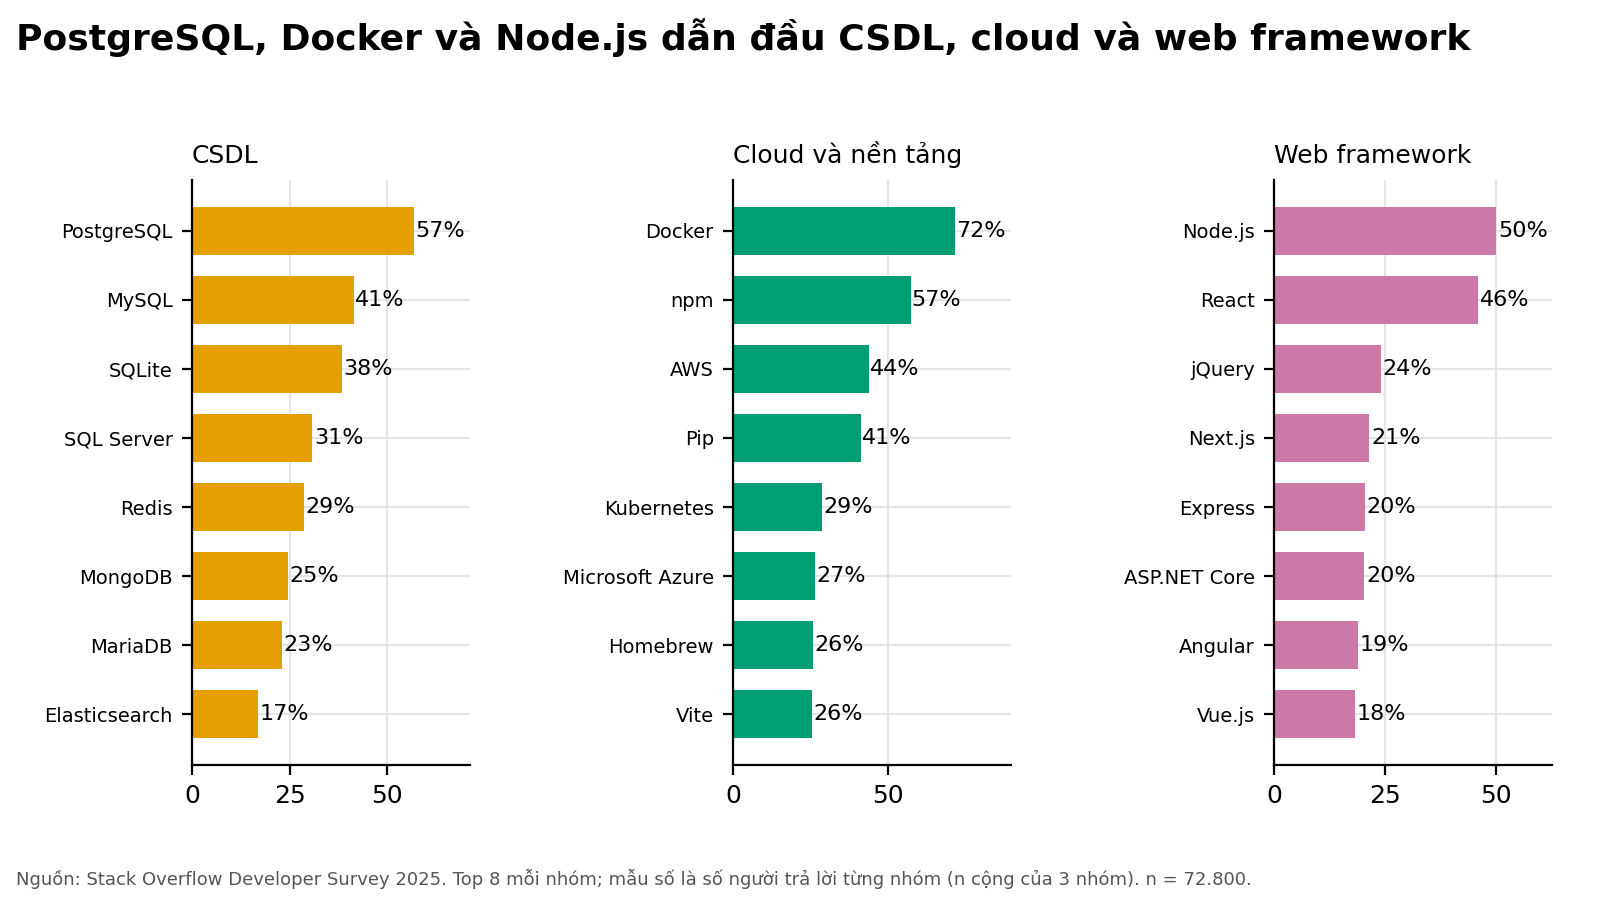

**Nhận xét.** CSDL: PostgreSQL 56,9% (n = 25.550); Cloud và nền tảng: Docker 71,8% (n = 24.258); Web framework: Node.js 50,2% (n = 22.992).

**Insight.** Công nghệ đứng đầu mỗi nhóm có tỷ lệ dùng từ 50% đến 72%; vì người trả lời chọn nhiều đáp án, đây là tỷ lệ người dùng chứ không phải thị phần.

In [17]:
finish(*fig_f2_3(df_all))

### Q3 – Dùng nhiều có được ngưỡng mộ nhiều không?
Mỗi điểm là một ngôn ngữ. Trục ngang: % người dùng. Trục dọc: % ngưỡng mộ (tỷ lệ người đang dùng muốn tiếp tục dùng).

In [18]:
def fig_f3_1(table: pd.DataFrame):
    """f3_1: quan hệ giữa mức dùng và mức ngưỡng mộ của từng ngôn ngữ."""
    most_adm, most_used = table.admired_pct.idxmax(), table.have_pct.idxmax()
    corr = table.have_pct.corr(table.admired_pct, method="spearman")
    note = Note(
        "f3_1", f"{most_used} dùng nhiều nhất nhưng chỉ {fmt_pct(table.admired_pct[most_used], 0)} ngưỡng mộ; {most_adm} đạt {fmt_pct(table.admired_pct.max(), 0)}",
        f"Trong {len(table)} ngôn ngữ, hệ số tương quan hạng Spearman giữa mức dùng và mức ngưỡng mộ là {fmt_num(corr, 2)}. "
        f"{most_adm} được ngưỡng mộ nhất ({fmt_pct(table.admired_pct.max())}), trong khi ngưỡng mộ thấp nhất là {table.admired_pct.idxmin()} ({fmt_pct(table.admired_pct.min())}).",
        "Mức dùng cao không đảm bảo ngưỡng mộ cao; chọn ngôn ngữ nên cân nhắc cả mức phổ biến (dùng nhiều) lẫn mức hài lòng của người đang dùng (ngưỡng mộ).",
        source_line(table.attrs["n_have"], "Mỗi điểm là một ngôn ngữ; ngưỡng mộ tính trên người đang dùng ngôn ngữ đó và có trả lời mục ngưỡng mộ; đường nét đứt là median."),
        table.attrs["n_have"])
    fig, ax = new_fig(note, left=0.08)
    ax.scatter(table.have_pct, table.admired_pct, s=40, color=Pal.accent, alpha=0.85)
    labelled = set(table.nlargest(SCATTER_LABELS // 2, "have_pct").index) | set(table.nlargest(SCATTER_LABELS // 2, "admired_pct").index)
    for name in labelled:
        ax.annotate(name, (table.have_pct[name], table.admired_pct[name]), xytext=(4, 3), textcoords="offset points", fontsize=7)
    ax.axhline(table.admired_pct.median(), color=Pal.neutral, linestyle="--", linewidth=0.8)
    ax.axvline(table.have_pct.median(), color=Pal.neutral, linestyle="--", linewidth=0.8)
    ax.set_xlabel("Tỷ lệ người đang dùng (%)")
    ax.set_ylabel("Tỷ lệ ngưỡng mộ (%)")
    ax.set_xlim(right=table.have_pct.max() * 1.15)
    export_table(table.reset_index().rename(columns={"index": "lang"}), "f3_1")
    return fig, note


def fig_f3_2(table: pd.DataFrame):
    """f3_2: chênh lệch giữa mức muốn dùng và mức đang dùng."""
    gap = table.want_gap.sort_values()
    picked = pd.concat([gap.head(TOP_DIVERGING), gap.tail(TOP_DIVERGING)])
    up, down = gap.index[-1], gap.index[0]
    note = Note(
        "f3_2", f"{up} được muốn dùng vượt mức đang dùng {fmt_num(gap.iloc[-1])} điểm %, {down} thấp hơn {fmt_num(abs(gap.iloc[0]))} điểm %",
        f"Ngôn ngữ có mức muốn dùng cao hơn mức đang dùng nhiều nhất: {', '.join(gap.index[::-1][:3])}. "
        f"Ngôn ngữ mà mức muốn dùng thấp hơn mức đang dùng nhiều nhất: {', '.join(gap.index[:3])}.",
        "Đây là chỉ số thay thế cho xu hướng: ngôn ngữ có chênh lệch dương lớn đang được người dùng kỳ vọng nhiều hơn so với mức dùng hiện tại.",
        source_line(table.attrs["n_have"], f"Chênh lệch = % muốn dùng trừ % đang dùng (điểm phần trăm); {TOP_DIVERGING} ngôn ngữ cao nhất và thấp nhất."),
        table.attrs["n_have"])
    fig, ax = new_fig(note, left=0.18)
    ax.barh(picked.index, picked.to_numpy(), color=[Pal.accent if v > 0 else Pal.accent2 for v in picked], height=BAR_HEIGHT)
    for idx, val in enumerate(picked):
        ax.text(val + (0.3 if val > 0 else -0.3), idx, fmt_num(val), va="center", ha="left" if val > 0 else "right", fontsize=8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Muốn dùng trừ đang dùng (điểm %)")
    ax.margins(x=0.1)
    export_table(gap.rename("want_gap").reset_index(), "f3_2")
    return fig, note

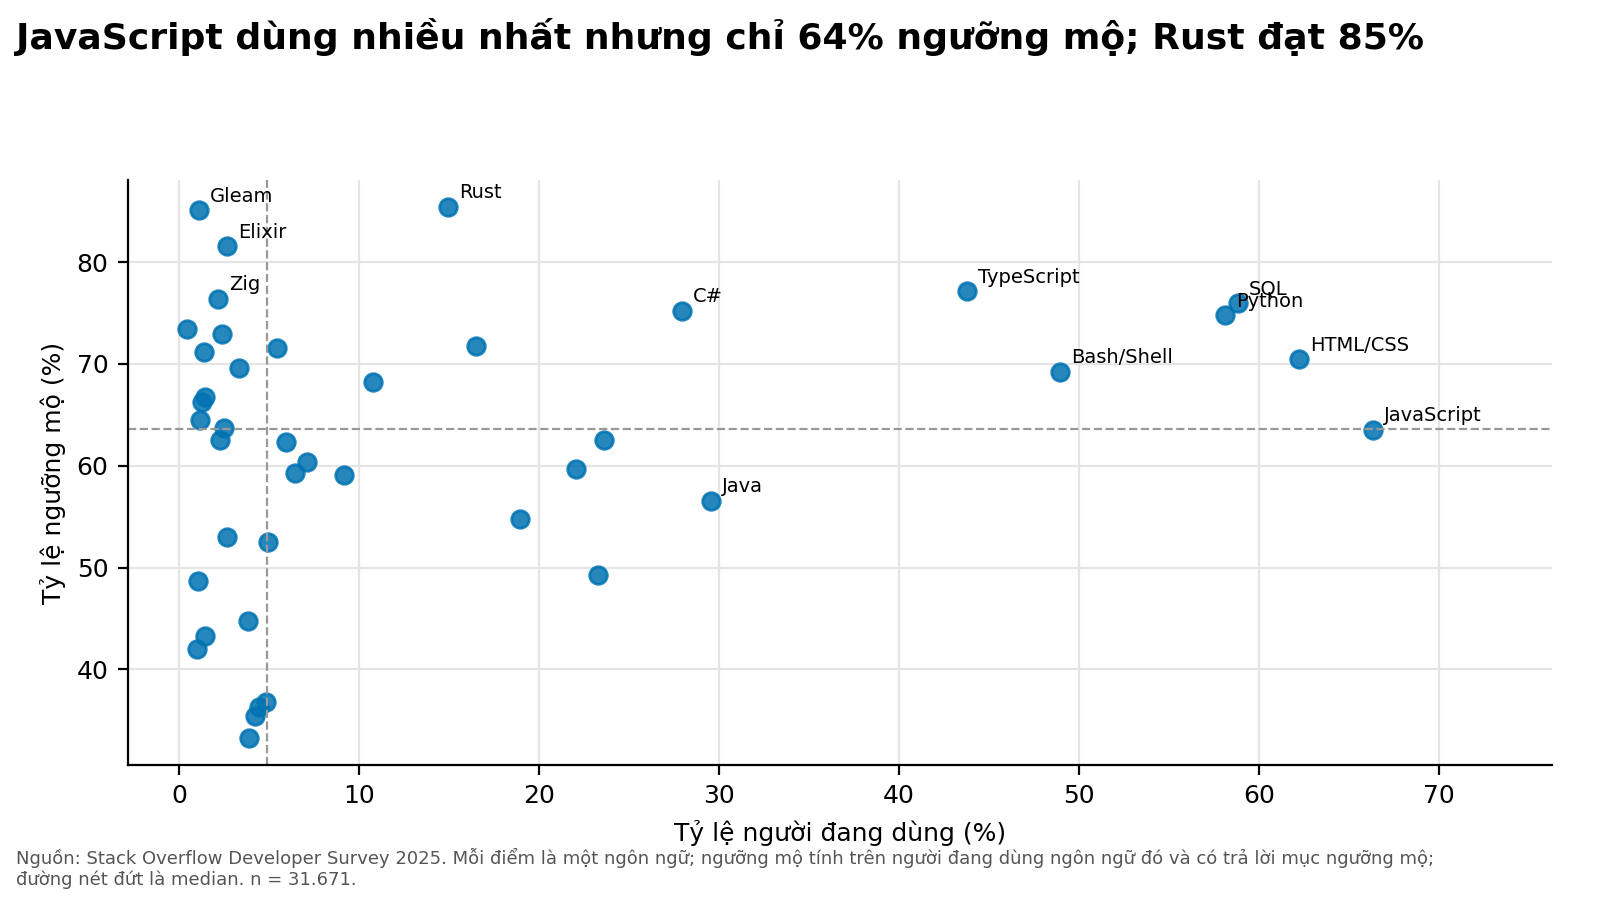

**Nhận xét.** Trong 42 ngôn ngữ, hệ số tương quan hạng Spearman giữa mức dùng và mức ngưỡng mộ là 0,12. Rust được ngưỡng mộ nhất (85,4%), trong khi ngưỡng mộ thấp nhất là MATLAB (33,2%).

**Insight.** Mức dùng cao không đảm bảo ngưỡng mộ cao; chọn ngôn ngữ nên cân nhắc cả mức phổ biến (dùng nhiều) lẫn mức hài lòng của người đang dùng (ngưỡng mộ).

In [19]:
finish(*fig_f3_1(lang))

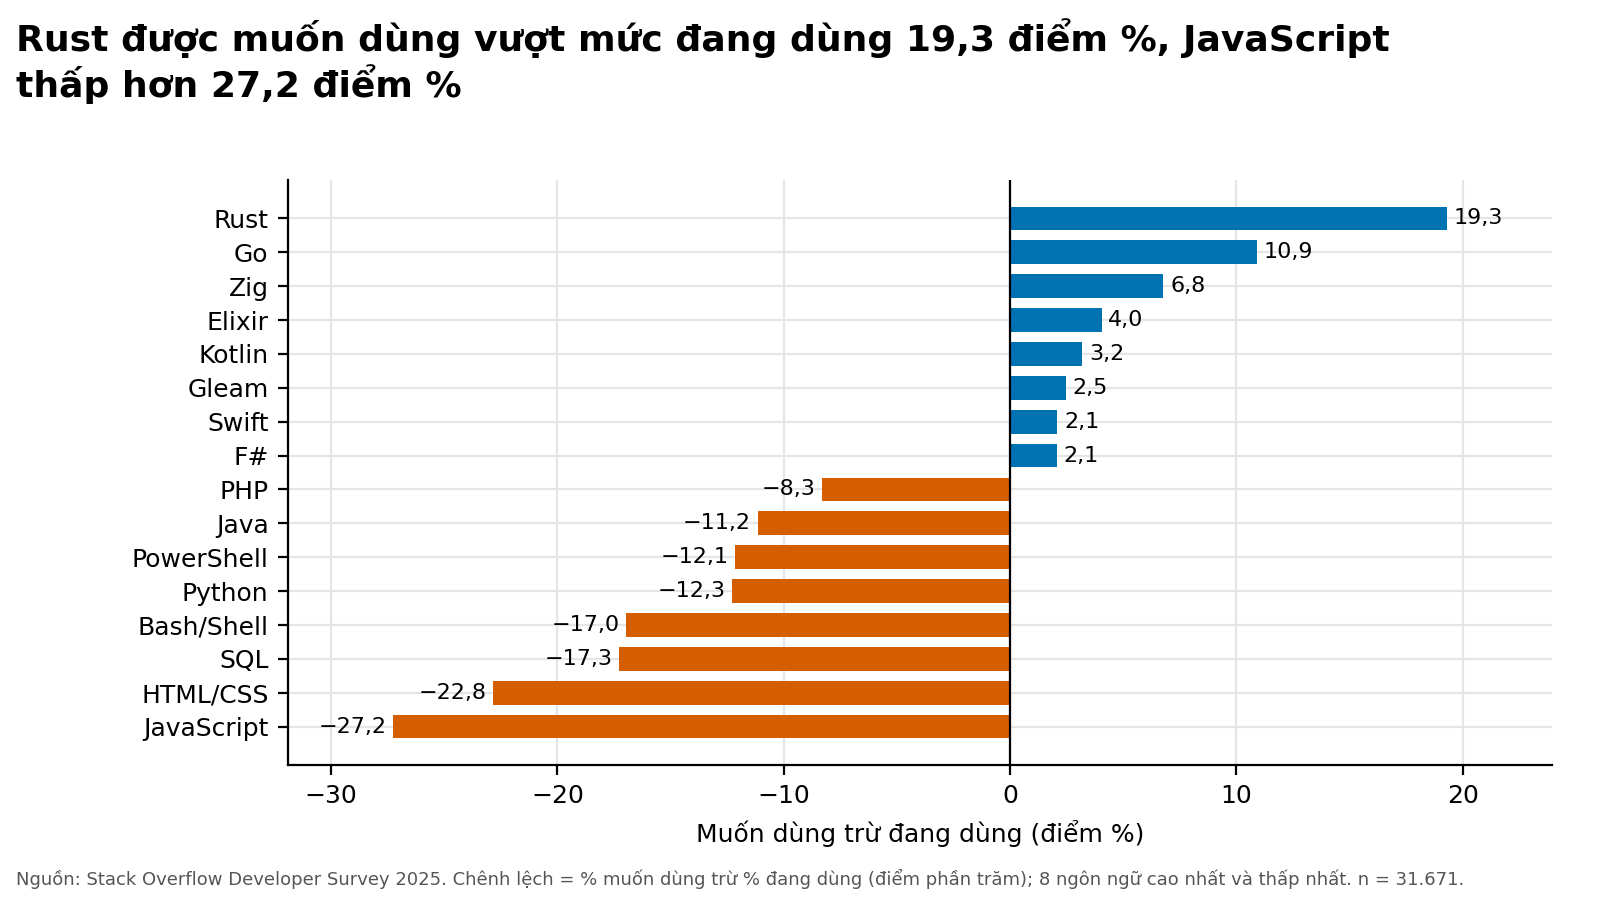

**Nhận xét.** Ngôn ngữ có mức muốn dùng cao hơn mức đang dùng nhiều nhất: Rust, Go, Zig. Ngôn ngữ mà mức muốn dùng thấp hơn mức đang dùng nhiều nhất: JavaScript, HTML/CSS, SQL.

**Insight.** Đây là chỉ số thay thế cho xu hướng: ngôn ngữ có chênh lệch dương lớn đang được người dùng kỳ vọng nhiều hơn so với mức dùng hiện tại.

In [20]:
finish(*fig_f3_2(lang))

### Q4 – Ngôn ngữ nào đi cùng nhau, và người dùng X muốn dùng Y nào?
Mạng chỉ giữ các cặp ngôn ngữ vừa đủ phổ biến (cùng xuất hiện ở ít nhất 2% người trả lời) vừa đi cùng nhau nhiều hơn mức ngẫu nhiên (lift ≥ 1,5) để tránh "búi tóc". Vị trí nút chỉ để quan sát, không mang ý nghĩa đo lường.
Sankey cho thấy người đang dùng X cũng muốn dùng Y (đây là mong muốn tại một thời điểm, không phải chuyển đổi thực tế).

In [21]:
def cooccurrence(df: pd.DataFrame):
    """Ma trận số người dùng chung từng cặp ngôn ngữ."""
    flags = pd.crosstab(*[explode_multi(df, Col.LANG_HAVE)[c] for c in (Col.ID, Col.VALUE)]).clip(upper=1)
    return flags.T.dot(flags), len(flags)


def build_graph(df: pd.DataFrame):
    """Dựng đồ thị đồng xuất hiện: giữ cặp đủ phổ biến và đi cùng nhau hơn mức ngẫu nhiên (lift)."""
    matrix, n = cooccurrence(df)
    usage = {name: matrix.loc[name, name] / n * 100 for name in matrix.index}
    graph = nx.Graph()
    for a, b in itertools.combinations(matrix.index, 2):
        share = matrix.loc[a, b] / n * 100
        lift = share / (usage[a] * usage[b] / 100)
        if share >= EDGE_MIN_SHARE and lift >= EDGE_MIN_LIFT:
            graph.add_edge(a, b, weight=lift, share=share)
    return graph, {name: usage[name] for name in graph.nodes}, n


def fig_f4_1(df: pd.DataFrame):
    """f4_1: mạng các ngôn ngữ thường được dùng chung."""
    graph, usage, n = build_graph(df)
    groups = list(community.greedy_modularity_communities(graph, weight="weight"))
    hub = max(graph.degree, key=lambda item: item[1])
    top_edge = max(graph.edges(data="weight"), key=lambda item: item[2])
    note = Note(
        "f4_1", f"Có {len(groups)} cụm ngôn ngữ hay được dùng chung",
        f"Đồ thị có {graph.number_of_nodes()} ngôn ngữ và {graph.number_of_edges()} cặp. Một cặp được giữ khi cùng xuất hiện ở ít nhất {fmt_num(EDGE_MIN_SHARE, 0)}% người trả lời "
        f"và có lift ≥ {fmt_num(EDGE_MIN_LIFT)} (đi cùng nhau nhiều gấp {fmt_num(EDGE_MIN_LIFT)} lần so với ngẫu nhiên). "
        f"Cặp gắn bó nhất là {top_edge[0]} và {top_edge[1]} (lift {fmt_num(top_edge[2])}); {hub[0]} nối với nhiều ngôn ngữ nhất ({hub[1]} cạnh).",
        "Số cạnh nhiều của một nút chỉ cho biết ngôn ngữ hay đi cùng ngôn ngữ khác, không có nghĩa là quan trọng hơn; một số cụm gợi ý các ngôn ngữ có thể học cùng nhau.",
        source_line(n, f"Người có trả lời ngôn ngữ đang dùng; cạnh = cặp cùng xuất hiện ≥{fmt_num(EDGE_MIN_SHARE, 0)}% người và lift ≥{fmt_num(EDGE_MIN_LIFT)}; nút to = nhiều người dùng; màu = cụm."), n)
    pos = nx.spring_layout(graph, seed=Cfg.seed, k=SPRING_K / np.sqrt(graph.number_of_nodes()), weight="weight")
    fig, ax = new_fig(note, left=0.02)
    ax.axis("off")
    node_color = {name: Pal.cat[i % len(Pal.cat)] for i, grp in enumerate(groups) for name in grp}
    widths = [graph[a][b]["weight"] * EDGE_WIDTH_SCALE for a, b in graph.edges]
    nx.draw_networkx_edges(graph, pos, ax=ax, width=widths, edge_color=Pal.neutral, alpha=0.6)
    nx.draw_networkx_nodes(graph, pos, ax=ax, node_size=[usage[v] * NODE_SIZE_SCALE for v in graph.nodes],
                           node_color=[node_color[v] for v in graph.nodes], alpha=0.9)
    nx.draw_networkx_labels(graph, pos, ax=ax, font_size=7, font_weight="bold")
    export_table(nx.to_pandas_edgelist(graph), "f4_1")
    return fig, note


def flow_matrix(df: pd.DataFrame, names: list) -> tuple:
    """Số người đang dùng X (hàng) và muốn dùng Y (cột), loại đường chéo."""
    both = df[df[Col.LANG_HAVE].notna() & df[Col.LANG_WANT].notna()]
    have = pd.crosstab(*[explode_multi(both, Col.LANG_HAVE)[c] for c in (Col.ID, Col.VALUE)])[names]
    want = pd.crosstab(*[explode_multi(both, Col.LANG_WANT)[c] for c in (Col.ID, Col.VALUE)])[names]
    flows = have.T.dot(want.reindex(have.index).fillna(0))
    return flows, have.sum(), len(both)


def fig_f4_2(df: pd.DataFrame):
    """f4_2: Sankey từ ngôn ngữ đang dùng sang ngôn ngữ muốn dùng, chỉ giữ luồng mạnh."""
    names = list(share_answered(df, Col.LANG_HAVE)[0].index[:TOP_SANKEY])
    flows, users, n = flow_matrix(df, names)
    cross = flows.mask(np.eye(len(flows), dtype=bool), 0)
    share = cross.div(users, axis=0) * 100
    count = len(names)
    strong = [(i, j) for i in range(count) for j in range(count) if share.iloc[i, j] >= SANKEY_MIN_SHARE]
    col_mean = share.where(~np.eye(count, dtype=bool)).mean()
    ranked = sorted(strong, key=lambda pair: share.iloc[pair], reverse=True)
    src, dst = ranked[0]
    top_flows = "; ".join(f"{names[i]} → {names[j]} ({fmt_pct(share.iloc[i, j], 0)})" for i, j in ranked[:3])
    note = Note(
        "f4_2", f"Người dùng {names[src]} thường muốn dùng thêm {names[dst]} ({fmt_pct(share.iloc[src, dst], 0)})",
        f"Có {len(strong)} luồng mạnh, tức ít nhất {fmt_num(SANKEY_MIN_SHARE, 0)}% người đang dùng X muốn dùng Y, trong {TOP_SANKEY} ngôn ngữ phổ biến nhất. "
        f"Luồng mạnh nhất: {fmt_pct(share.iloc[src, dst])} người đang dùng {names[src]} muốn dùng {names[dst]}. "
        f"Ba luồng mạnh nhất: {top_flows}.",
        f"Đây là mong muốn tại một thời điểm, không phải số người thực sự chuyển đổi. Tỷ lệ muốn dùng trung bình qua các nhóm nguồn khác nhau theo ngôn ngữ đích: {fmt_pct(col_mean.max(), 0)} với {names[int(col_mean.argmax())]} và {fmt_pct(col_mean.min(), 0)} với {names[int(col_mean.argmin())]}.",
        source_line(n, f"Người có trả lời cả hai mục; {TOP_SANKEY} ngôn ngữ phổ biến nhất; chỉ vẽ luồng ≥{fmt_num(SANKEY_MIN_SHARE, 0)}% người dùng X muốn dùng Y, bỏ luồng cùng ngôn ngữ."), n)
    labels = [f"Đang dùng: {v}" for v in names] + [f"Muốn dùng: {v}" for v in names]
    colors = list(Pal.cat[:count]) * 2
    fig = go.Figure(go.Sankey(
        node={"label": labels, "color": colors, "pad": 22, "thickness": 20},
        link={"source": [i for i, _ in strong], "target": [count + j for _, j in strong],
              "value": [float(cross.iloc[i, j]) for i, j in strong],
              "color": [hex_alpha(Pal.cat[i], LINK_ALPHA) for i, _ in strong]}))
    fig.update_traces(textfont={"size": 16})
    export_table(share.reset_index().rename(columns={Col.VALUE: "dang_dung"}), "f4_2")
    return style_plotly(fig, note), note


def hex_alpha(color: str, alpha: float) -> str:
    """Đổi mã màu hex sang rgba có độ trong suốt."""
    r, g, b = (int(color[i:i + 2], 16) for i in (1, 3, 5))
    return f"rgba({r},{g},{b},{alpha})"

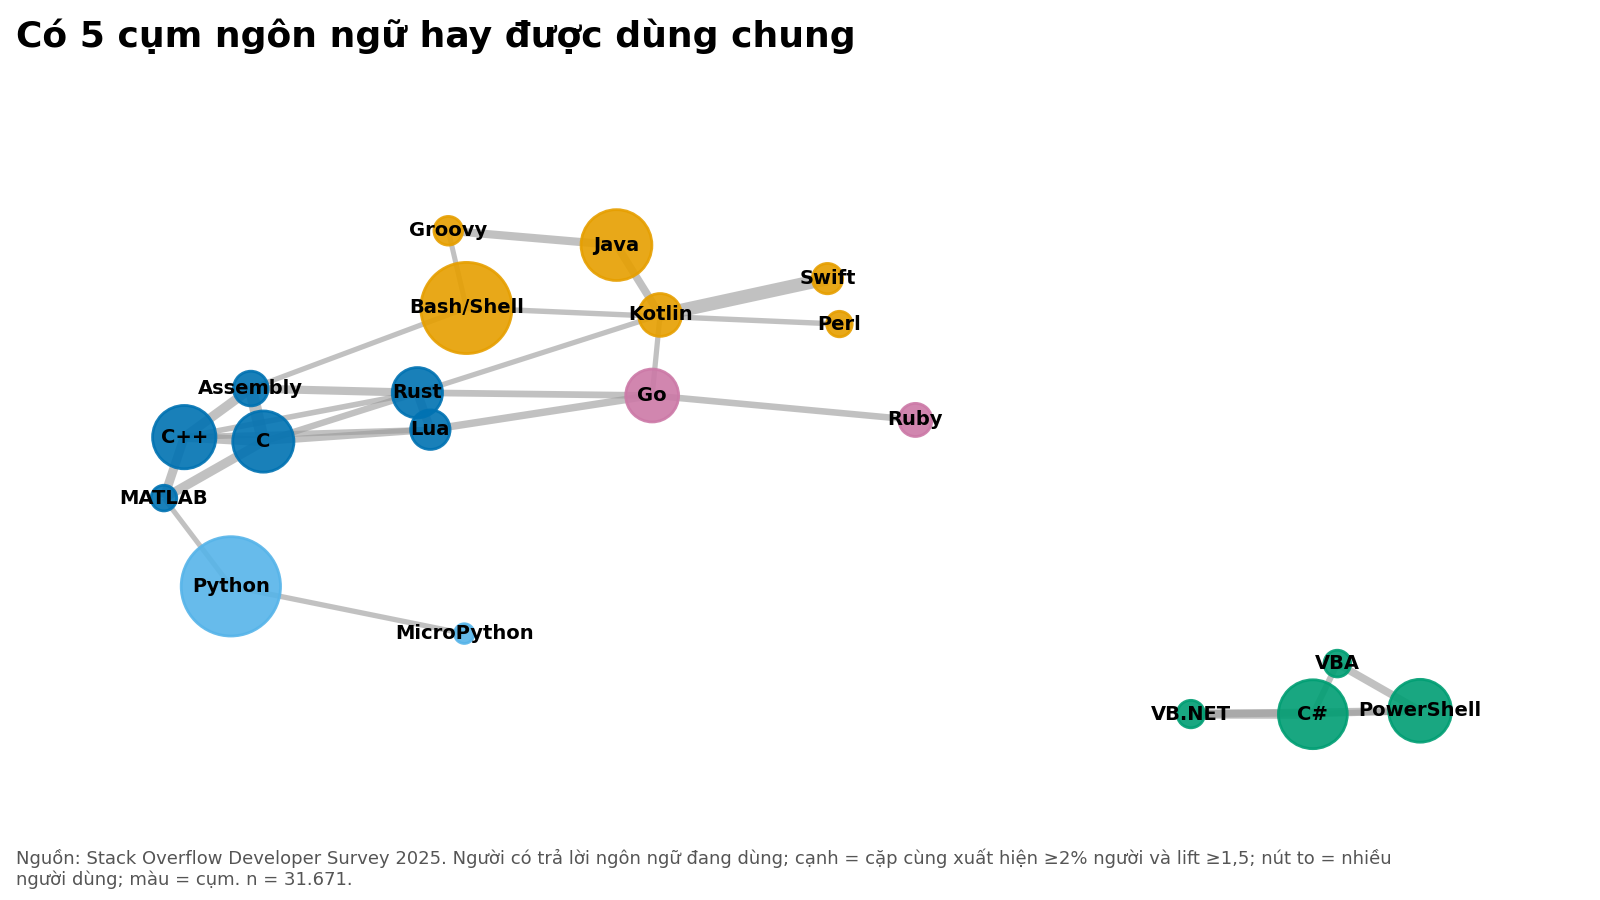

**Nhận xét.** Đồ thị có 20 ngôn ngữ và 29 cặp. Một cặp được giữ khi cùng xuất hiện ở ít nhất 2% người trả lời và có lift ≥ 1,5 (đi cùng nhau nhiều gấp 1,5 lần so với ngẫu nhiên). Cặp gắn bó nhất là Kotlin và Swift (lift 4,0); Rust nối với nhiều ngôn ngữ nhất (6 cạnh).

**Insight.** Số cạnh nhiều của một nút chỉ cho biết ngôn ngữ hay đi cùng ngôn ngữ khác, không có nghĩa là quan trọng hơn; một số cụm gợi ý các ngôn ngữ có thể học cùng nhau.

In [22]:
finish(*fig_f4_1(df_all))

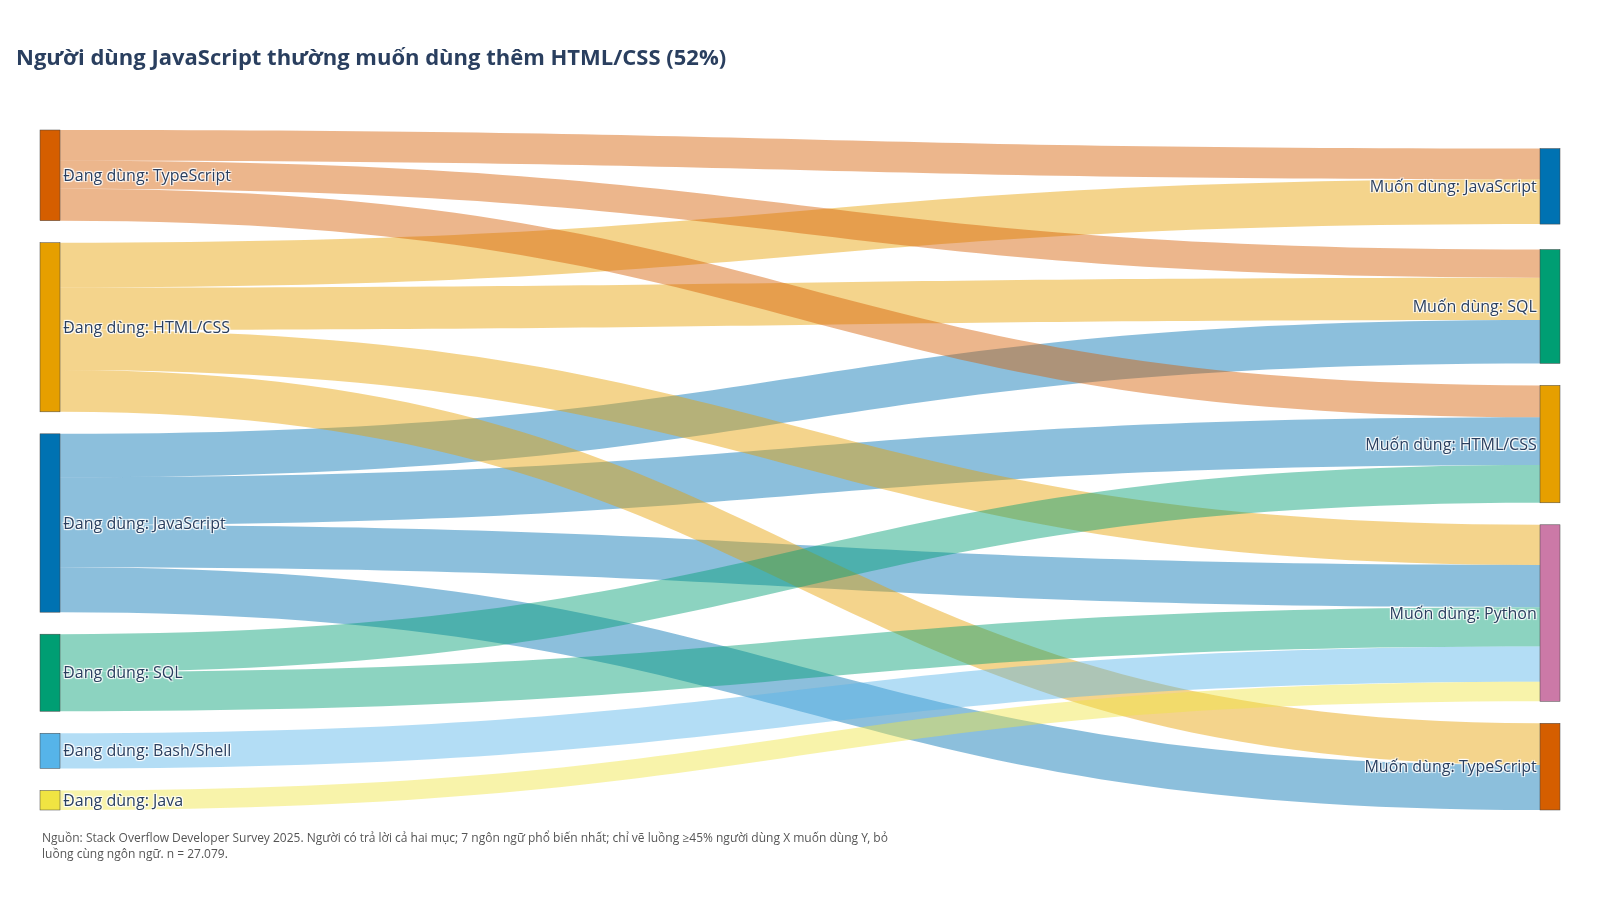

**Nhận xét.** Có 15 luồng mạnh, tức ít nhất 45% người đang dùng X muốn dùng Y, trong 7 ngôn ngữ phổ biến nhất. Luồng mạnh nhất: 51,6% người đang dùng JavaScript muốn dùng HTML/CSS. Ba luồng mạnh nhất: JavaScript → HTML/CSS (52%); TypeScript → HTML/CSS (51%); HTML/CSS → JavaScript (51%).

**Insight.** Đây là mong muốn tại một thời điểm, không phải số người thực sự chuyển đổi. Tỷ lệ muốn dùng trung bình qua các nhóm nguồn khác nhau theo ngôn ngữ đích: 47% với Python và 19% với Java.

In [23]:
finish(*fig_f4_2(df_all))

## 4. Q5–Q7 – Mức lương
Lương là `ConvertedCompYearly` (USD danh nghĩa, đã quy đổi sẵn trong dữ liệu gốc, chưa điều chỉnh sức mua), tính trên bảng `df_sal`
(lập trình viên chuyên nghiệp, lương 1.000–500.000 USD). Vì lương lệch phải mạnh nên ta dùng **median**, kèm khoảng tin cậy bootstrap 95%.
Ghi chú: số liệu là tự khai báo và mẫu lệch về Mỹ, Đức, Ấn Độ nên chỉ nên đọc như mô tả mẫu khảo sát, không phải thị trường lao động nói chung.

In [24]:
import joypy
import plotly.express as px

N_BINS = 40
LOG_TICKS = (10_000, 30_000, 100_000, 300_000)
TOP_RANK = 10
BOTTOM_RANK = 10
HEAT_LANGS = 10
HEAT_ROLES = 6
RIDGE_OVERLAP = 1.2
RIDGE_LINEWIDTH = 0.8
RIDGE_RANGE = (3.0, 5.7)
HEAT_BOTTOM = 0.24
RIDGE_ALPHA = 0.85
MAP_COLORSCALE = "Blues"
MAP_CENTER_LON = 10
MAP_LAT_RANGE = (-58, 85)


def fmt_usd(value) -> str:
    """Định dạng tiền USD kiểu Việt Nam."""
    return f"{fmt_int(value)} USD"


def sal_footer(n: int, extra: str = "") -> str:
    """Chú thích chân chuẩn cho biểu đồ lương."""
    return source_line(n, f"Lập trình viên chuyên nghiệp, lương {fmt_int(Cfg.sal_min)}–{fmt_int(Cfg.sal_max)} USD (USD danh nghĩa). {extra}".strip())

In [25]:
def fig_f5_1(df: pd.DataFrame):
    """f5_1: phân phối lương toàn mẫu trên thang log, median và mean."""
    sal = df[Col.SAL]
    med, mean = sal.median(), sal.mean()
    q1, q3 = sal.quantile(0.25), sal.quantile(0.75)
    note = Note(
        "f5_1", f"Median lương {fmt_usd(med)} thấp hơn mean {fmt_usd(mean)}: phân phối lệch phải",
        f"Một nửa số người có lương dưới {fmt_usd(med)}; 25% thấp nhất dưới {fmt_usd(q1)} và 25% cao nhất trên {fmt_usd(q3)}. "
        f"Mean cao hơn median {fmt_pct((mean / med - 1) * 100, 0)} vì một số ít người có lương rất cao kéo trung bình lên.",
        "Vì lương lệch phải, khi nói 'lương điển hình' phải dùng median thay vì mean để tránh kỳ vọng quá cao.",
        sal_footer(len(sal), "Trục ngang là thang log."), len(sal))
    fig, ax = new_fig(note, left=0.08)
    ax.hist(sal, bins=np.logspace(np.log10(Cfg.sal_min), np.log10(Cfg.sal_max), N_BINS), color=Pal.neutral, edgecolor="white")
    ax.set_xscale("log")
    for value, color, name in ((med, Pal.accent2, "Median"), (mean, Pal.accent, "Mean")):
        ax.axvline(value, color=color, linewidth=1.8)
        ax.text(value, ax.get_ylim()[1] * (0.95 if name == "Median" else 0.85), f" {name} {fmt_int(value)}", color=color, fontsize=8, fontweight="bold")
    ax.set_xticks(LOG_TICKS, [fmt_int(t) for t in LOG_TICKS])
    ax.set_xlabel("Lương năm (USD, thang log)")
    ax.set_ylabel("Số người")
    thousands_axis(ax, "y")
    export_table(pd.DataFrame({"stat": ["median", "mean", "q1", "q3"], "usd": [med, mean, q1, q3]}), "f5_1")
    return fig, note


def fig_f5_2(df: pd.DataFrame, role_names: list):
    """f5_2: ridgeline phân phối lương theo vai trò, sắp theo median."""
    data = df[df[Col.ROLE].isin(role_names)].copy()
    table = median_table(data, Col.ROLE, with_ci=False).sort_values("median", ascending=False)
    order = table[Col.ROLE].tolist()
    data["log_sal"] = np.log10(data[Col.SAL])
    data[Col.ROLE] = pd.Categorical(data[Col.ROLE], categories=order, ordered=True)
    hi, lo = table.iloc[0], table.iloc[-1]
    iqr = data.groupby(Col.ROLE, observed=True)[Col.SAL].apply(lambda v: v.quantile(0.75) - v.quantile(0.25)).median()
    spread = hi["median"] - lo["median"]
    overlap = (f"Khoảng tứ phân vị điển hình trong một vai trò ({fmt_usd(iqr)}) lớn hơn chênh lệch giữa median cao nhất và thấp nhất ({fmt_usd(spread)}), "
               "nên chênh lệch trong cùng vai trò lớn hơn giữa các vai trò." if iqr > spread else
               f"Khoảng tứ phân vị điển hình trong một vai trò ({fmt_usd(iqr)}) nhỏ hơn chênh lệch giữa median cao nhất và thấp nhất ({fmt_usd(spread)}), nên vai trò phân biệt lương khá rõ.")
    note = Note(
        "f5_2", f"{hi[Col.ROLE]} có median lương cao nhất ({fmt_usd(hi['median'])}), gấp {fmt_num(hi['median'] / lo['median'])} lần {lo[Col.ROLE]}",
        f"Trong {len(order)} vai trò, median thấp nhất là {lo[Col.ROLE]} ({fmt_usd(lo['median'])}) và cao nhất là {hi[Col.ROLE]} ({fmt_usd(hi['median'])}). " + overlap,
        "Vai trò gắn với mức lương điển hình, nhưng người trong cùng một vai trò vẫn có lương khác nhau; cần xét thêm nước và kinh nghiệm.",
        sal_footer(len(data), f"{len(order)} vai trò có ít nhất {Cfg.min_role_n} dòng; vạch đứng là median; trục ngang là log10 của lương."), len(data))
    fig, axes = joypy.joyplot(data, by=Col.ROLE, column="log_sal", figsize=(Cfg.fig_w, Cfg.fig_h), color=Pal.accent, alpha=RIDGE_ALPHA,
                              overlap=RIDGE_OVERLAP, linewidth=RIDGE_LINEWIDTH, ylabelsize=7, xlabelsize=8, grid="y", x_range=RIDGE_RANGE)
    for ax, key in zip(axes[:-1], order):
        ax.axvline(np.log10(table.set_index(Col.ROLE).loc[key, "median"]), color=Pal.accent2, linewidth=1.2)
    axes[-1].set_xticks([np.log10(t) for t in LOG_TICKS], [fmt_int(t) for t in LOG_TICKS])
    axes[-1].set_xlabel("Lương năm (USD, thang log)")
    decorate_fig(fig, note, left=0.17)
    export_table(table, "f5_2")
    return fig, note


def fig_f5_3(df: pd.DataFrame):
    """f5_3: median lương theo nhóm năm kinh nghiệm làm việc."""
    data = df.dropna(subset=[Col.EXPBIN])
    table = median_table(data, Col.EXPBIN)
    medians = table["median"].to_numpy()
    rising = bool(np.all(np.diff(medians) > 0))
    first, last = table.iloc[0], table.iloc[-1]
    peak = table.loc[table["median"].idxmax()]
    overall = df[Col.SAL].median()
    title = (f"Median lương tăng từ {fmt_usd(first['median'])} (0–2 năm) lên {fmt_usd(last['median'])} (21+ năm)" if rising
             else f"Median lương cao nhất ở nhóm {peak[Col.EXPBIN]} năm kinh nghiệm ({fmt_usd(peak['median'])})")
    note = Note(
        "f5_3", title,
        f"Median lương của nhóm 21+ năm gấp {fmt_num(last['median'] / first['median'])} lần nhóm 0–2 năm. "
        f"{'Median tăng đều qua mọi nhóm kinh nghiệm' if rising else 'Median không tăng đều qua mọi nhóm kinh nghiệm'}; "
        f"nhóm 3–5 năm có median {fmt_usd(table.iloc[1]['median'])}.",
        f"Nhóm 0–2 năm có median bằng {fmt_pct(first['median'] / overall * 100, 0)} median toàn mẫu ({fmt_usd(overall)}); người mới nên đặt kỳ vọng tương ứng.",
        sal_footer(int(table.n.sum()), "Vùng tô là khoảng tin cậy bootstrap 95% của median; số dưới điểm là cỡ mẫu từng nhóm."), int(table.n.sum()))
    fig, ax = new_fig(note, left=0.10)
    x = np.arange(len(table))
    ax.fill_between(x, table.lo, table.hi, color=Pal.accent, alpha=0.2)
    ax.plot(x, table["median"], color=Pal.accent, marker="o", linewidth=2)
    for xi, row in zip(x, table.itertuples()):
        ax.text(xi, row.median, f"{fmt_int(row.median)}", ha="center", va="bottom", fontsize=8, fontweight="bold")
        ax.text(xi, ax.get_ylim()[0], f"n={fmt_int(row.n)}", ha="center", va="bottom", fontsize=7, color="#555555")
    ax.set_xticks(x, table[Col.EXPBIN].astype(str))
    ax.set_xlabel("Số năm kinh nghiệm làm việc (WorkExp)")
    ax.set_ylabel("Median lương (USD)")
    thousands_axis(ax, "y")
    export_table(table, "f5_3")
    return fig, note

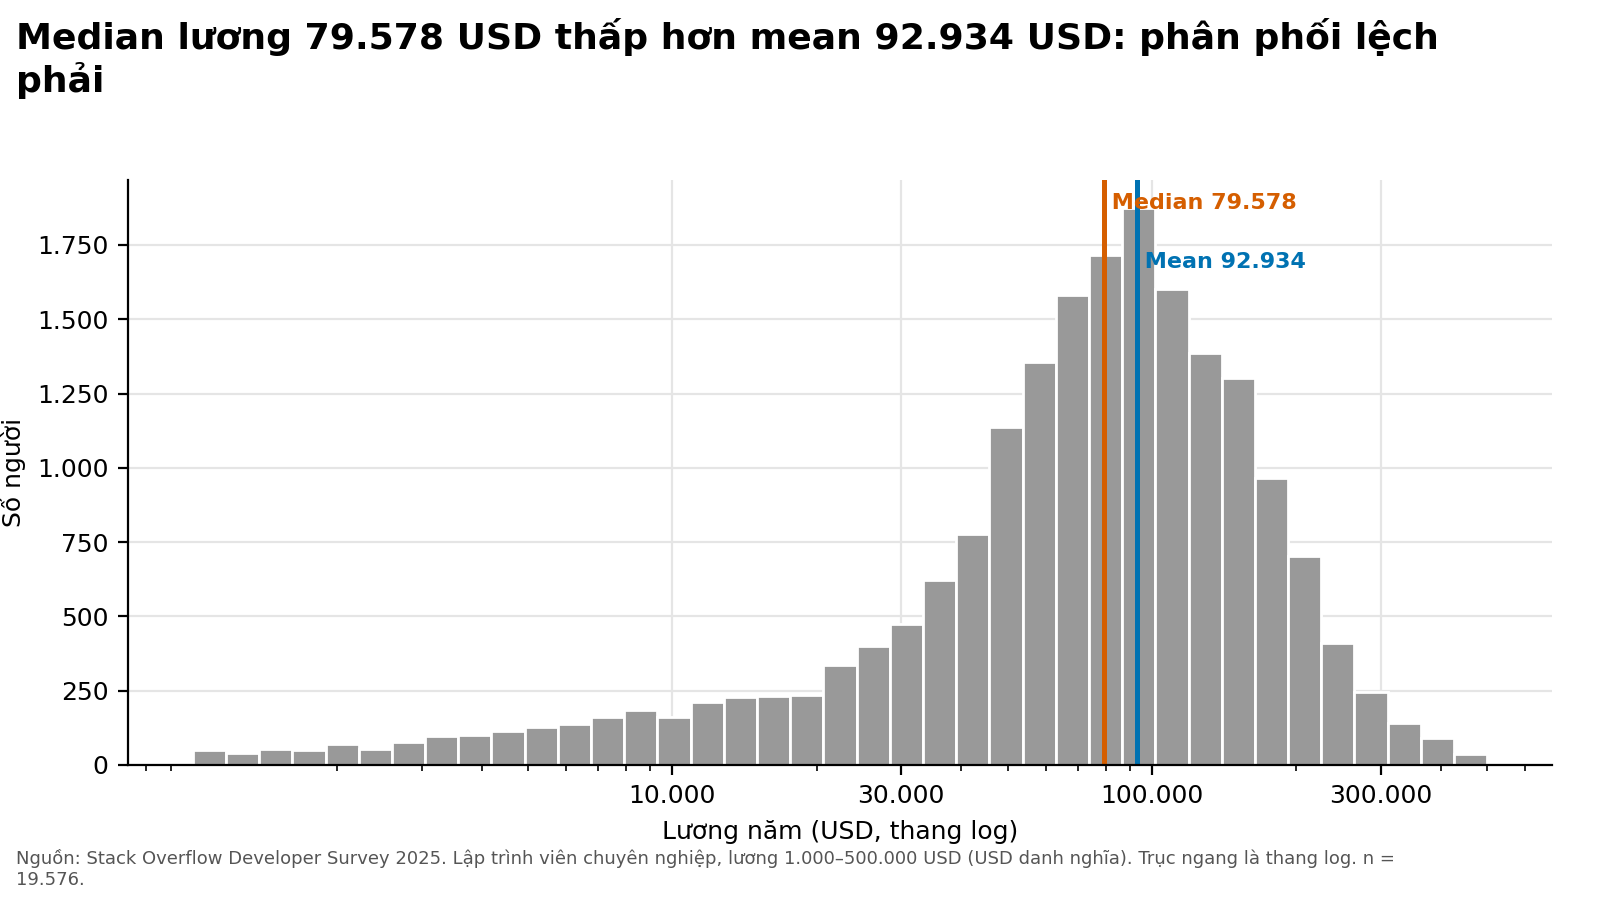

**Nhận xét.** Một nửa số người có lương dưới 79.578 USD; 25% thấp nhất dưới 44.754 USD và 25% cao nhất trên 124.136 USD. Mean cao hơn median 17% vì một số ít người có lương rất cao kéo trung bình lên.

**Insight.** Vì lương lệch phải, khi nói 'lương điển hình' phải dùng median thay vì mean để tránh kỳ vọng quá cao.

In [26]:
finish(*fig_f5_1(df_sal))

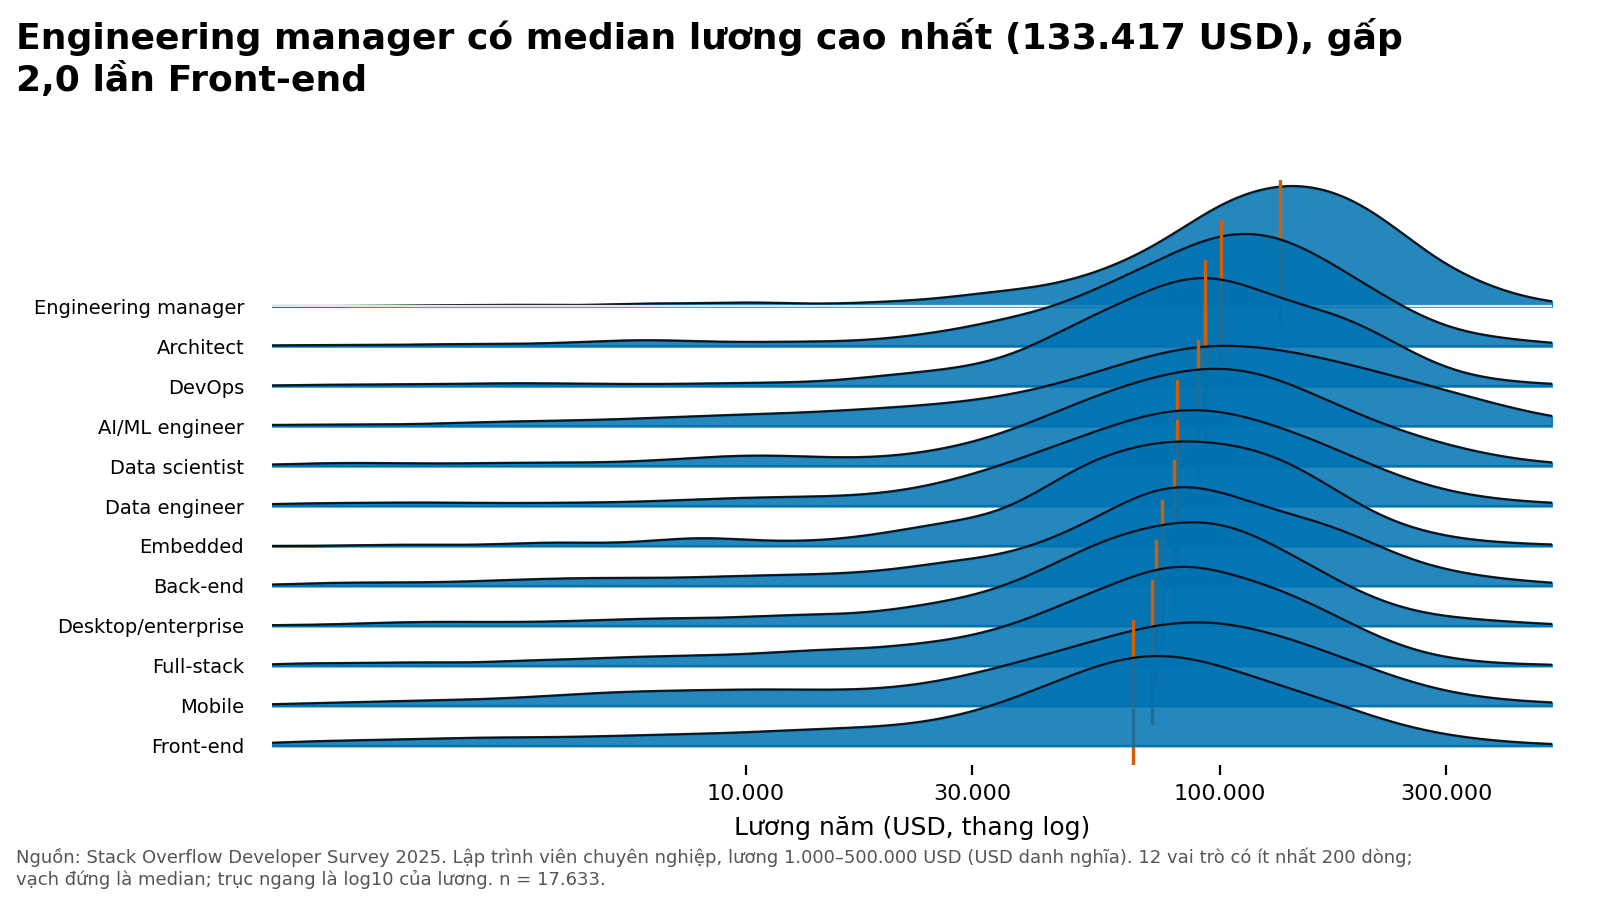

**Nhận xét.** Trong 12 vai trò, median thấp nhất là Front-end (65.496 USD) và cao nhất là Engineering manager (133.417 USD). Khoảng tứ phân vị điển hình trong một vai trò (78.533 USD) lớn hơn chênh lệch giữa median cao nhất và thấp nhất (67.921 USD), nên chênh lệch trong cùng vai trò lớn hơn giữa các vai trò.

**Insight.** Vai trò gắn với mức lương điển hình, nhưng người trong cùng một vai trò vẫn có lương khác nhau; cần xét thêm nước và kinh nghiệm.

In [27]:
finish(*fig_f5_2(df_sal, roles))

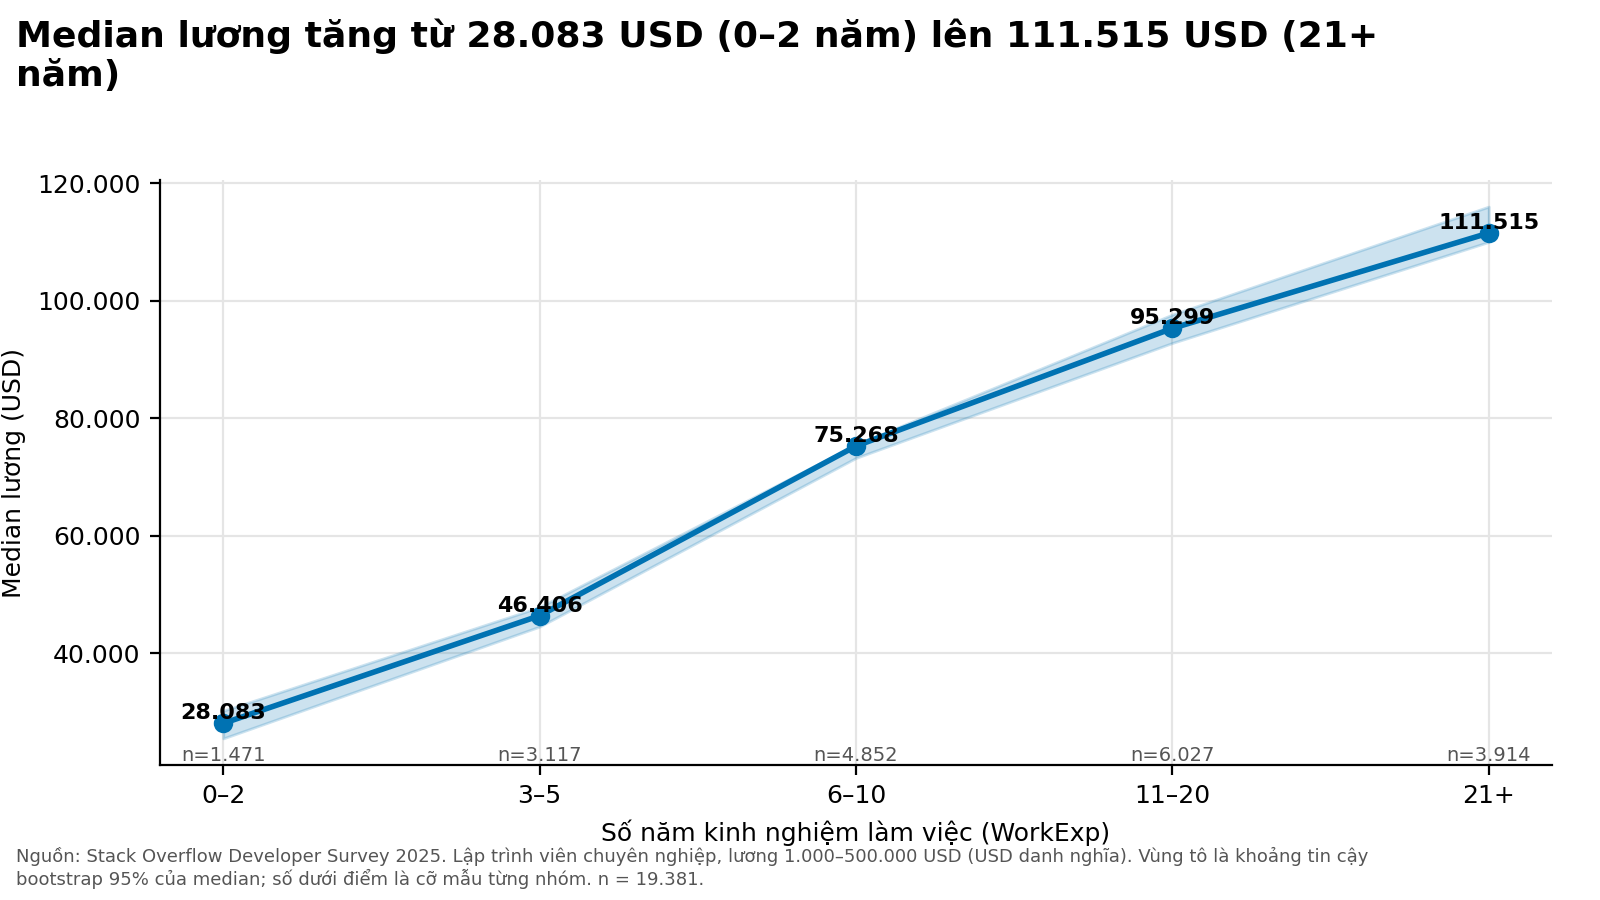

**Nhận xét.** Median lương của nhóm 21+ năm gấp 4,0 lần nhóm 0–2 năm. Median tăng đều qua mọi nhóm kinh nghiệm; nhóm 3–5 năm có median 46.406 USD.

**Insight.** Nhóm 0–2 năm có median bằng 35% median toàn mẫu (79.578 USD); người mới nên đặt kỳ vọng tương ứng.

In [28]:
finish(*fig_f5_3(df_sal))

### Q6 – Công nghệ nào đi cùng mức lương cao?
Cẩn thận: so sánh trực tiếp lương theo ngôn ngữ có thể gây hiểu nhầm vì ngôn ngữ phổ biến ở nước lương cao trông "lương cao" chỉ do người dùng ở đó.
Hai biểu đồ này là mô tả; phần hồi quy ở mục 7 sẽ tách ảnh hưởng của quốc gia và kinh nghiệm.

In [29]:
def lang_salary(df: pd.DataFrame) -> pd.DataFrame:
    """Bảng lương dạng dài theo từng ngôn ngữ đang dùng."""
    longer = explode_multi(df, Col.LANG_HAVE).merge(df[[Col.ID, Col.SAL, Col.ROLE]], on=Col.ID)
    return longer.rename(columns={Col.VALUE: "lang"})


def fig_f6_1(df: pd.DataFrame):
    """f6_1: median lương theo ngôn ngữ phổ biến (chưa tách ảnh hưởng quốc gia)."""
    longer = lang_salary(df)
    top = longer["lang"].value_counts().head(Cfg.top_lang).index
    table = median_table(longer[longer["lang"].isin(top)], "lang").sort_values("median")
    hi, lo = table.iloc[-1], table.iloc[0]
    overall = df[Col.SAL].median()
    pairs = [(a, b) for i, a in table.reset_index(drop=True).iterrows() for j, b in table.reset_index(drop=True).iterrows() if i < j]
    overlap = np.mean([max(a.lo, b.lo) <= min(a.hi, b.hi) for a, b in pairs])
    note = Note(
        "f6_1", f"Giữa {Cfg.top_lang} ngôn ngữ phổ biến, median lương chênh {fmt_pct((hi['median'] / lo['median'] - 1) * 100, 0)}: từ {lo['lang']} đến {hi['lang']}",
        f"{hi['lang']} có median {fmt_usd(hi['median'])} (n = {fmt_int(hi['n'])}), {lo['lang']} có {fmt_usd(lo['median'])} (n = {fmt_int(lo['n'])}); median toàn mẫu là {fmt_usd(overall)}. "
        f"Khoảng tin cậy 95% của {fmt_pct(overlap * 100, 0)} số cặp ngôn ngữ chồng lấn nhau, nên các chênh lệch này kém chắc chắn.",
        "Chưa thể kết luận ngôn ngữ nào 'trả lương cao hơn': khác biệt này có thể phản ánh cơ cấu nước và kinh nghiệm của người dùng (xem hồi quy).",
        sal_footer(int(longer[longer['lang'].isin(top)][Col.ID].nunique()), f"Mỗi người được tính ở mọi ngôn ngữ họ dùng; thanh sai số là khoảng tin cậy 95%; đường nét đứt là median toàn mẫu."),
        int(longer[longer['lang'].isin(top)][Col.ID].nunique()))
    fig, ax = new_fig(note, left=0.17)
    err = np.vstack([table["median"] - table.lo, table.hi - table["median"]])
    ax.barh(table["lang"], table["median"], xerr=err, color=Pal.accent, height=BAR_HEIGHT, error_kw={"ecolor": "#333333", "capsize": 2})
    ax.axvline(overall, color=Pal.accent2, linestyle="--", linewidth=1)
    ax.text(overall, -0.9, f" Median toàn mẫu {fmt_int(overall)}", color=Pal.accent2, fontsize=7)
    ax.set_xlabel("Median lương (USD)")
    thousands_axis(ax)
    export_table(table, "f6_1")
    return fig, note


def fig_f6_2(df: pd.DataFrame):
    """f6_2: heatmap median lương theo ngôn ngữ và vai trò, ô đủ cỡ mẫu mới tô màu."""
    longer = lang_salary(df)
    langs = longer["lang"].value_counts().head(HEAT_LANGS).index.tolist()
    role_names = longer[Col.ROLE].value_counts().head(HEAT_ROLES).index.tolist()
    sub = longer[longer["lang"].isin(langs) & longer[Col.ROLE].isin(role_names)]
    med = sub.pivot_table(index="lang", columns=Col.ROLE, values=Col.SAL, aggfunc="median").reindex(index=langs, columns=role_names)
    size = sub.pivot_table(index="lang", columns=Col.ROLE, values=Col.SAL, aggfunc="size").reindex(index=langs, columns=role_names)
    med = med.where(size >= Cfg.min_cell_n)
    best = med.idxmax(axis=1).value_counts()
    by_role = (med.max(axis=1) - med.min(axis=1)).mean()
    by_lang = (med.max(axis=0) - med.min(axis=0)).mean()
    which = (f"Khoảng cách median lớn nhất–nhỏ nhất trong một ngôn ngữ (qua {len(role_names)} vai trò) trung bình {fmt_usd(by_role)}, còn trong một vai trò (qua {len(langs)} ngôn ngữ) trung bình {fmt_usd(by_lang)}"
             + (": vai trò đi cùng chênh lệch lương lớn hơn ngôn ngữ (số nhóm so sánh khác nhau nên chỉ mang tính tham khảo)." if by_role > by_lang else ": ngôn ngữ đi cùng chênh lệch lương lớn hơn vai trò (số nhóm so sánh khác nhau nên chỉ mang tính tham khảo)."))
    note = Note(
        "f6_2", f"{best.index[0]} có median lương cao nhất ở {int(best.iloc[0])}/{len(langs)} ngôn ngữ được so sánh",
        f"Heatmap gồm {len(langs)} ngôn ngữ và {len(role_names)} vai trò phổ biến nhất ({med.notna().sum().sum()}/{med.size} ô đủ {Cfg.min_cell_n} người). "
        f"Giá trị cao nhất là {fmt_usd(np.nanmax(med.to_numpy()))}, thấp nhất là {fmt_usd(np.nanmin(med.to_numpy()))}.",
        which,
        sal_footer(int(sub[Col.ID].nunique()), f"Mỗi người được tính ở mọi ngôn ngữ họ dùng; ô dấu – là chưa đủ {Cfg.min_cell_n} người; số trong ô là median (nghìn USD)."), int(sub[Col.ID].nunique()))
    fig, ax = new_fig(note, left=0.14)
    fig.subplots_adjust(bottom=HEAT_BOTTOM)
    image = ax.imshow(med.to_numpy() / 1000, cmap=MAP_COLORSCALE, aspect="auto")
    ax.set_xticks(range(len(role_names)), role_names, rotation=20, ha="right", fontsize=7)
    ax.set_yticks(range(len(langs)), langs, fontsize=7)
    ax.grid(False)
    for i in range(len(langs)):
        for j in range(len(role_names)):
            value = med.iloc[i, j]
            ax.text(j, i, "–" if np.isnan(value) else fmt_num(value / 1000, 0), ha="center", va="center", fontsize=7,
                    color="white" if (not np.isnan(value) and value / 1000 > np.nanmax(med.to_numpy()) / 1000 * 0.6) else "#222222")
    fig.colorbar(image, ax=ax, label="Median lương (nghìn USD)", fraction=0.04)
    export_table(med.reset_index(), "f6_2")
    return fig, note

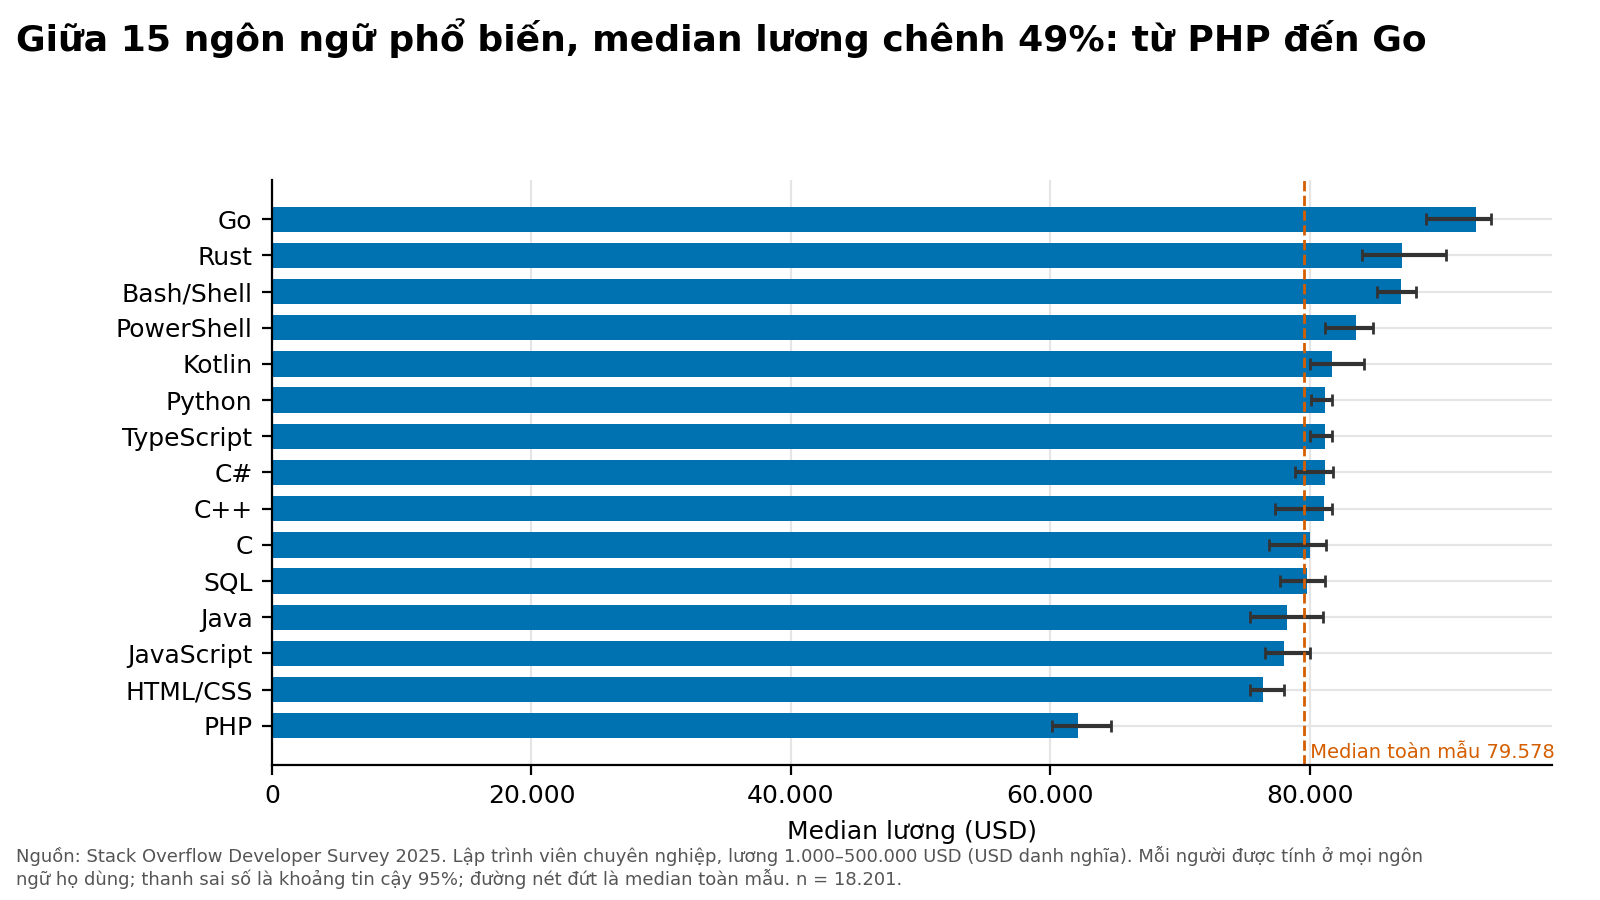

**Nhận xét.** Go có median 92.812 USD (n = 3.226), PHP có 62.099 USD (n = 3.354); median toàn mẫu là 79.578 USD. Khoảng tin cậy 95% của 49% số cặp ngôn ngữ chồng lấn nhau, nên các chênh lệch này kém chắc chắn.

**Insight.** Chưa thể kết luận ngôn ngữ nào 'trả lương cao hơn': khác biệt này có thể phản ánh cơ cấu nước và kinh nghiệm của người dùng (xem hồi quy).

In [30]:
finish(*fig_f6_1(df_sal))

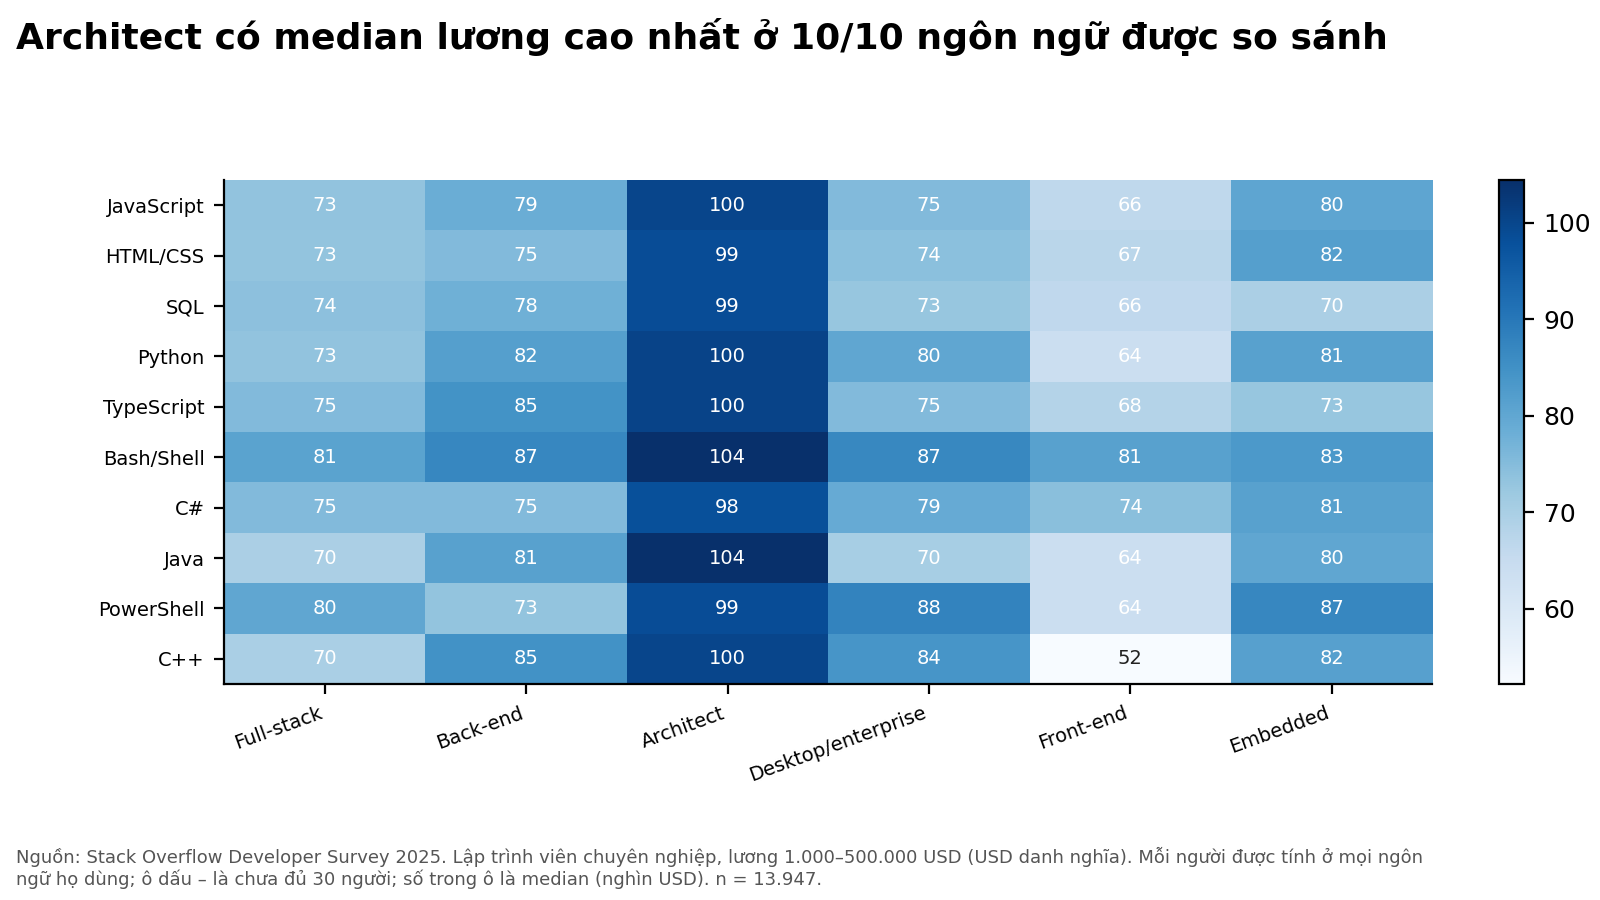

**Nhận xét.** Heatmap gồm 10 ngôn ngữ và 6 vai trò phổ biến nhất (60/60 ô đủ 30 người). Giá trị cao nhất là 104.413 USD, thấp nhất là 52.207 USD.

**Insight.** Khoảng cách median lớn nhất–nhỏ nhất trong một ngôn ngữ (qua 6 vai trò) trung bình 33.674 USD, còn trong một vai trò (qua 10 ngôn ngữ) trung bình 15.885 USD: vai trò đi cùng chênh lệch lương lớn hơn ngôn ngữ (số nhóm so sánh khác nhau nên chỉ mang tính tham khảo).

In [31]:
finish(*fig_f6_2(df_sal))

### Q7 – Lương khác nhau thế nào giữa các nước, Việt Nam đứng đâu?
Bản đồ chỉ tô màu **median lương** (đã chuẩn hóa theo từng nước, không phải số tuyệt đối), chỉ cho các nước đủ 30 dòng lương.
Lưu ý: lương là USD danh nghĩa, chưa điều chỉnh sức mua; Việt Nam chỉ có 31 dòng nên kết quả mang tính tham khảo.

In [32]:
def country_table(df: pd.DataFrame, names: list) -> pd.DataFrame:
    """Bảng median lương và khoảng tin cậy theo nước, kèm mã ISO-3."""
    table = median_table(df[df[Col.COUNTRY].isin(names)], Col.COUNTRY)
    iso = df.drop_duplicates(Col.COUNTRY).set_index(Col.COUNTRY)[Col.ISO3]
    table[Col.ISO3] = table[Col.COUNTRY].map(iso)
    table["name"] = table[Col.COUNTRY].map(short_country)
    return table.sort_values("median", ascending=False).reset_index(drop=True)


def fig_f7_1(table: pd.DataFrame):
    """f7_1: choropleth median lương theo nước, Việt Nam đánh dấu."""
    vn = table[table[Col.COUNTRY] == VIETNAM].iloc[0]
    hi, lo = table.iloc[0], table.iloc[-1]
    note = Note(
        "f7_1", f"Median lương cao nhất ở {hi['name']} ({fmt_usd(hi['median'])}), thấp nhất ở {lo['name']} ({fmt_usd(lo['median'])}); Việt Nam {fmt_usd(vn['median'])}",
        f"Bản đồ có {len(table)} nước đủ {Cfg.min_country_n} dòng lương. Chênh lệch giữa nước cao nhất và thấp nhất là {fmt_num(hi['median'] / lo['median'])} lần. "
        f"Việt Nam có median {fmt_usd(vn['median'])} (khoảng tin cậy {fmt_int(vn['lo'])}–{fmt_int(vn['hi'])}, n = {int(vn['n'])}).",
        "Quốc gia là yếu tố gắn với khác biệt lương lớn nhất; số liệu Việt Nam chỉ tham khảo vì mẫu nhỏ và lương là USD danh nghĩa.",
        sal_footer(int(table.n.sum()), f"Chỉ nước đủ {Cfg.min_country_n} dòng lương; chấm cam là Việt Nam."), int(table.n.sum()))
    mapped = table.dropna(subset=[Col.ISO3])
    fig = px.choropleth(mapped, locations=Col.ISO3, color="median", hover_name="name", color_continuous_scale=MAP_COLORSCALE,
                        labels={"median": "Median lương (USD)"})
    fig.add_trace(go.Scattergeo(locations=["VNM"], locationmode="ISO-3", mode="markers+text", text=["Việt Nam"], textposition="bottom center",
                                marker={"size": 11, "color": Pal.accent2}, showlegend=False, textfont={"size": 14, "color": Pal.accent2}))
    fig.update_geos(projection_type="natural earth", projection_rotation={"lon": MAP_CENTER_LON}, lataxis_range=list(MAP_LAT_RANGE), showframe=False, showcoastlines=False, landcolor="#EEEEEE", bgcolor="white")
    fig.update_layout(coloraxis_colorbar={"title": "Median lương (USD)", "tickformat": ",.0f", "len": 0.6})
    export_table(table.drop(columns=[Col.COUNTRY]), "f7_1")
    return style_plotly(fig, note), note


def fig_f7_2(table: pd.DataFrame):
    """f7_2: xếp hạng median lương: top, Việt Nam và nhóm thấp nhất."""
    rank = int(table.index[table[Col.COUNTRY] == VIETNAM][0]) + 1
    vn = table.iloc[rank - 1]
    half = "nửa dưới" if rank > len(table) / 2 else "nửa trên"
    picked = pd.concat([table.head(TOP_RANK), table.iloc[[rank - 1]], table.tail(BOTTOM_RANK)]).drop_duplicates(Col.COUNTRY)
    note = Note(
        "f7_2", f"Việt Nam xếp thứ {rank}/{len(table)} nước về median lương ({fmt_usd(vn['median'])}), mẫu chỉ {int(vn['n'])} người",
        f"Trong {len(table)} nước đủ mẫu, Việt Nam ở {half} bảng xếp hạng (median {fmt_usd(vn['median'])}). "
        f"Thanh sai số cho thấy khoảng tin cậy của Việt Nam rất rộng ({fmt_int(vn['lo'])}–{fmt_int(vn['hi'])} USD), nên thứ hạng có thể thay đổi nhiều.",
        "Kỳ vọng lương nên so với mức sống và chi phí tại chỗ, không so trực tiếp bằng USD danh nghĩa với Mỹ hay châu Âu.",
        sal_footer(int(table.n.sum()), f"{TOP_RANK} nước cao nhất, Việt Nam và {BOTTOM_RANK} nước thấp nhất trong {len(table)} nước đủ mẫu; thanh sai số là khoảng tin cậy 95%."),
        int(table.n.sum()))
    plot = picked.iloc[::-1]
    colors = [Pal.accent2 if c == VIETNAM else Pal.accent for c in plot[Col.COUNTRY]]
    fig, ax = new_fig(note, left=0.20)
    err = np.vstack([plot["median"] - plot.lo, plot.hi - plot["median"]])
    ax.barh(plot["name"], plot["median"], xerr=err, color=colors, height=BAR_HEIGHT, error_kw={"ecolor": "#333333", "capsize": 2, "linewidth": 0.8})
    for idx, row in enumerate(plot.itertuples()):
        ax.text(row.hi + table["median"].max() * 0.01, idx, f"{fmt_int(row.median)} (n={fmt_int(row.n)})", va="center", fontsize=6.5)
    ax.tick_params(axis="y", labelsize=7)
    ax.set_xlabel("Median lương (USD)")
    ax.set_xlim(0, table["hi"].max() * 1.25)
    thousands_axis(ax)
    export_table(picked.drop(columns=[Col.COUNTRY]), "f7_2")
    return fig, note

In [33]:
by_country = country_table(df_sal, countries)

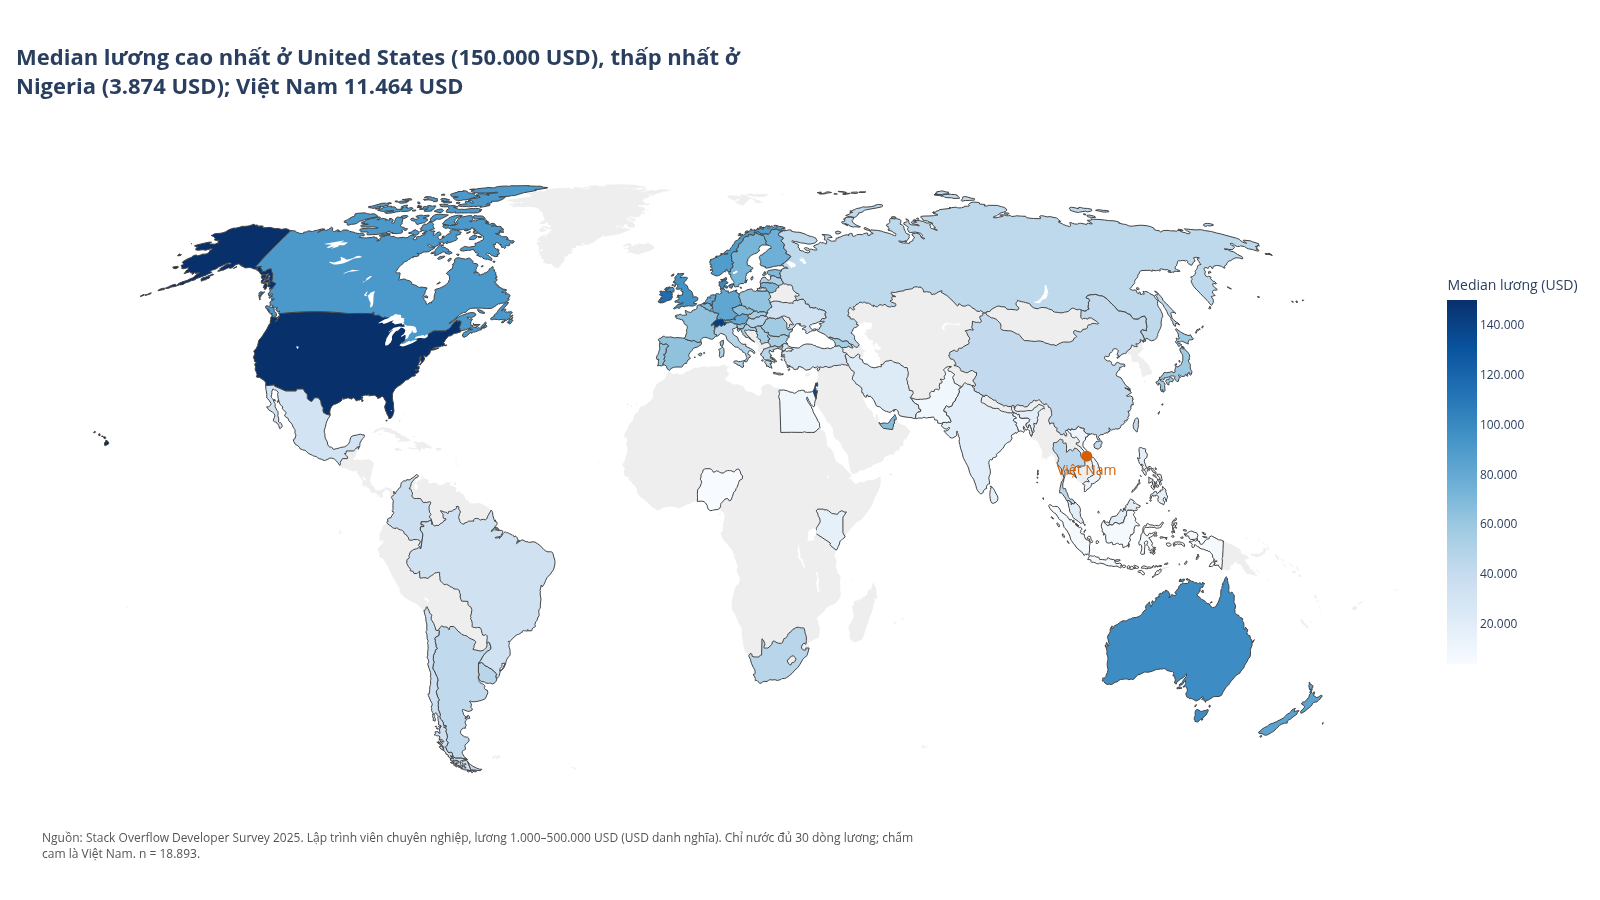

**Nhận xét.** Bản đồ có 62 nước đủ 30 dòng lương. Chênh lệch giữa nước cao nhất và thấp nhất là 38,7 lần. Việt Nam có median 11.464 USD (khoảng tin cậy 9.553–21.049, n = 31).

**Insight.** Quốc gia là yếu tố gắn với khác biệt lương lớn nhất; số liệu Việt Nam chỉ tham khảo vì mẫu nhỏ và lương là USD danh nghĩa.

In [34]:
finish(*fig_f7_1(by_country))

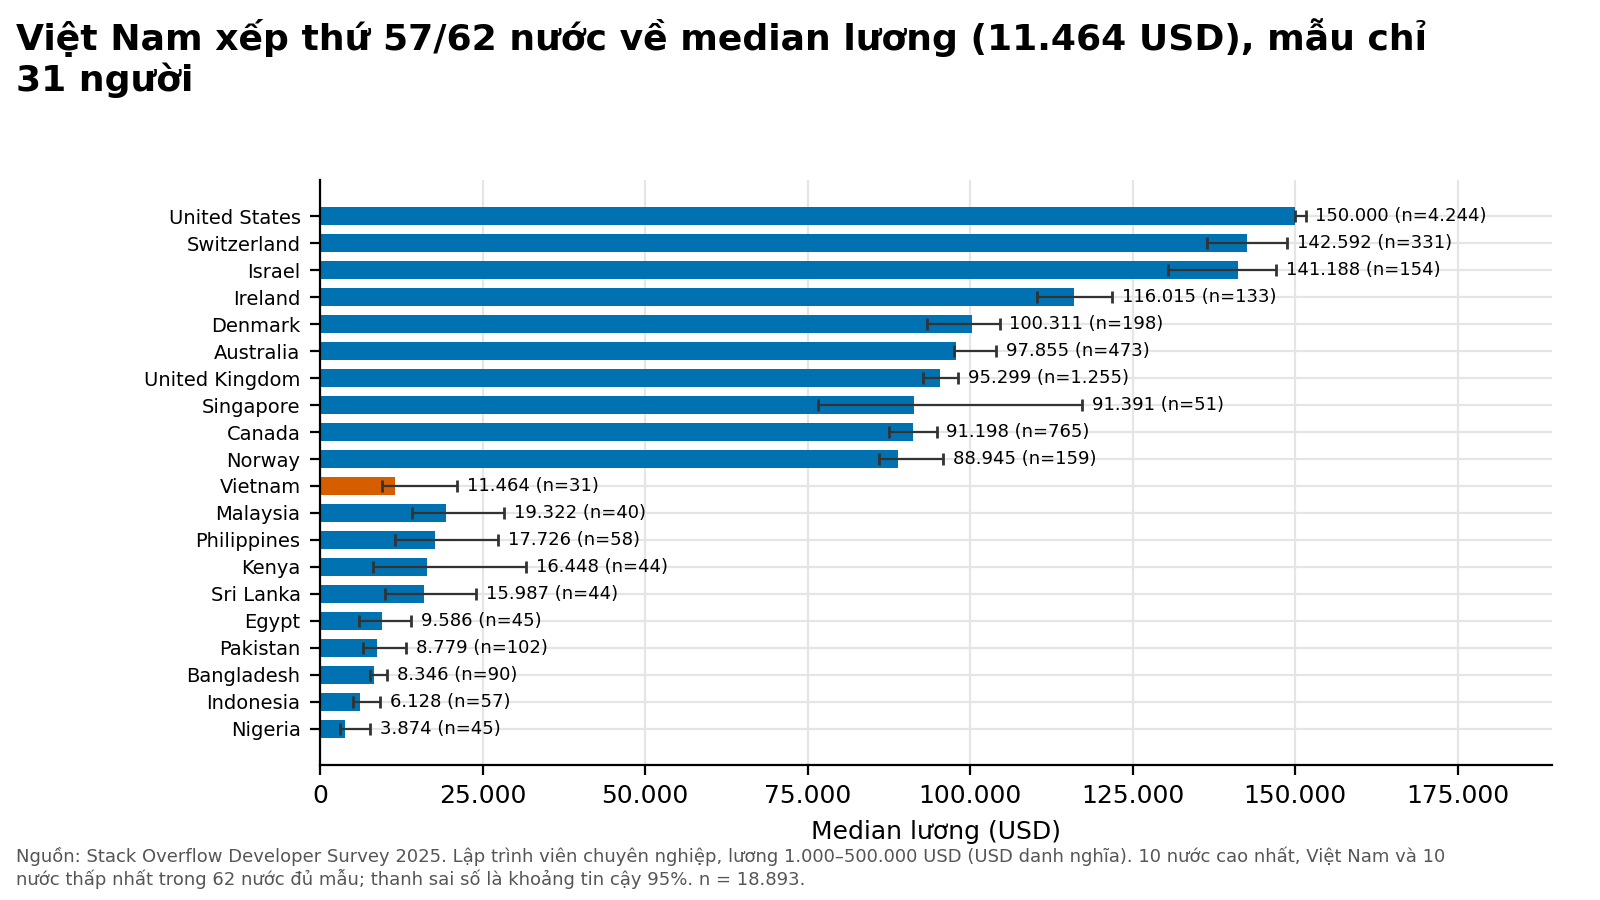

**Nhận xét.** Trong 62 nước đủ mẫu, Việt Nam ở nửa dưới bảng xếp hạng (median 11.464 USD). Thanh sai số cho thấy khoảng tin cậy của Việt Nam rất rộng (9.553–21.049 USD), nên thứ hạng có thể thay đổi nhiều.

**Insight.** Kỳ vọng lương nên so với mức sống và chi phí tại chỗ, không so trực tiếp bằng USD danh nghĩa với Mỹ hay châu Âu.

In [35]:
finish(*fig_f7_2(by_country))

## 5. Q8 – So sánh các vai trò
Spider chart dễ gây hiểu nhầm (thứ tự trục ảnh hưởng hình dạng, diện tích phóng đại chênh lệch), nên ta giữ dưới 5 trục, chỉ so sánh 3 vai trò,
chia mỗi trục cho giá trị cao nhất giữa các vai trò (trục bắt đầu từ 0 thật, không phóng đại chênh lệch) và đi kèm biểu đồ chấm có giá trị thật để đọc số chính xác.

In [36]:
@dataclass(frozen=True)
class Metric:
    """Một chỉ số của hồ sơ vai trò: tên cột kết quả, nhãn trục, đơn vị và số chữ số thập phân."""
    key: str
    label: str
    unit: str
    digits: int


METRICS = (
    Metric("median_sal", "Median lương", "USD", 0),
    Metric("median_exp", "Median kinh nghiệm", "năm", 0),
    Metric("ai_daily", "Dùng AI hằng ngày", "%", 0),
    Metric("mean_sat", "Hài lòng công việc (TB, 0–10)", "điểm", 1),
)
SPIDER_ROLES = 3
SPIDER_FILL_ALPHA = 0.25
SPIDER_LINE_WIDTH = 3
DOT_SIZE = 40
THOUSAND = 1000
CORR_WEAK = 0.3
CORR_STRONG = 0.6


def role_profile(df: pd.DataFrame, role_names: list) -> pd.DataFrame:
    """Hồ sơ 4 chỉ số cho từng vai trò."""
    rows = []
    for name in role_names:
        grp = df[df[Col.ROLE] == name]
        ai_answered = grp[Col.AI].dropna()
        rows.append({
            Col.ROLE: name, "n": len(grp),
            "median_sal": grp[Col.SAL].median(), "median_exp": grp[Col.WORKEXP].median(),
            "ai_daily": (ai_answered == AI_DAILY).mean() * 100, "mean_sat": grp[Col.JOBSAT].mean(),
        })
    return pd.DataFrame(rows)


def pick_spider_roles(profile: pd.DataFrame) -> list:
    """Chọn 3 vai trò tương phản: lương cao nhất, dùng AI nhiều nhất, dùng AI ít nhất."""
    picks = [profile.loc[profile.median_sal.idxmax(), Col.ROLE], profile.loc[profile.ai_daily.idxmax(), Col.ROLE],
             profile.loc[profile.ai_daily.idxmin(), Col.ROLE]]
    unique = list(dict.fromkeys(picks))
    rest = [r for r in profile.sort_values("n", ascending=False)[Col.ROLE] if r not in unique]
    return (unique + rest)[:SPIDER_ROLES]


def describe_corr(corr: float) -> str:
    """Diễn giải mức độ và chiều của hệ số tương quan."""
    strength = "gần như không liên hệ" if abs(corr) < CORR_WEAK else ("liên hệ vừa phải" if abs(corr) < CORR_STRONG else "liên hệ mạnh")
    direction = "" if abs(corr) < CORR_WEAK else (", cùng chiều" if corr > 0 else ", ngược chiều")
    return strength + direction


def scale_unit(profile: pd.DataFrame) -> pd.DataFrame:
    """Chia mỗi chỉ số cho giá trị cao nhất giữa các vai trò (0–1, trục bắt đầu từ 0 thật)."""
    keys = [m.key for m in METRICS]
    return profile[keys] / profile[keys].max()


def axis_text(metric: Metric, profile: pd.DataFrame) -> str:
    """Nhãn trục kèm dải giá trị thật (thấp nhất–cao nhất)."""
    lo, hi = profile[metric.key].min(), profile[metric.key].max()
    return f"{metric.label}<br>({fmt_num(lo, metric.digits)}–{fmt_num(hi, metric.digits)} {metric.unit})"

In [37]:
def fig_f8_1(profile: pd.DataFrame, picked: list):
    """f8_1: spider chart hồ sơ 3 vai trò trên 4 trục chuẩn hóa."""
    unit = scale_unit(profile)
    unit.index = profile[Col.ROLE]
    top_sal = profile.loc[profile.median_sal.idxmax()]
    top_ai = profile.loc[profile.ai_daily.idxmax()]
    low_ai = profile.loc[profile.ai_daily.idxmin()]
    n = int(profile.n.sum())
    spread = {m.label: (profile[m.key].max() - profile[m.key].min()) / profile[m.key].mean() for m in METRICS}
    flat = min(spread, key=spread.get)
    corr = profile.median_sal.corr(profile.ai_daily, method="spearman")
    note = Note(
        "f8_1", f"{top_ai[Col.ROLE]} dùng AI hằng ngày nhiều nhất ({fmt_pct(top_ai.ai_daily, 0)}), {top_sal[Col.ROLE]} có lương cao nhất",
        f"Trong {len(profile)} vai trò, tỷ lệ dùng AI hằng ngày từ {fmt_pct(low_ai.ai_daily, 0)} ({low_ai[Col.ROLE]}) đến {fmt_pct(top_ai.ai_daily, 0)} ({top_ai[Col.ROLE]}). "
        f"{top_sal[Col.ROLE]} có median lương cao nhất ({fmt_usd(top_sal.median_sal)}) và median kinh nghiệm {fmt_num(top_sal.median_exp, 0)} năm. "
        f"Chỉ số ít chênh lệch nhất giữa các vai trò là '{flat}' (khoảng cách cao nhất và thấp nhất bằng {fmt_pct(spread[flat] * 100, 0)} giá trị trung bình).",
        f"Hệ số tương quan hạng Spearman giữa median lương và tỷ lệ dùng AI hằng ngày qua {len(profile)} vai trò là {fmt_num(corr, 2)}: {describe_corr(corr)}.",
        sal_footer(n, f"{len(profile)} vai trò đủ {Cfg.min_role_n} dòng; mỗi trục chia cho giá trị cao nhất giữa {len(profile)} vai trò (đỉnh = 1), dải giá trị thật ghi cạnh tên trục."), n)
    theta = [axis_text(m, profile) for m in METRICS]
    fig = go.Figure()
    for color, name in zip(Pal.cat, picked):
        vals = unit.loc[name].tolist()
        fig.add_trace(go.Scatterpolar(r=vals + vals[:1], theta=theta + theta[:1], name=name, fill="toself", opacity=0.55,
                                      line={"color": color, "width": SPIDER_LINE_WIDTH}, fillcolor=hex_alpha(color, SPIDER_FILL_ALPHA)))
    fig.update_layout(polar={"domain": {"y": [0.14, 0.86]}, "radialaxis": {"visible": True, "range": [0, 1], "tickvals": [0, 0.5, 1], "tickfont": {"size": 12}},
                             "angularaxis": {"tickfont": {"size": 16}}},
                      legend={"font": {"size": 18}, "x": 0.82, "y": 0.9})
    export_table(profile, "f8_1")
    return style_plotly(fig, note), note


def fig_f8_2(profile: pd.DataFrame, picked: list):
    """f8_2: biểu đồ chấm giá trị thật của 4 chỉ số cho mọi vai trò, 3 vai trò chọn được tô màu."""
    note = Note(
        "f8_2", "Giá trị thật của 4 chỉ số: vai trò tô màu là 3 vai trò trong spider",
        "Mỗi ô con là một chỉ số; mỗi chấm là một vai trò, sắp theo giá trị. " + "; ".join(
            f"{m.label}: cao nhất {profile.loc[profile[m.key].idxmax(), Col.ROLE]} ({fmt_num(profile[m.key].max(), m.digits)}{'' if m.unit == '%' else ' '}{m.unit})" for m in METRICS) + ".",
        "Dùng biểu đồ này khi cần đọc số chính xác, vì spider chỉ phù hợp để so sánh hình dạng tổng quát.",
        sal_footer(int(profile.n.sum()), f"{len(profile)} vai trò đủ {Cfg.min_role_n} dòng; chấm màu là 3 vai trò ở biểu đồ spider."), int(profile.n.sum()))
    fig, axes = new_fig(note, ncols=len(METRICS), left=0.17)
    fig.subplots_adjust(wspace=0.25)
    order = profile.sort_values("median_sal")[Col.ROLE].tolist()
    colors = {name: Pal.cat[i] for i, name in enumerate(picked)}
    for ax, metric in zip(axes, METRICS):
        values = profile.set_index(Col.ROLE).loc[order, metric.key]
        is_salary = metric.key == "median_sal"
        ax.scatter(values / (THOUSAND if is_salary else 1), range(len(order)), s=DOT_SIZE, color=[colors.get(r, Pal.neutral) for r in order], zorder=3)
        ax.set_title(f"{metric.label} ({'nghìn USD' if is_salary else metric.unit})" if "(" not in metric.label else metric.label, fontsize=7, loc="left")
        ax.set_yticks(range(len(order)), order if ax is axes[0] else [], fontsize=7)
        ax.tick_params(axis="x", labelsize=7)
        ax.locator_params(axis="x", nbins=4)
    export_table(profile, "f8_2")
    return fig, note

In [38]:
profile = role_profile(df_sal, roles)
picked_roles = pick_spider_roles(profile)
display(profile.round(1))
print("3 vai trò vẽ spider:", picked_roles)

,role,n,median_sal,median_exp,ai_daily,mean_sat
0,Full-stack,7075,73375.0,10.0,53.7,7.2
1,Back-end,3763,80050.0,10.0,50.1,7.1
2,Architect,1353,100237.0,18.0,53.7,7.5
3,Desktop/enterprise,1056,75410.0,14.0,33.8,7.2
4,Front-end,1043,65496.0,9.0,60.7,7.0
5,Mobile,716,71964.5,10.0,55.3,7.2
6,Embedded,712,81210.0,10.0,29.5,7.1
7,Engineering manager,493,133417.0,17.0,57.9,7.3
8,DevOps,487,92812.0,12.0,50.1,7.3
9,Data engineer,415,81210.0,10.0,54.9,7.2


3 vai trò vẽ spider: ['Engineering manager', 'AI/ML engineer', 'Embedded']


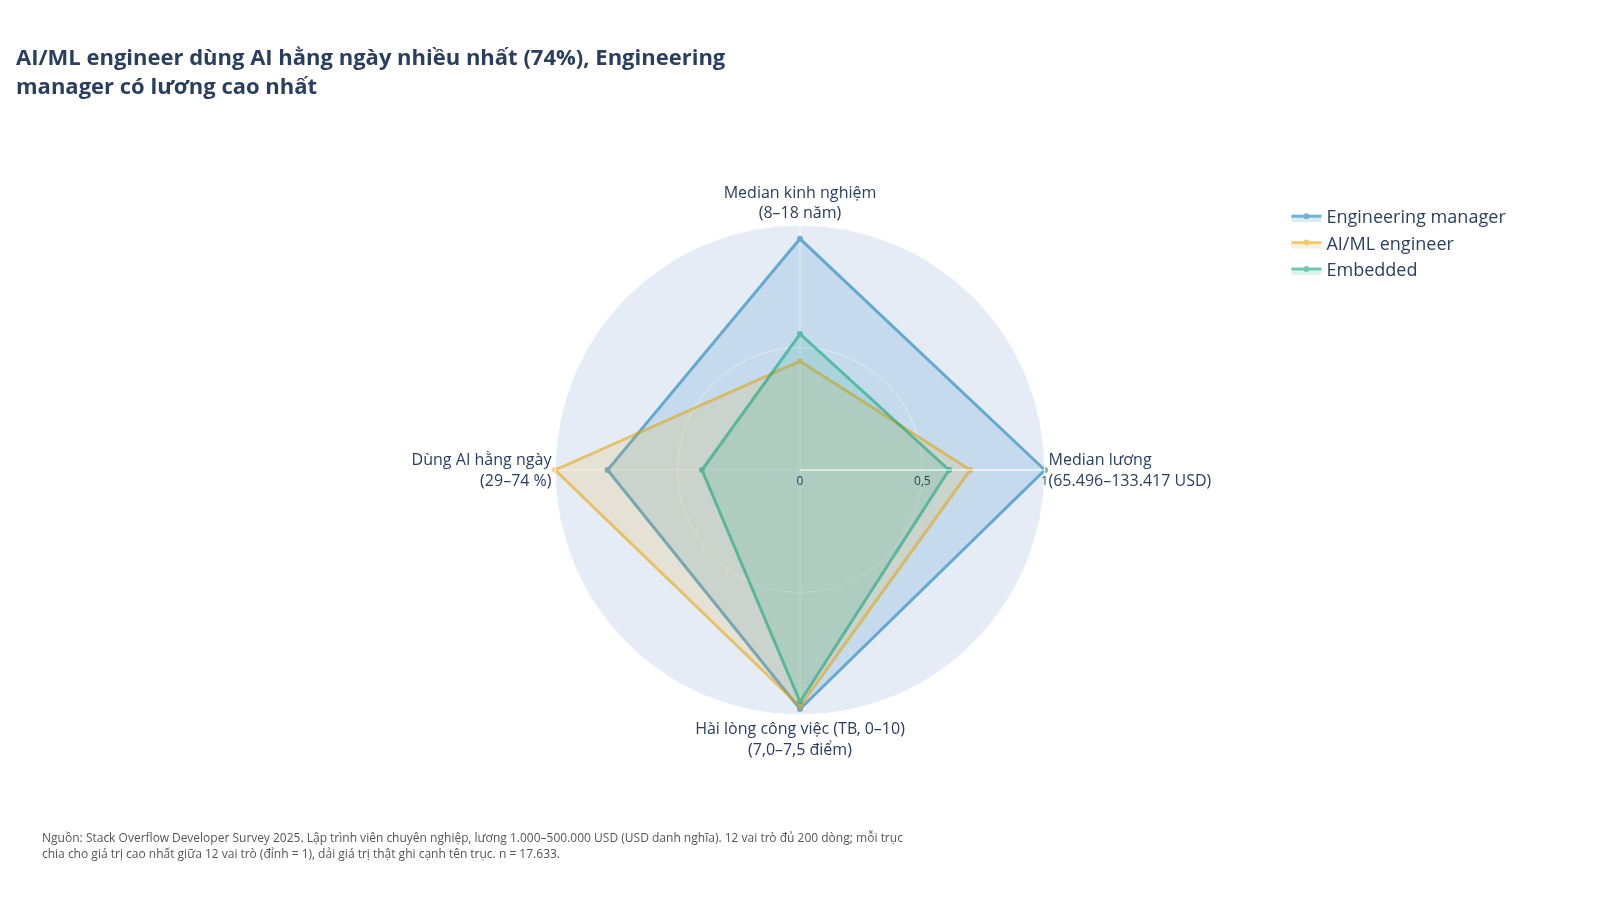

**Nhận xét.** Trong 12 vai trò, tỷ lệ dùng AI hằng ngày từ 29% (Embedded) đến 74% (AI/ML engineer). Engineering manager có median lương cao nhất (133.417 USD) và median kinh nghiệm 17 năm. Chỉ số ít chênh lệch nhất giữa các vai trò là 'Hài lòng công việc (TB, 0–10)' (khoảng cách cao nhất và thấp nhất bằng 6% giá trị trung bình).

**Insight.** Hệ số tương quan hạng Spearman giữa median lương và tỷ lệ dùng AI hằng ngày qua 12 vai trò là 0,08: gần như không liên hệ.

In [39]:
finish(*fig_f8_1(profile, picked_roles))

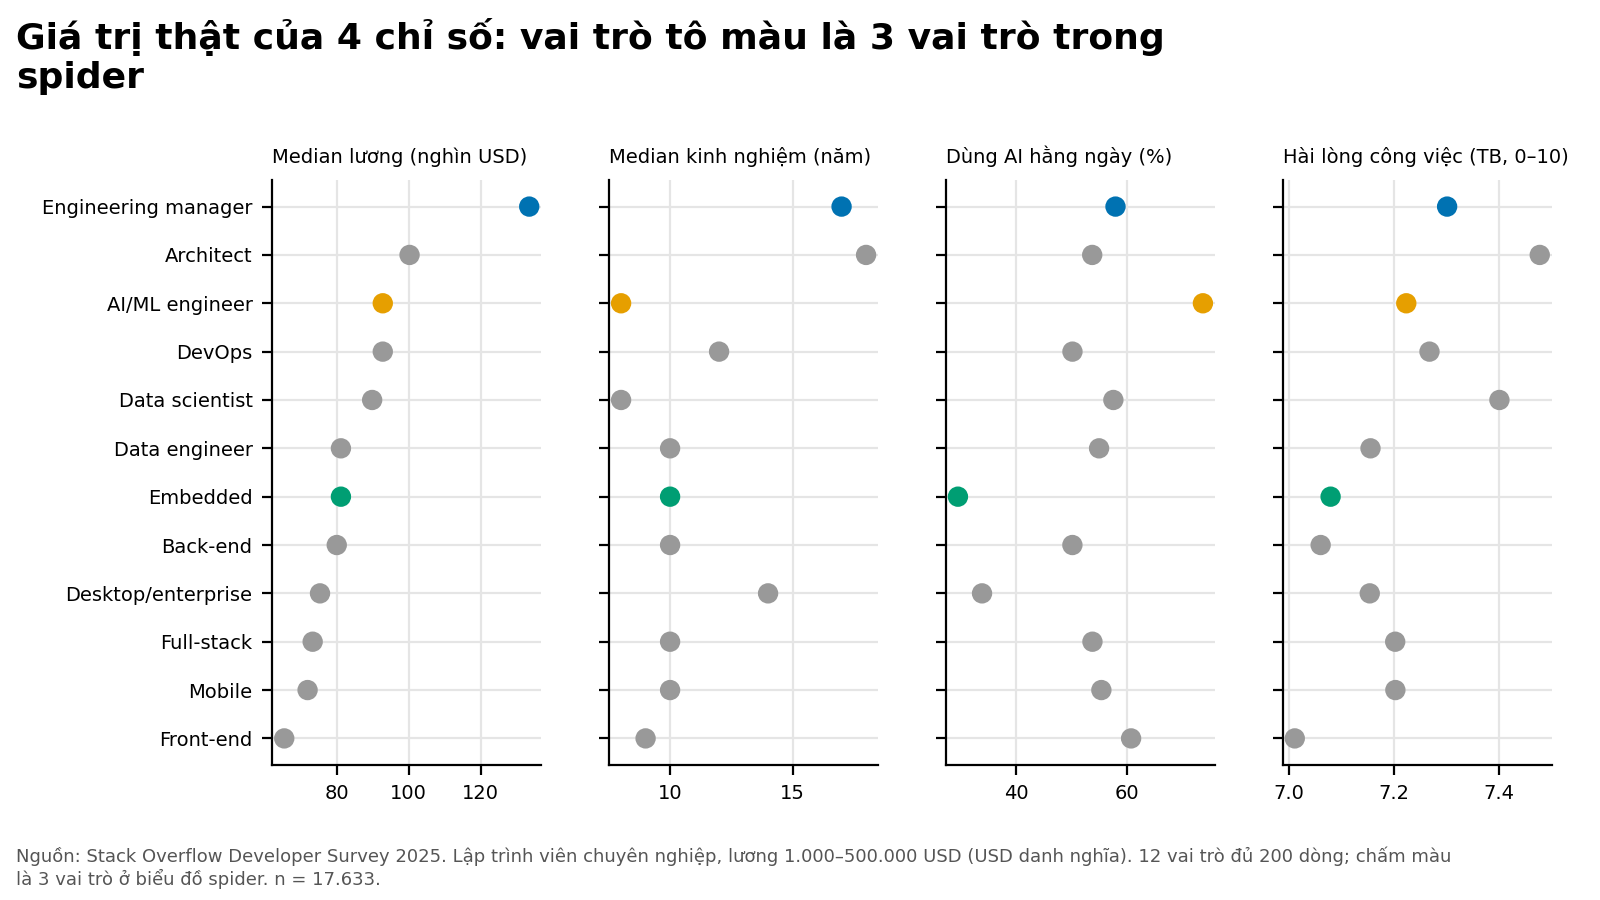

**Nhận xét.** Mỗi ô con là một chỉ số; mỗi chấm là một vai trò, sắp theo giá trị. Median lương: cao nhất Engineering manager (133.417 USD); Median kinh nghiệm: cao nhất Architect (18 năm); Dùng AI hằng ngày: cao nhất AI/ML engineer (74%); Hài lòng công việc (TB, 0–10): cao nhất Architect (7,5 điểm).

**Insight.** Dùng biểu đồ này khi cần đọc số chính xác, vì spider chỉ phù hợp để so sánh hình dạng tổng quát.

In [40]:
finish(*fig_f8_2(profile, picked_roles))

## 6. Q6 (tiếp) – Hồi quy kiểm chứng: lương phụ thuộc vào đâu?
Giả thuyết cần kiểm chứng: **quốc gia và kinh nghiệm đi cùng chênh lệch lương nhiều hơn ngôn ngữ lập trình**.
Ta so sánh độ phù hợp (R²) của các mô hình `log(lương)` với từng nhóm biến, rồi xem hệ số của ngôn ngữ sau khi đã cố định quốc gia và kinh nghiệm.
Đây là mô hình mô tả, không chứng minh quan hệ nhân quả; `log(lương)` để hệ số đọc được như % chênh lệch.

In [41]:
import statsmodels.formula.api as smf

REG_LANGS = 15
Z_CRIT = 1.96
SUPERSCRIPT = str.maketrans("-0123456789", "⁻⁰¹²³⁴⁵⁶⁷⁸⁹")
HC_TYPE = "HC3"


@dataclass(frozen=True)
class ModelSpec:
    """Một mô hình hồi quy: nhãn hiển thị và vế phải của công thức."""
    label: str
    rhs: str


@dataclass
class RegResult:
    """Kết quả hồi quy: R² từng mô hình, hệ số ngôn ngữ và kiểm định nhóm biến."""
    r2: pd.DataFrame
    effects: pd.DataFrame
    f_pvalue: float
    n: int


def reg_frame(df: pd.DataFrame, names: list):
    """Dựng bảng hồi quy: log lương, nước, kinh nghiệm và cột 0/1 cho từng ngôn ngữ phổ biến."""
    base = df[df[Col.COUNTRY].isin(names)].dropna(subset=[Col.WORKEXP, Col.LANG_HAVE])[[Col.ID, Col.COUNTRY, Col.WORKEXP, Col.SAL, Col.LANG_HAVE]].copy()
    longer = explode_multi(base, Col.LANG_HAVE)
    top = longer[Col.VALUE].value_counts().head(REG_LANGS).index.tolist()
    flags = pd.crosstab(longer[Col.ID], longer[Col.VALUE])[top].clip(upper=1)
    flags.columns = [f"L{i}" for i in range(len(top))]
    frame = base.set_index(Col.ID).join(flags).fillna(0)
    frame["ly"] = np.log(frame[Col.SAL])
    frame["lexp"] = np.log1p(frame[Col.WORKEXP])
    return frame, top, list(flags.columns)


def fit_models(frame: pd.DataFrame, lang_cols: list) -> dict:
    """Ước lượng các mô hình OLS."""
    langs = " + ".join(lang_cols)
    specs = (
        ModelSpec("Chỉ ngôn ngữ", langs),
        ModelSpec("Chỉ kinh nghiệm", "lexp"),
        ModelSpec("Chỉ quốc gia", f"C({Col.COUNTRY})"),
        ModelSpec("Quốc gia + kinh nghiệm", f"C({Col.COUNTRY}) + lexp"),
        ModelSpec("Quốc gia + kinh nghiệm + ngôn ngữ", f"C({Col.COUNTRY}) + lexp + {langs}"),
    )
    return {spec.label: smf.ols(f"ly ~ {spec.rhs}", frame).fit() for spec in specs}


def run_regression(df: pd.DataFrame, names: list) -> RegResult:
    """Chạy toàn bộ phân tích hồi quy và gom kết quả."""
    frame, top, lang_cols = reg_frame(df, names)
    models = fit_models(frame, lang_cols)
    labels = list(models)
    full, base = models[labels[-1]], models[labels[-2]]
    robust = smf.ols(full.model.formula, frame).fit(cov_type=HC_TYPE)
    effects = []
    for name, col in zip(top, lang_cols):
        coef, se = robust.params[col], robust.bse[col]
        effects.append({"lang": name, "pct": (np.exp(coef) - 1) * 100,
                        "lo": (np.exp(coef - Z_CRIT * se) - 1) * 100, "hi": (np.exp(coef + Z_CRIT * se) - 1) * 100})
    r2 = pd.DataFrame({"model": labels, "r2": [models[k].rsquared for k in labels]})
    return RegResult(r2, pd.DataFrame(effects).sort_values("pct"), float(full.compare_f_test(base)[1]), int(full.nobs))

In [42]:
reg = run_regression(df_sal, countries)
display(reg.r2.round(3))
print(f"n = {fmt_int(reg.n)} | p-value kiểm định F cho nhóm {REG_LANGS} ngôn ngữ: {reg.f_pvalue:.3g}")

,model,r2
0,Chỉ ngôn ngữ,0.046
1,Chỉ kinh nghiệm,0.182
2,Chỉ quốc gia,0.449
3,Quốc gia + kinh nghiệm,0.522
4,Quốc gia + kinh nghiệm + ngôn ngữ,0.547


n = 17.540 | p-value kiểm định F cho nhóm 15 ngôn ngữ: 2.99e-195


In [43]:
def fmt_sci(value: float) -> str:
    """Số rất nhỏ dạng khoa học kiểu 3 × 10⁻¹⁹⁵."""
    mantissa, exponent = f"{value:.0e}".split("e")
    return f"{mantissa} × 10{str(int(exponent)).translate(SUPERSCRIPT)}"


def fig_f6_3(result: RegResult):
    """f6_3: R² của các mô hình, tách phần giải thích của quốc gia, kinh nghiệm và ngôn ngữ."""
    r2 = result.r2.set_index("model").r2
    only_lang, only_exp, only_country, country_exp, full = r2.iloc[0], r2.iloc[1], r2.iloc[2], r2.iloc[3], r2.iloc[4]
    supported = only_country > only_lang and (full - country_exp) < (country_exp - only_country)
    verdict = ("Giả thuyết được ủng hộ: để dự đoán lương, biết người đó ở nước nào và có bao nhiêu năm kinh nghiệm quan trọng hơn nhiều so với biết họ dùng ngôn ngữ gì."
               if supported else "Giả thuyết không được ủng hộ rõ: phần giải thích thêm của ngôn ngữ không nhỏ hơn phần của quốc gia và kinh nghiệm.")
    note = Note(
        "f6_3", f"Quốc gia một mình giải thích {fmt_pct(only_country * 100, 0)} biến thiên lương; thêm {REG_LANGS} ngôn ngữ chỉ cộng {fmt_num((full - country_exp) * 100)} điểm phần trăm",
        f"R² của mô hình chỉ có ngôn ngữ là {fmt_pct(only_lang * 100)}, chỉ kinh nghiệm {fmt_pct(only_exp * 100)}, chỉ quốc gia {fmt_pct(only_country * 100)}. "
        f"Thêm kinh nghiệm vào quốc gia tăng R² lên {fmt_pct(country_exp * 100)}, thêm ngôn ngữ chỉ tăng thêm {fmt_num((full - country_exp) * 100)} điểm phần trăm (kiểm định F cho nhóm ngôn ngữ: p = {fmt_sci(result.f_pvalue)}).",
        verdict + " Đây là mô hình mô tả, không chứng minh nhân quả.",
        sal_footer(result.n, f"Hồi quy OLS trên log(lương); nước đủ {Cfg.min_country_n} dòng; {REG_LANGS} ngôn ngữ phổ biến nhất; kinh nghiệm dùng log(1 + WorkExp)."), result.n)
    fig, ax = new_fig(note, left=0.24)
    values = (r2 * 100)[::-1]
    values.index = [name.replace(" + ngôn ngữ", "\n+ ngôn ngữ") for name in values.index]
    colors = [Pal.accent if "+ ngôn ngữ" in name else Pal.neutral for name in values.index]
    ax.barh(values.index, values.to_numpy(), color=colors, height=BAR_HEIGHT)
    annotate_bars_h(ax, values.to_numpy(), [fmt_pct(v) for v in values])
    ax.set_xlabel("R² (% biến thiên của log(lương) được giải thích)")
    ax.set_xlim(0, values.max() * 1.15)
    export_table(result.r2, "f6_3")
    return fig, note


def fig_f6_4(result: RegResult):
    """f6_4: tác động của từng ngôn ngữ lên lương sau khi cố định quốc gia và kinh nghiệm."""
    eff = result.effects
    sig = eff[(eff.lo > 0) | (eff.hi < 0)]
    note = Note(
        "f6_4", f"Sau khi cố định nước và kinh nghiệm, chênh lệch lương theo ngôn ngữ chỉ từ {fmt_pct(eff.pct.min(), 0)} đến {fmt_pct(eff.pct.max(), 0)}",
        f"Hệ số của {len(eff)} ngôn ngữ nằm trong khoảng {fmt_pct(eff.pct.min())} đến {fmt_pct(eff.pct.max())} so với người không dùng ngôn ngữ đó. "
        f"{len(sig)}/{len(eff)} ngôn ngữ có khoảng tin cậy 95% không chứa 0" + (f": {', '.join(sig.sort_values('pct', ascending=False).lang)}." if len(sig) else "."),
        f"Chênh lệch lương đi cùng việc dùng một ngôn ngữ (tối đa {fmt_pct(max(abs(eff.pct.min()), abs(eff.pct.max())), 0)}) nhỏ hơn nhiều so với chênh lệch giữa các nước ở bản đồ lương theo nước (hai đại lượng tính khác nhau nên chỉ so sánh tham khảo); chọn ngôn ngữ nên dựa trên mức phổ biến và sở thích hơn là kỳ vọng tăng lương.",
        sal_footer(result.n, "Hệ số từ hồi quy log(lương) có kiểm soát nước và kinh nghiệm, quy ra % chênh lệch so với người không dùng ngôn ngữ đó; thanh là khoảng tin cậy 95% (sai số chuẩn HC3)."), result.n)
    fig, ax = new_fig(note, left=0.17)
    err = np.vstack([eff.pct - eff.lo, eff.hi - eff.pct])
    colors = [Pal.accent if (lo > 0 or hi < 0) else Pal.neutral for lo, hi in zip(eff.lo, eff.hi)]
    ax.errorbar(eff.pct, eff.lang, xerr=err, fmt="none", ecolor="#333333", capsize=2, linewidth=1, zorder=2)
    ax.scatter(eff.pct, eff.lang, color=colors, s=DOT_SIZE, zorder=3)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Chênh lệch lương khi dùng ngôn ngữ (%), đã kiểm soát nước và kinh nghiệm")
    ax.tick_params(axis="y", labelsize=7)
    export_table(eff, "f6_4")
    return fig, note

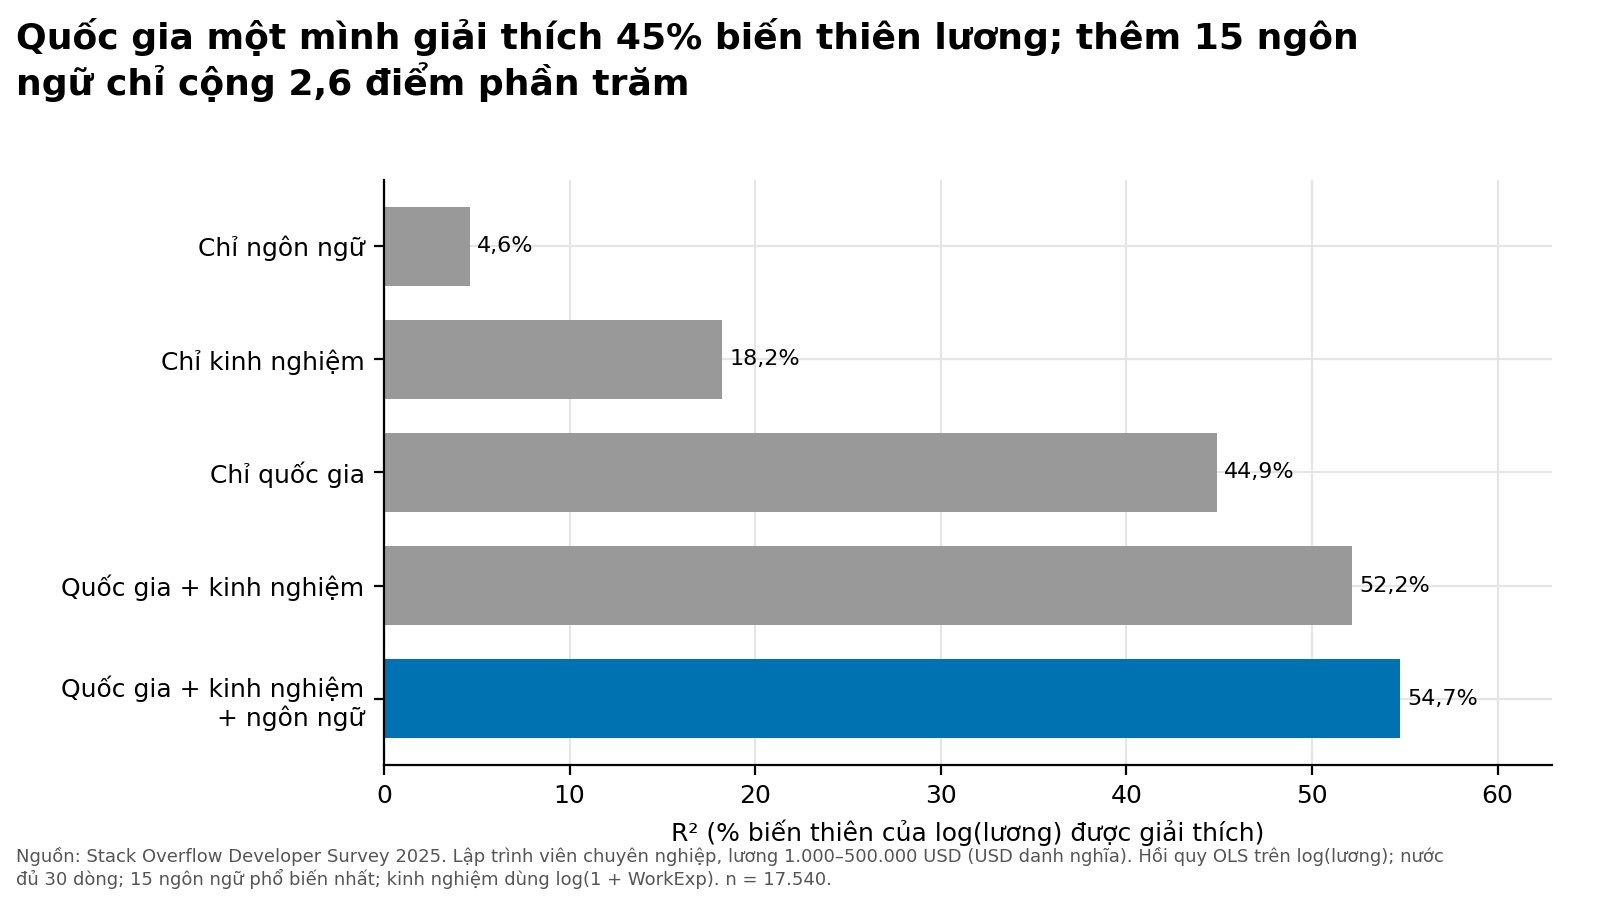

**Nhận xét.** R² của mô hình chỉ có ngôn ngữ là 4,6%, chỉ kinh nghiệm 18,2%, chỉ quốc gia 44,9%. Thêm kinh nghiệm vào quốc gia tăng R² lên 52,2%, thêm ngôn ngữ chỉ tăng thêm 2,6 điểm phần trăm (kiểm định F cho nhóm ngôn ngữ: p = 3 × 10⁻¹⁹⁵).

**Insight.** Giả thuyết được ủng hộ: để dự đoán lương, biết người đó ở nước nào và có bao nhiêu năm kinh nghiệm quan trọng hơn nhiều so với biết họ dùng ngôn ngữ gì. Đây là mô hình mô tả, không chứng minh nhân quả.

In [44]:
finish(*fig_f6_3(reg))

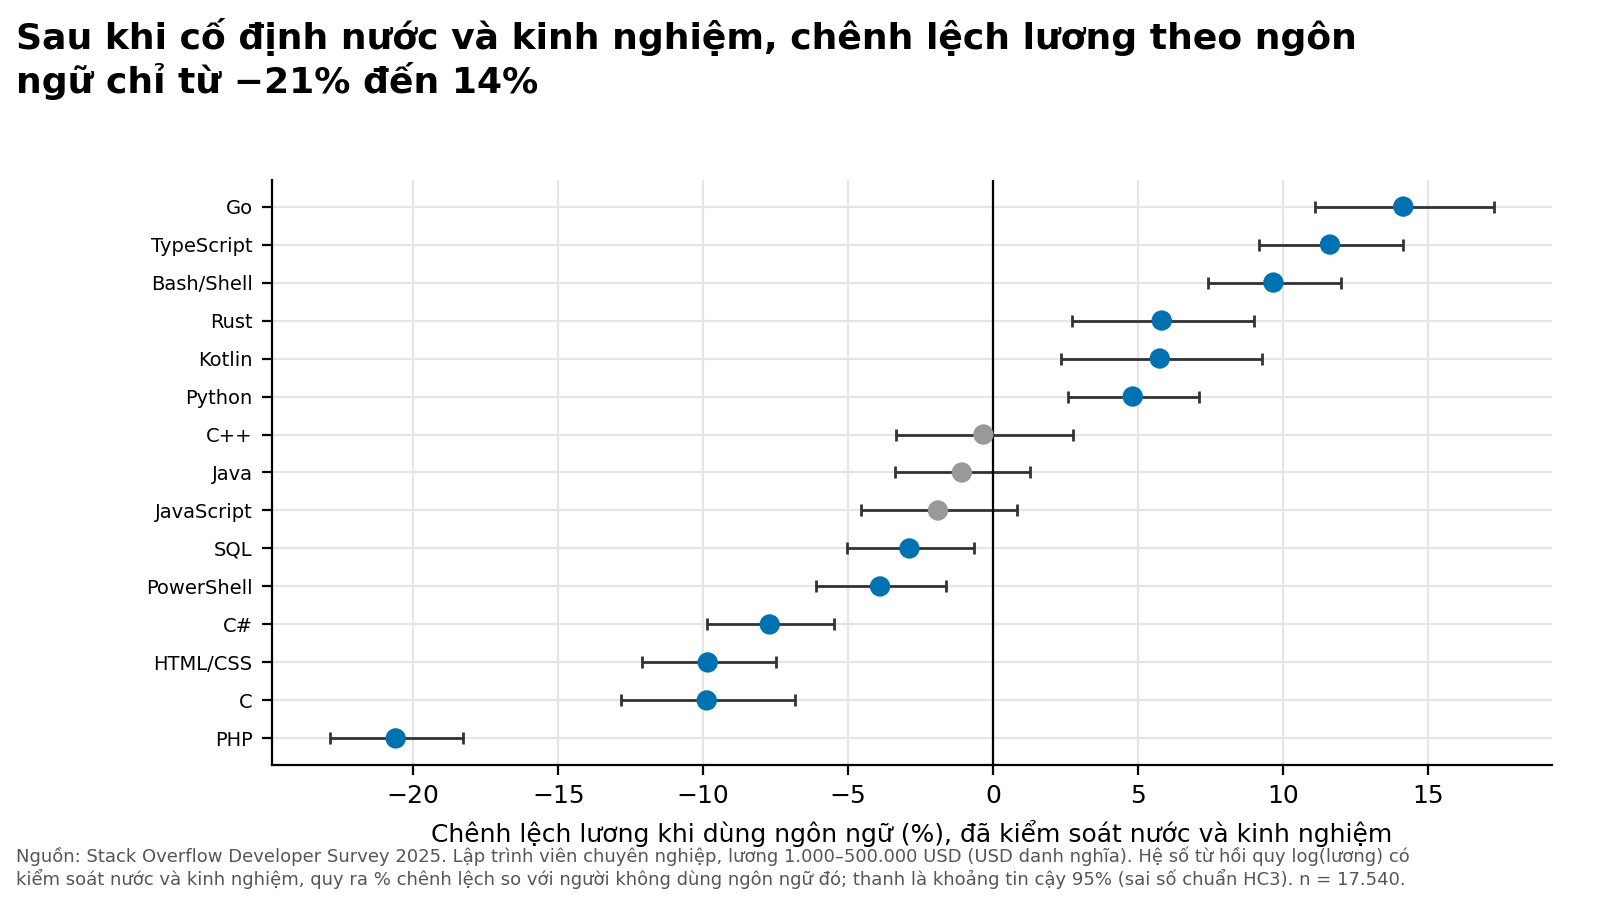

**Nhận xét.** Hệ số của 15 ngôn ngữ nằm trong khoảng −20,6% đến 14,1% so với người không dùng ngôn ngữ đó. 12/15 ngôn ngữ có khoảng tin cậy 95% không chứa 0: Go, TypeScript, Bash/Shell, Rust, Kotlin, Python, SQL, PowerShell, C#, HTML/CSS, C, PHP.

**Insight.** Chênh lệch lương đi cùng việc dùng một ngôn ngữ (tối đa 21%) nhỏ hơn nhiều so với chênh lệch giữa các nước ở bản đồ lương theo nước (hai đại lượng tính khác nhau nên chỉ so sánh tham khảo); chọn ngôn ngữ nên dựa trên mức phổ biến và sở thích hơn là kỳ vọng tăng lương.

In [45]:
finish(*fig_f6_4(reg))

## 7. Q9 – AI và kỹ năng còn giá trị trong 3–5 năm tới
Câu hỏi mở `AIOpen`: "Looking ahead 3–5 years, what skills do you believe will remain valuable…". Ta đếm số câu trả lời chứa mỗi từ (một câu chỉ tính một lần cho mỗi từ),
bỏ từ dừng tiếng Anh và một số từ chung chung. Wordcloud chỉ cho biết tần suất từ, không cho biết bối cảnh, nên đi kèm bảng tần suất.

In [46]:
from collections import Counter

from wordcloud import STOPWORDS, WordCloud

TOKEN_RE = re.compile(r"[a-z][a-z+#\-]{2,}|\bai\b|\bml\b")
EXTRA_STOP = frozenset((
    "will", "still", "able", "need", "needs", "good", "don", "even", "use", "new", "things", "thing", "work", "level",
    "know", "also", "like", "one", "would", "can", "much", "many", "just", "get", "make", "way", "lot", "really", "better",
    "best", "skills", "skill", "remain", "valuable", "think", "people", "something", "may", "might", "etc", "bit", "well",
))
MAX_CHARS = 2000
CLOUD_W = 1500
CLOUD_H = 560
CLOUD_WORDS = 80
CLOUD_SCALING = 0.2
CLOUD_MAX_FONT = 150
TOP_WORDS = 20
HIGHLIGHT_WORDS = 5
FOUNDATION_WORDS = frozenset(("understanding", "problem", "solving", "thinking", "design", "architecture", "debugging", "critical", "communication", "knowledge"))
PHRASE_PROBLEM = re.compile(r"problem[- ]solving")
PHRASE_CRITICAL = re.compile(r"critical thinking")


def tokenise(texts: pd.Series) -> list:
    """Tách mỗi câu trả lời thành tập từ viết thường, đã gộp số nhiều và bỏ từ dừng."""
    raw = [set(TOKEN_RE.findall(text[:MAX_CHARS].lower())) for text in texts]
    vocab = set().union(*raw)
    stop = STOPWORDS | EXTRA_STOP
    return [{(w[:-1] if w.endswith("s") and w[:-1] in vocab else w) for w in words} - stop for words in raw]


def word_table(texts: pd.Series) -> pd.DataFrame:
    """Bảng số câu trả lời chứa từng từ."""
    counts = Counter(word for words in tokenise(texts) for word in words)
    table = pd.DataFrame(counts.most_common(), columns=["word", "responses"])
    table["pct"] = table.responses / len(texts) * 100
    return table


def phrase_share(texts: pd.Series, pattern) -> float:
    """Tỷ lệ % câu trả lời chứa một cụm từ."""
    return float(texts.str.lower().str.contains(pattern).mean() * 100)


def cloud_colors(top_words: set):
    """Hàm màu: từ nổi bật dùng màu nhấn phụ, còn lại màu nhấn chính."""
    def pick(word, **_):
        return Pal.accent2 if word in top_words else Pal.accent
    return pick

In [47]:
def fig_f9_1(table: pd.DataFrame, n: int):
    """f9_1: wordcloud các kỹ năng được cho là còn giá trị."""
    top = table.head(HIGHLIGHT_WORDS)
    hits = [w for w in table.word.head(TOP_WORDS) if w in FOUNDATION_WORDS]
    note = Note(
        "f9_1", f"{', '.join(top.word[:3])} là những từ được nhắc nhiều nhất khi nói về kỹ năng còn giá trị",
        f"Từ '{top.word.iloc[0]}' xuất hiện trong {fmt_pct(top.pct.iloc[0])} số câu trả lời, '{top.word.iloc[1]}' {fmt_pct(top.pct.iloc[1])}, '{top.word.iloc[2]}' {fmt_pct(top.pct.iloc[2])} (trên {fmt_int(n)} câu trả lời). "
        "Wordcloud chỉ phản ánh tần suất từ, không cho biết ngữ cảnh (xem bảng tần suất từ khóa đi kèm).",
        f"Trong {TOP_WORDS} từ đầu có {len(hits)} từ thuộc nhóm năng lực nền tảng do nhóm tự phân loại ({', '.join(hits)}; 'problem' và 'solving' thường đi thành cụm 'problem solving'); đây là ý kiến tự do của người trả lời, không phải dự báo.",
        source_line(n, f"Câu hỏi mở AIOpen; đếm số câu trả lời chứa từ; bỏ từ dừng và từ chung chung; {HIGHLIGHT_WORDS} từ nổi bật tô màu cam."), n)
    cloud = WordCloud(width=CLOUD_W, height=CLOUD_H, background_color="white", max_words=CLOUD_WORDS, random_state=Cfg.seed,
                      color_func=cloud_colors(set(top.word)), prefer_horizontal=0.9, relative_scaling=CLOUD_SCALING, max_font_size=CLOUD_MAX_FONT)
    cloud.generate_from_frequencies(dict(zip(table.word, table.responses)))
    fig, ax = new_fig(note, left=0.02)
    ax.imshow(cloud.to_array(), interpolation="bilinear")
    ax.axis("off")
    return fig, note


def fig_f9_2(table: pd.DataFrame, n: int):
    """f9_2: top từ khóa trong câu trả lời về kỹ năng."""
    top = table.head(TOP_WORDS)[::-1]
    note = Note(
        "f9_2", f"Top {TOP_WORDS} từ khóa: {', '.join(table.word[:4])} dẫn đầu",
        f"{TOP_WORDS} từ đầu có mặt trong từ {fmt_pct(table.pct.iloc[TOP_WORDS - 1], 1)} đến {fmt_pct(table.pct.iloc[0], 1)} số câu trả lời. "
        f"{TOP_WORDS} từ đầu gồm: {', '.join(table.word.head(TOP_WORDS))}.",
        "Bảng tần suất bổ sung bối cảnh cho wordcloud: tỷ lệ phần trăm cho thấy mức độ phổ biến thật của từng từ.",
        source_line(n, f"Câu hỏi mở AIOpen; tỷ lệ = số câu trả lời chứa từ / tổng số câu trả lời; bỏ từ dừng và từ chung chung."), n)
    fig, ax = new_fig(note, left=0.16)
    ax.barh(top.word, top.pct, color=Pal.accent, height=BAR_HEIGHT)
    annotate_bars_h(ax, top.pct.to_numpy(), [fmt_pct(v) for v in top.pct])
    ax.set_xlabel("Tỷ lệ câu trả lời chứa từ (%)")
    ax.set_xlim(0, top.pct.max() * 1.12)
    return fig, note

In [48]:
open_texts = df_all[Col.AIOPEN].dropna().astype(str)
words = word_table(open_texts)
export_table(words.head(200), "f9_2")
print(f"Số câu trả lời AIOpen: {fmt_int(len(open_texts))} | Số từ khác nhau: {fmt_int(len(words))}")

Số câu trả lời AIOpen: 22.540 | Số từ khác nhau: 10.011


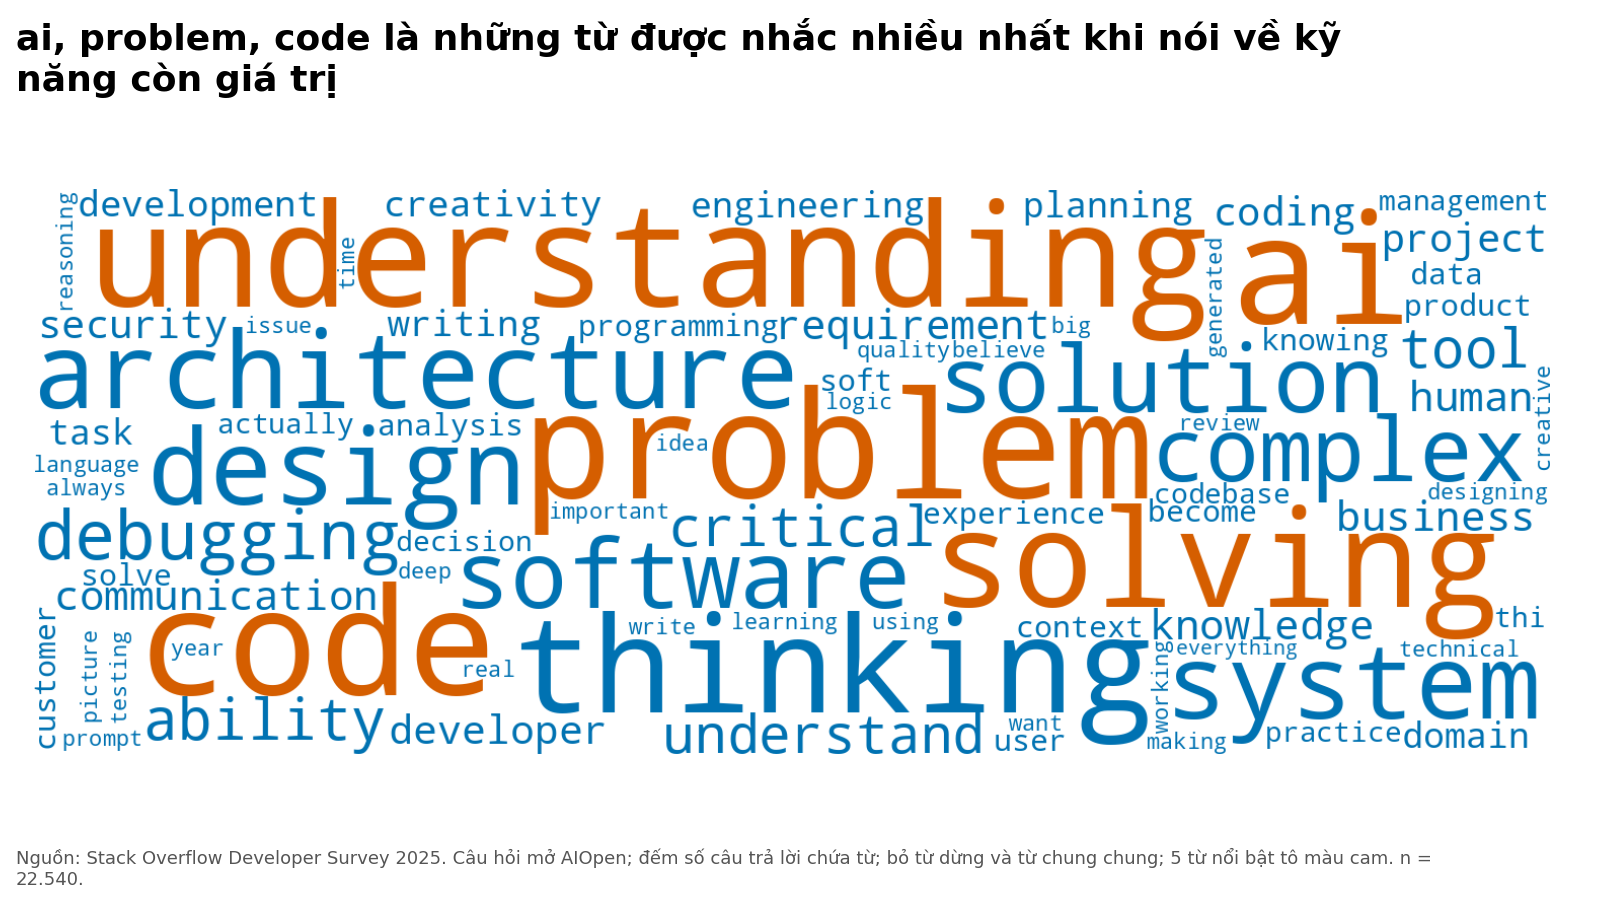

**Nhận xét.** Từ 'ai' xuất hiện trong 20,9% số câu trả lời, 'problem' 19,3%, 'code' 19,2% (trên 22.540 câu trả lời). Wordcloud chỉ phản ánh tần suất từ, không cho biết ngữ cảnh (xem bảng tần suất từ khóa đi kèm).

**Insight.** Trong 20 từ đầu có 9 từ thuộc nhóm năng lực nền tảng do nhóm tự phân loại (problem, understanding, solving, thinking, architecture, design, debugging, critical, communication; 'problem' và 'solving' thường đi thành cụm 'problem solving'); đây là ý kiến tự do của người trả lời, không phải dự báo.

In [49]:
finish(*fig_f9_1(words, len(open_texts)))

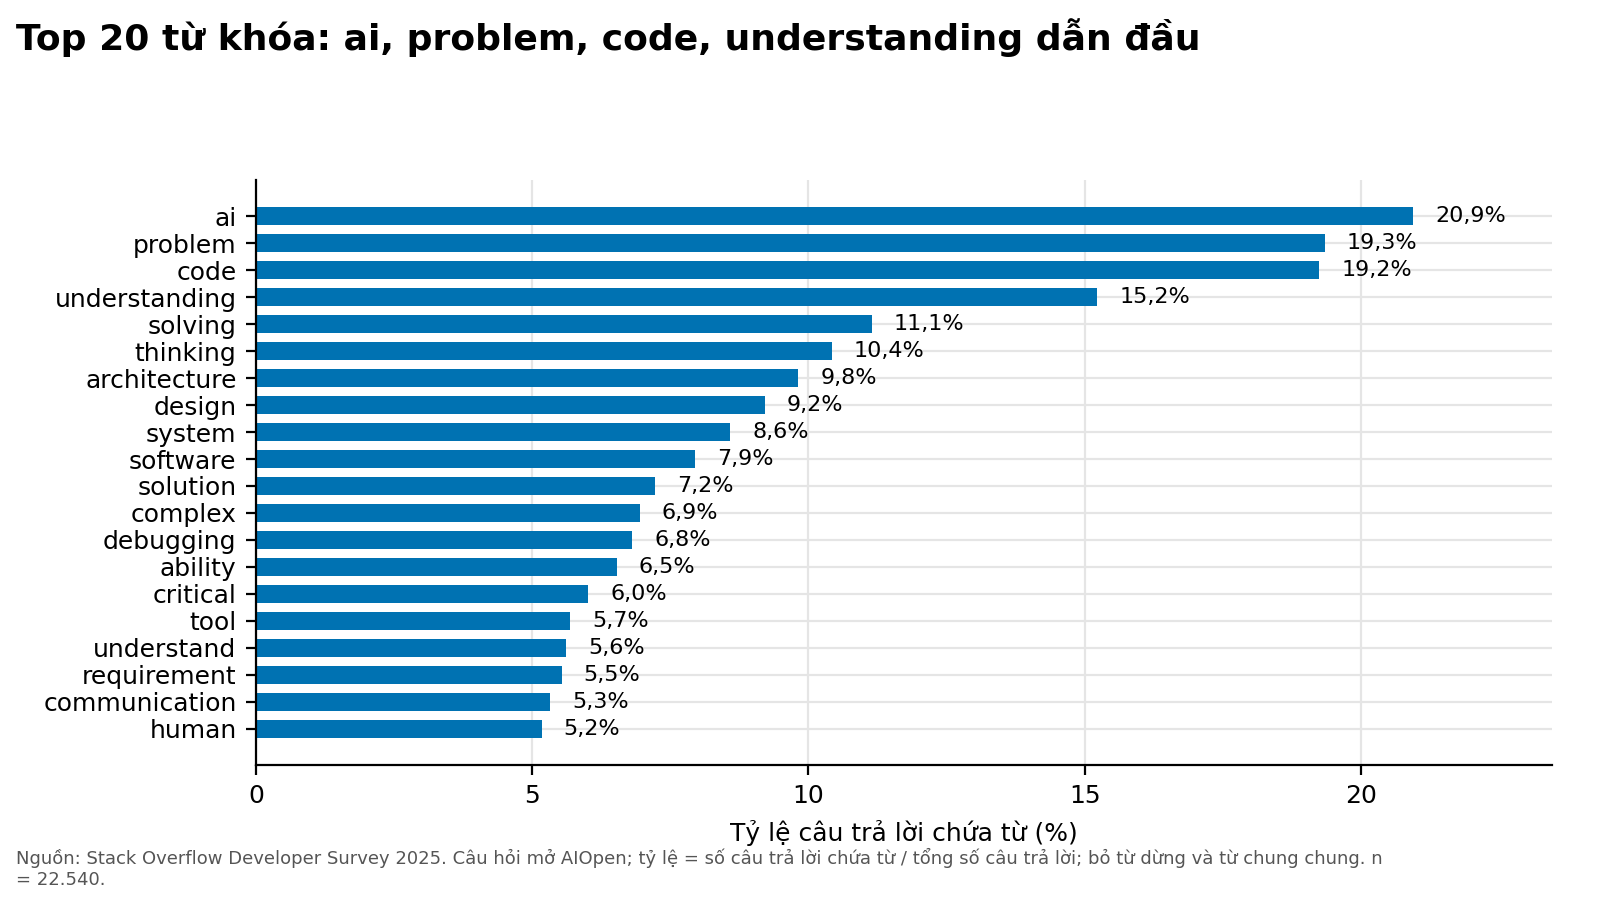

**Nhận xét.** 20 từ đầu có mặt trong từ 5,2% đến 20,9% số câu trả lời. 20 từ đầu gồm: ai, problem, code, understanding, solving, thinking, architecture, design, system, software, solution, complex, debugging, ability, critical, tool, understand, requirement, communication, human.

**Insight.** Bảng tần suất bổ sung bối cảnh cho wordcloud: tỷ lệ phần trăm cho thấy mức độ phổ biến thật của từng từ.

In [50]:
finish(*fig_f9_2(words, len(open_texts)))

## 8. Tóm tắt phát hiện, khuyến nghị và hạn chế
Các con số quan trọng được gom vào `out/tables/summary.json` để slide và báo cáo dùng đúng cùng số liệu với notebook.

In [51]:
ADM_MIN_USE = 5.0
TOP_RECS = 3


@dataclass
class Summary:
    """Các số liệu và thông điệp chính của đồ án."""
    n_all: int
    n_sal: int
    pct_pro: float
    median_pay: float
    mean_pay: float
    n_countries: int
    top_country: str
    top_country_median: float
    low_country: str
    low_country_median: float
    vn_rank: int
    vn_median: float
    vn_n: int
    r2_country: float
    r2_country_exp: float
    r2_full: float
    r2_language: float
    f_pvalue: float
    median_0_2: float
    median_21: float
    top_langs: list
    admired_langs: list
    rising_langs: list
    problem_solving_pct: float
    critical_thinking_pct: float
    ai_daily_pct: float
    ai_daily_pct_n: int
    spider_roles: list
    message: str
    recommendations: list
    limitations: list


def build_summary() -> Summary:
    """Tổng hợp số liệu từ các bảng đã tính trong notebook."""
    r2 = reg.r2.set_index("model").r2
    exp_table = median_table(df_sal.dropna(subset=[Col.EXPBIN]), Col.EXPBIN, with_ci=False).set_index(Col.EXPBIN)["median"]
    vn = by_country[by_country[Col.COUNTRY] == VIETNAM].iloc[0]
    pct_have, _ = share_answered(df_all, Col.LANG_HAVE)
    admired = lang[lang.have_pct >= ADM_MIN_USE].admired_pct.nlargest(TOP_RECS)
    rising = lang.want_gap.nlargest(TOP_RECS)
    ps_pct, ct_pct = phrase_share(open_texts, PHRASE_PROBLEM), phrase_share(open_texts, PHRASE_CRITICAL)
    ai_answered = df_all[Col.AI].dropna()
    ai_share = float((ai_answered == AI_DAILY).mean() * 100)
    first, last = exp_table.iloc[0], exp_table.iloc[-1]
    message = (f"Lương gắn với quốc gia và kinh nghiệm nhiều hơn với ngôn ngữ: quốc gia giải thích {fmt_pct(r2.iloc[2] * 100, 0)} biến thiên log(lương), "
               f"thêm kinh nghiệm lên {fmt_pct(r2.iloc[3] * 100, 0)}, thêm {REG_LANGS} ngôn ngữ chỉ cộng {fmt_num((r2.iloc[4] - r2.iloc[3]) * 100)} điểm phần trăm.")
    recs = [
        f"Bắt đầu từ nhóm ngôn ngữ phổ biến ({', '.join(pct_have.index[:3])}) vì có nhiều người dùng nhất trong mẫu khảo sát.",
        f"Theo dõi các ngôn ngữ đang được muốn dùng vượt mức đang dùng ({', '.join(rising.index)}) và các ngôn ngữ được ngưỡng mộ cao ({', '.join(admired.index)}) như hướng học thêm sau khi đã có nền tảng.",
        f"Đặt kỳ vọng lương theo kinh nghiệm: median nhóm 0–2 năm là {fmt_usd(first)}, nhóm 21+ năm là {fmt_usd(last)}; số liệu Việt Nam (median {fmt_usd(vn['median'])}, n = {int(vn['n'])}) chỉ mang tính tham khảo.",
        f"Làm quen với công cụ AI: {fmt_pct(ai_share, 0)} người trả lời dùng AI hằng ngày; cụm 'problem solving' xuất hiện trong {fmt_pct(ps_pct)} và 'critical thinking' trong {fmt_pct(ct_pct)} câu trả lời về kỹ năng còn giá trị.",
    ]
    limits = [
        "Dữ liệu tự khai báo và lệch chọn mẫu (nhiều người từ Mỹ, Đức, Ấn Độ), không đại diện cho toàn bộ thị trường lao động.",
        "Lương là USD danh nghĩa, chưa điều chỉnh sức mua; chỉ giữ lương trong khoảng 1.000–500.000 USD và lập trình viên chuyên nghiệp.",
        "Chỉ có năm 2025 nên 'xu hướng' được thay bằng ba chỉ số: đang dùng, muốn dùng, được ngưỡng mộ; không đo được thay đổi theo thời gian.",
        f"Việt Nam chỉ có {int(vn['n'])} dòng lương nên kết quả chỉ mang tính tham khảo.",
        "Hồi quy là mô hình mô tả, không chứng minh quan hệ nhân quả; số năm kinh nghiệm làm việc lớn hơn số năm lập trình ở khoảng 9% dòng có cả hai cột.",
    ]
    return Summary(
        n_all=len(df_all), n_sal=len(df_sal), pct_pro=float((df_all[Col.MAIN] == Cfg.pro_branch).mean() * 100),
        median_pay=float(df_sal[Col.SAL].median()), mean_pay=float(df_sal[Col.SAL].mean()), n_countries=len(by_country),
        top_country=short_country(by_country.iloc[0][Col.COUNTRY]), top_country_median=float(by_country.iloc[0]["median"]),
        low_country=short_country(by_country.iloc[-1][Col.COUNTRY]), low_country_median=float(by_country.iloc[-1]["median"]),
        vn_rank=int(by_country.index[by_country[Col.COUNTRY] == VIETNAM][0]) + 1, vn_median=float(vn["median"]), vn_n=int(vn["n"]),
        r2_country=float(r2.iloc[2]), r2_country_exp=float(r2.iloc[3]), r2_full=float(r2.iloc[4]), r2_language=float(r2.iloc[0]),
        f_pvalue=reg.f_pvalue, median_0_2=float(first), median_21=float(last), top_langs=list(pct_have.index[:3]),
        admired_langs=list(admired.index), rising_langs=list(rising.index), problem_solving_pct=ps_pct, critical_thinking_pct=ct_pct, ai_daily_pct=ai_share, ai_daily_pct_n=len(ai_answered), spider_roles=picked_roles,
        message=message, recommendations=recs, limitations=limits)

In [52]:
summary = build_summary()
(PATHS.tables / "summary.json").write_text(json.dumps(asdict(summary), ensure_ascii=False, indent=1), encoding="utf-8")
display(Markdown("**Thông điệp chính.** " + summary.message))
display(Markdown("**Khuyến nghị cho sinh viên và lập trình viên mới ở Việt Nam**\n\n" + "\n".join(f"{i}. {r}" for i, r in enumerate(summary.recommendations, 1))))
display(Markdown("**Hạn chế**\n\n" + "\n".join(f"- {r}" for r in summary.limitations)))

**Thông điệp chính.** Lương gắn với quốc gia và kinh nghiệm nhiều hơn với ngôn ngữ: quốc gia giải thích 45% biến thiên log(lương), thêm kinh nghiệm lên 52%, thêm 15 ngôn ngữ chỉ cộng 2,6 điểm phần trăm.

**Khuyến nghị cho sinh viên và lập trình viên mới ở Việt Nam**

1. Bắt đầu từ nhóm ngôn ngữ phổ biến (JavaScript, HTML/CSS, SQL) vì có nhiều người dùng nhất trong mẫu khảo sát.
2. Theo dõi các ngôn ngữ đang được muốn dùng vượt mức đang dùng (Rust, Go, Zig) và các ngôn ngữ được ngưỡng mộ cao (Rust, TypeScript, SQL) như hướng học thêm sau khi đã có nền tảng.
3. Đặt kỳ vọng lương theo kinh nghiệm: median nhóm 0–2 năm là 28.083 USD, nhóm 21+ năm là 111.515 USD; số liệu Việt Nam (median 11.464 USD, n = 31) chỉ mang tính tham khảo.
4. Làm quen với công cụ AI: 47% người trả lời dùng AI hằng ngày; cụm 'problem solving' xuất hiện trong 10,6% và 'critical thinking' trong 5,3% câu trả lời về kỹ năng còn giá trị.

**Hạn chế**

- Dữ liệu tự khai báo và lệch chọn mẫu (nhiều người từ Mỹ, Đức, Ấn Độ), không đại diện cho toàn bộ thị trường lao động.
- Lương là USD danh nghĩa, chưa điều chỉnh sức mua; chỉ giữ lương trong khoảng 1.000–500.000 USD và lập trình viên chuyên nghiệp.
- Chỉ có năm 2025 nên 'xu hướng' được thay bằng ba chỉ số: đang dùng, muốn dùng, được ngưỡng mộ; không đo được thay đổi theo thời gian.
- Việt Nam chỉ có 31 dòng lương nên kết quả chỉ mang tính tham khảo.
- Hồi quy là mô hình mô tả, không chứng minh quan hệ nhân quả; số năm kinh nghiệm làm việc lớn hơn số năm lập trình ở khoảng 9% dòng có cả hai cột.

In [53]:
print("Ảnh đã lưu:", len(list(PATHS.figs.glob("*.png"))), "| Bảng và chú giải:", len(list(PATHS.tables.glob("*"))))

Ảnh đã lưu: 23 | Bảng và chú giải: 47
